# Notebook 02 — MultiPatchFormer (main model): experiments, ablation, blind test and operational tests
Revised experiments for JRSE26-AR-01851 · Islamabad, Karachi, Lahore, Multan · 2020–2024

| Part | What it does | Reviewer / editor point |
|---|---|---|
| 1–3 | Data loading, duplicate-city check, clear-sky index target, calendar-year split; **intraday** (1, 3, 6 h, issued hourly) and **day-ahead** (1–28 days, issued daily) tasks | Editor (clear-sky index, hidden test year ≥ 1 yr, operational); R1-4; R2-4, R2-6, R2-7, R2-11 |
| 4 | Reference forecasts incl. **CLIPER**; skill vs CLIPER and vs smart persistence | Editor (reference forecast); R2-13 |
| 7 | MultiPatchFormer (corrected implementation, correction of CLIPER) and its physical motivation; parameters per module | Editor (physical justification); R2-2 |
| 9–11 | L chosen on validation; 3 seeds; results per city × horizon; lead time (days and hours), season, sky, hour, month; DM tests; seed ensemble | R2-4, R2-7, R2-9, R2-12; R1-7 |
| 12 | **Ablation** for all cities, one intraday and one day-ahead horizon, 3 seeds, parameter counts | R1-8; R2-2 |
| 13 | **Blind test** on an unseen city (leave-one-city-out) | Editor (multiple geographies, blind testing) |
| 14–15 | **Missing input** test; time to issue a forecast | Editor (operational aspects) |

**Kaggle settings:** Accelerator = **GPU (T4 or P100)**, Internet not needed. Add the Solcast CSV with *Add Input*.
Use **Save Version → Save & Run All (Commit)** so the run continues when the browser is closed; every cell's tables and
figures are visible in the saved version.

**Order:** run notebooks **01** and **02** (they are independent, GPU), then **03** (CPU, a few minutes) with the outputs of 01 and 02
attached. The configuration cell (`CFG`) is identical in both notebooks — keep it that way.

In [1]:
NOTEBOOK = "02_multipatchformer"

## Part 0 — Imports, environment and configuration
The configuration cell is **identical in both notebooks** (01 and 02). Change a setting in both or in neither.

In [2]:
import os, sys, json, math, time, glob, copy, random, warnings, platform, hashlib, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import stats

try:
    from IPython.display import display, Markdown
except ImportError:  # running as a plain script
    def display(x):
        print(x)
    def Markdown(x):
        return x

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.titlesize": 10,
                     "agg.path.chunksize": 20000, "axes.grid": True, "grid.alpha": 0.3})

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

def show_md(text):
    display(Markdown(text))

env_info = {
    "notebook": NOTEBOOK, "python": sys.version.split()[0], "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__, "device": str(DEVICE),
    "gpu": (f"{torch.cuda.get_device_name(0)} x{torch.cuda.device_count()}") if DEVICE.type == "cuda" else "none",
    "cuda": torch.version.cuda if DEVICE.type == "cuda" else "none",
}
display(pd.DataFrame([env_info]).T.rename(columns={0: "value"}))

,value
notebook,02_multipatchformer
python,3.13.16
platform,Linux-6.18.55+-x86_64-with-glibc2.39
numpy,2.1.3
pandas,2.3.3
torch,2.11.0+cu130
device,cuda
gpu,Tesla T4 x2
cuda,13.0


In [3]:
# =====================================================================================
# CONFIGURATION — identical in notebooks 01 and 02. Values marked >>> CHECK <<< need your input.
# =====================================================================================
IS_KAGGLE = Path("/kaggle/working").exists()

CFG = dict(
    # ---------------- paths ----------------
    DATA_PATH=os.environ.get("MPF_DATA", None),   # None = auto-detect the CSV under /kaggle/input
    OUT_DIR=os.environ.get("MPF_OUT", "/kaggle/working/outputs" if IS_KAGGLE else f"./outputs_{NOTEBOOK}"),
    RESUME_DIR=None,   # notebooks 01/02: earlier output folder (".../outputs") to skip finished runs
    # comparison step only (not used here): folders with the outputs of notebooks 01 and 02
    PREDICTION_DIRS=[p for p in os.environ.get("MPF_PRED_DIRS", "").split(":") if p] or None,
    # comparison step only (not used here): optional external models, e.g. {"PathFormer": {24: "/kaggle/input/x/pathformer_H24.csv"}}
    EXTERNAL_PREDICTIONS={},

    # ---------------- data period and split (calendar years, local time) ----------------
    UTC_OFFSET_HOURS=5,          # Pakistan Standard Time = UTC+5 (no daylight saving)
    DATA_YEARS=(2020, 2024),     # only 2020–2024 are used (2025 is incomplete)
    TRAIN_YEARS=(2020, 2022),    # 3 years
    VAL_YEARS=(2023, 2023),      # 1 year: early stopping + input-length selection
    TEST_YEARS=(2024, 2024),     # 1 full hidden year: used once, for the final numbers
    MAX_GAP_FILL_HOURS=3,        # short gaps are linearly interpolated; longer gaps make windows invalid

    # ---------------- forecasting task ----------------
    ISSUE_HOUR_LOCAL=0,          # validation/test forecasts are issued once per day at 00:00 local time
    # Two forecasting tasks (both on the same hidden test year):
    #  * intraday  (H < 24 h): issued EVERY HOUR during the day, horizons 1, 3, 6 h
    #  * day-ahead and longer (H >= 24 h): issued once per day at 00:00 local, horizons 1, 4, 7, 14, 28 days
    TRAIN_STRIDE_H=3,            # day-ahead training windows: one every 3 h
    TRAIN_STRIDE_INTRADAY_H=2,   # intraday training windows: one every 2 h
    EVAL_STRIDE_H=24,            # day-ahead validation/test windows: one per day (intraday: every hour)
    INPUT_LENGTHS=[96, 168, 336, 672],     # day-ahead: hours of history searched (selected on validation)
    INTRADAY_INPUT_LENGTHS=[24, 72, 168],      # intraday: hours of history searched (selected on validation)
    HORIZONS=[1, 3, 6, 24, 96, 168, 336, 672], # hours ahead
    RESIDUAL_ON_REFERENCE=True,  # every learning model predicts a correction to the CLIPER reference (same for all models)
    TRAINING_MODE="global",      # "global": one model trained on all cities (4x more data); "per_city": one model per city
    CS_MIN=20.0,                 # W/m2: hours with clear-sky GHI below this are night/low sun (not scored)
    K_MAX=1.4,                   # upper bound of the clear-sky index (allows cloud enhancement)

    # ---------------- models and training (same protocol for every model) ----------------
    MAIN_MODEL="MultiPatchFormer",
    BASELINE_MODELS=["PatchTST", "DLinear", "LSTM"],
    SEEDS=[0, 1, 2],             # final runs: mean ± std over these seeds
    BATCH_SIZE=256,
    MAX_EPOCHS=40,
    PATIENCE=5,                  # early stopping on validation RMSE
    TIME_BUDGET_HOURS=11.3,      # Kaggle stops sessions at 12 h: stop cleanly before that (finished runs stay saved)
    LR={"MultiPatchFormer": 3e-4, "PatchTST": 3e-4, "DLinear": 1e-3, "LSTM": 1e-3},
    WEIGHT_DECAY=1e-2,
    GRAD_CLIP=1.0,
    USE_AMP=True,                # mixed precision on GPU (faster)
    MPF=dict(d_model=128, scales=[6, 12, 24, 48], patch_stride=6, n_heads=8, n_layers=2,
             ff_mult=2, dropout=0.2, decoder_segments=4, single_scale=24),
    PATCHTST=dict(patch_len=24, stride=12, d_model=128, n_heads=8, n_layers=3, ff_mult=2, dropout=0.3),
    DLINEAR=dict(kernel=25),
    LSTM=dict(hidden=128, layers=2, dropout=0.1),

    # ---------------- extra experiments (notebook 02) ----------------
    ABLATION_HORIZONS=[6, 24],
    LOCO_HORIZONS=[6, 24],       # leave-one-city-out blind test
    ROBUST_HORIZONS=[6, 24],     # missing-variable test
    BREAKDOWN_HORIZON=24,        # season / sky / hour / month analysis: day-ahead forecasts …
    INTRADAY_BREAKDOWN_HORIZON=1,  # … and 1-hour-ahead forecasts
    ALLOW_DUPLICATE_REGIONS=False,

    # ---------------- sites (>>> CHECK: exact values used for the Solcast download) ----------------
    SITE_INFO={
        "Islamabad": dict(lat=33.699509, lon=73.03629, elev_m=540, koppen="Cwa (humid subtropical)"),
        "Karachi":   dict(lat=24.860734, lon=67.001136, elev_m=10,  koppen="BWh (hot desert, coastal)"),
        "Lahore":    dict(lat=31.52037,  lon=74.358747, elev_m=217, koppen="BSh (hot semi-arid)"),
        "Multan":    dict(lat=30.186356, lon=71.488581, elev_m=122, koppen="BWh (hot desert)"),
    },

    # ---------------- PV and economics, comparison step only (values reported in the paper) ----------------
    ECON=dict(
        PV_KWP=10.0,             # kWp (DC rating at STC, 1 kW/m2)
        PR=0.78,                 # performance ratio (all losses incl. inverter, temperature, soiling, wiring)
        TARIFF_PKR=34.00,        # PKR/kWh, NEPRA national average tariff FY2025-26
        CAPEX_PKR=1_200_000,     # PKR for 10 kW (IEEFA 2024: PKR 120,000/kW)
        PKR_PER_USD=279.0,       # State Bank of Pakistan M2M rate, mean of Jan-Jun 2026 (not used in notebooks 01-02)
        SOURCE_NOTE="Economics are NOT computed in notebooks 01-02; the paper values come from scripts/pv_energy.py and scripts/economics.py",
        SCENARIOS={
            "Conservative": dict(PR=0.70, TARIFF_PKR=27.00, CAPEX_PKR=1_800_000),
            "Base":         dict(PR=0.78, TARIFF_PKR=34.00, CAPEX_PKR=1_200_000),
            "Optimistic":   dict(PR=0.85, TARIFF_PKR=45.00, CAPEX_PKR=1_200_000),
        },
    ),
    QUICK_TEST=os.environ.get("MPF_QUICK", "0") == "1",   # only for a smoke test of the code; keep False
)

if CFG["QUICK_TEST"]:   # tiny settings to check that every cell runs (NOT for the paper)
    CFG.update(INPUT_LENGTHS=[96, 168], INTRADAY_INPUT_LENGTHS=[24, 72], HORIZONS=[1, 6, 24, 48], SEEDS=[0, 1],
               MAX_EPOCHS=2, PATIENCE=1, ABLATION_HORIZONS=[6, 24], LOCO_HORIZONS=[6], ROBUST_HORIZONS=[6, 24],
               BREAKDOWN_HORIZON=24, INTRADAY_BREAKDOWN_HORIZON=1)
    CFG["MPF"] = dict(CFG["MPF"], d_model=32, n_heads=4, n_layers=1)
    CFG["PATCHTST"] = dict(CFG["PATCHTST"], d_model=32, n_heads=4, n_layers=1)
    CFG["LSTM"] = dict(CFG["LSTM"], hidden=32, layers=1)

OUT = Path(CFG["OUT_DIR"])
for sub in ["tables", "figures", "runs", "weights", "predictions"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
if CFG["RESUME_DIR"] and Path(CFG["RESUME_DIR"]).exists():
    for sub in ["runs", "weights"]:
        src = Path(CFG["RESUME_DIR"]) / sub
        if src.exists():
            for f in src.iterdir():
                if not (OUT / sub / f.name).exists():
                    shutil.copy(f, OUT / sub / f.name)
    print("Resumed finished runs from", CFG["RESUME_DIR"])

with open(OUT / "config.json", "w") as f:
    json.dump(CFG, f, indent=2, default=str)

ALL_TABLES = {}   # every table shown is also written to CSV and to one Excel file at the end
FIG_COUNT = [0]

def save_table(df, name, show=True, caption=None):
    df = df.reset_index(drop=True) if not isinstance(df.index, pd.RangeIndex) else df
    if isinstance(df.columns, pd.MultiIndex):     # flatten e.g. ("dRMSE_pct", 24, "Lahore") -> "dRMSE_pct_24_Lahore"
        df = df.copy()
        df.columns = ["_".join(str(x) for x in col if str(x) != "") for col in df.columns]
    ALL_TABLES[name] = df
    df.to_csv(OUT / "tables" / f"{name}.csv", index=False)
    if show:
        if caption:
            show_md(f"**{name} — {caption}**")
        display(df)
    return df

def save_fig(fig, name, caption=None):
    FIG_COUNT[0] += 1
    fig.savefig(OUT / "figures" / f"{name}.png", bbox_inches="tight")
    if caption:
        show_md(f"*{name} — {caption}*")
    plt.show()
    plt.close(fig)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def input_lengths(H):
    """Input lengths searched for horizon H (intraday tasks use shorter histories)."""
    return CFG["INTRADAY_INPUT_LENGTHS"] if H < 24 else CFG["INPUT_LENGTHS"]

def hlabel(H):
    return f"{H} h" if H < 24 else f"{H / 24:g} d"

INTRADAY_H = [h for h in CFG["HORIZONS"] if h < 24]
DAILY_H = [h for h in CFG["HORIZONS"] if h >= 24]

def grid(nr, nc, w=4.2, h=3.4, **kw):
    fig, axes = plt.subplots(nr, nc, figsize=(w * nc, h * nr), squeeze=False, **kw)
    return fig, axes

T0_NOTEBOOK = time.time()
print("Notebook:", NOTEBOOK, "| outputs folder:", OUT.resolve(), "| quick smoke-test mode:", CFG["QUICK_TEST"])

Notebook: 02_multipatchformer | outputs folder: /kaggle/working/outputs | quick smoke-test mode: False


## Part 1 — Load the Solcast dataset and check that every city has its own data

In [4]:
DATA_SECTION = NOTEBOOK.startswith("03")   # False here: only the main data checks are shown

def find_dataset():
    if CFG["DATA_PATH"]:
        return CFG["DATA_PATH"]
    cands = []
    for r in ["/kaggle/input", "."]:
        cands += glob.glob(os.path.join(r, "**", "*.csv"), recursive=True)
    cands = sorted(set(cands), key=lambda p: -os.path.getsize(p))
    for p in cands:
        try:
            cols = [c.strip() for c in pd.read_csv(p, nrows=3).columns]
        except Exception:
            continue
        if "ghi" in cols and "Region" in cols and "clearsky_ghi" in cols:
            return p
    raise FileNotFoundError("No CSV with columns ghi, clearsky_ghi and Region found. Set CFG['DATA_PATH'].")

DATA_PATH = find_dataset()
raw = pd.read_csv(DATA_PATH)
raw.columns = [c.strip() for c in raw.columns]
print("Dataset file:", DATA_PATH)
print("Raw shape:", raw.shape)
print("Columns:", raw.columns.tolist())

time_col = "period_end" if "period_end" in raw.columns else "period"
t_utc = pd.to_datetime(raw[time_col], utc=True, errors="coerce", format="ISO8601")
if t_utc.isna().mean() > 0.01:   # fall back to automatic parsing (e.g. Excel-style dates)
    t_utc = pd.to_datetime(raw[time_col], utc=True, errors="coerce")
raw["time_utc"] = t_utc.dt.tz_convert(None)
raw["time_local"] = raw["time_utc"] + pd.Timedelta(hours=CFG["UTC_OFFSET_HOURS"])   # period END, local time
raw["start_local"] = raw["time_local"] - pd.Timedelta(hours=1)                      # period START (dates/years use this)
raw["Region"] = raw["Region"].astype(str).str.strip()
print("Rows with unreadable timestamps:", int(raw["time_utc"].isna().sum()))
raw = raw.dropna(subset=["time_utc"])

NUM_COLS = ["air_temp", "clearsky_dhi", "clearsky_dni", "clearsky_ghi", "clearsky_gti", "dhi", "dni",
            "ghi", "gti", "relative_humidity", "wind_direction_10m", "wind_speed_10m"]
NUM_COLS = [c for c in NUM_COLS if c in raw.columns]
for c in NUM_COLS:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

overview = raw.groupby("Region").agg(rows=("ghi", "size"), first_utc=("time_utc", "min"),
                                     last_utc=("time_utc", "max")).reset_index()
save_table(overview, "D00_raw_file_overview", caption="Raw file overview (all years in the file)")

Dataset file: /kaggle/input/datasets/jjajajassff/solcast-dataset-2020-2024/Solcast_4cities_2020_2024_corrected.csv
Raw shape: (174533, 15)
Columns: ['air_temp', 'clearsky_dhi', 'clearsky_dni', 'clearsky_ghi', 'clearsky_gti', 'dhi', 'dni', 'ghi', 'gti', 'relative_humidity', 'wind_direction_10m', 'wind_speed_10m', 'period_end', 'period', 'Region']
Rows with unreadable timestamps: 0


**D00_raw_file_overview — Raw file overview (all years in the file)**

,Region,rows,first_utc,last_utc
0,Islamabad,43824,2019-12-31 20:00:00,2024-12-31 19:00:00
1,Karachi,43061,2019-12-31 20:00:00,2024-11-29 00:00:00
2,Lahore,43824,2019-12-31 20:00:00,2024-12-31 19:00:00
3,Multan,43824,2019-12-31 20:00:00,2024-12-31 19:00:00


,Region,rows,first_utc,last_utc
0,Islamabad,43824,2019-12-31 20:00:00,2024-12-31 19:00:00
1,Karachi,43061,2019-12-31 20:00:00,2024-11-29 00:00:00
2,Lahore,43824,2019-12-31 20:00:00,2024-12-31 19:00:00
3,Multan,43824,2019-12-31 20:00:00,2024-12-31 19:00:00


In [5]:
piv = raw.pivot_table(index="time_utc", columns="Region", values="ghi", aggfunc="first")
regs = list(piv.columns)
dup_rows, duplicate_pairs = [], []
for i in range(len(regs)):
    for j in range(i + 1, len(regs)):
        a, b = piv[regs[i]], piv[regs[j]]
        ok = a.notna() & b.notna()
        same = float((a[ok] == b[ok]).mean()) if ok.any() else np.nan
        corr = float(np.corrcoef(a[ok], b[ok])[0, 1]) if ok.sum() > 2 else np.nan
        dup = bool(same > 0.99)
        dup_rows.append(dict(region_A=regs[i], region_B=regs[j], identical_hours_pct=100 * same,
                             correlation=corr, duplicate=dup))
        if dup:
            duplicate_pairs.append((regs[i], regs[j]))
save_table(pd.DataFrame(dup_rows), "D01_duplicate_region_check", caption="Pairwise GHI comparison between regions")
if duplicate_pairs and not CFG["ALLOW_DUPLICATE_REGIONS"]:
    raise ValueError(f"Identical data found for {duplicate_pairs}. Download the correct data for one of these "
                     "cities before running the experiments (reviewer 2, comment 11).")
if duplicate_pairs:
    print(f"WARNING: identical data for {duplicate_pairs}. These cities will give identical results "
          "(ALLOW_DUPLICATE_REGIONS=True). Replace one of them with its real data before the final paper runs.")
else:
    print("Check passed: every city has its own data.")

**D01_duplicate_region_check — Pairwise GHI comparison between regions**

,region_A,region_B,identical_hours_pct,correlation,duplicate
0,Islamabad,Karachi,45.8419,0.8876,False
1,Islamabad,Lahore,47.7661,0.9249,False
2,Islamabad,Multan,47.2892,0.9227,False
3,Karachi,Lahore,45.2428,0.8985,False
4,Karachi,Multan,45.9534,0.9302,False
5,Lahore,Multan,46.7826,0.9359,False


Check passed: every city has its own data.


## Part 2 — Study period (2020–2024), gaps, quality control, clear-sky index and inputs

* Each hourly value is dated by the **start** of its hour (Solcast `period_end` − 1 h), local time (UTC+5).
* Gaps of ≤ 3 h are interpolated. Longer gaps (e.g. the missing 29–30 Nov 2024) are filled with the same hours of the previous day
  **for model inputs only** — those hours are never scored and never enter the training loss, so every model keeps the same test days.
* Target: `k = GHI / GHI_clear-sky` (clipped to `[0, K_MAX]`). Hours with clear-sky GHI < `CS_MIN` are night/low sun and are not scored.
* Models predict `k`; the GHI forecast is `k̂ × GHI_clear-sky` (clear-sky GHI is known in advance). Negative or above-clear-sky
  forecasts are therefore impossible. The training loss is the daytime MSE of the reconstructed GHI.
* All inputs are **past values only** (up to the forecast issue time).

In [6]:
def cos_zenith(times_utc, lat, lon):
    """NOAA solar-position approximation. times_utc = period mid-point (UTC)."""
    t = pd.DatetimeIndex(times_utc)
    doy = t.dayofyear.values
    hr = t.hour.values + t.minute.values / 60.0
    g = 2 * np.pi / 365.0 * (doy - 1 + (hr - 12) / 24.0)
    eqt = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                    - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    decl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g)
            + 0.000907 * np.sin(2 * g) - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    ha = np.radians((hr * 60 + eqt + 4 * lon) / 4.0 - 180.0)
    la = np.radians(lat)
    return np.sin(la) * np.sin(decl) + np.cos(la) * np.cos(decl) * np.cos(ha)

FEATURES = ["k", "dni", "dhi", "gti", "clearsky_ghi", "air_temp", "relative_humidity", "wind_speed_10m",
            "wind_dir_sin", "wind_dir_cos", "hour_sin", "hour_cos", "doy_sin", "doy_cos"]
FEATURE_INFO = {
    "k":                 ("Clear-sky index GHI/GHI_cs (past)", "-", "Observed (satellite-derived estimate)", "Solcast live estimated actuals, ~5–15 min latency"),
    "dni":               ("Direct normal irradiance (past)", "W/m²", "Observed (satellite-derived estimate)", "Solcast live estimated actuals"),
    "dhi":               ("Diffuse horizontal irradiance (past)", "W/m²", "Observed (satellite-derived estimate)", "Solcast live estimated actuals"),
    "gti":               ("Global tilted irradiance (past)", "W/m²", "Observed (satellite-derived estimate)", "Solcast live estimated actuals"),
    "clearsky_ghi":      ("Clear-sky GHI (past window)", "W/m²", "Deterministic", "Clear-sky model, known for any time"),
    "air_temp":          ("Air temperature (past)", "°C", "Observed (NWP/reanalysis-based)", "Solcast live / weather service"),
    "relative_humidity": ("Relative humidity (past)", "%", "Observed (NWP/reanalysis-based)", "Solcast live / weather service"),
    "wind_speed_10m":    ("Wind speed at 10 m (past)", "m/s", "Observed (NWP/reanalysis-based)", "Solcast live / weather service"),
    "wind_dir_sin":      ("sin(wind direction) (past)", "-", "Observed (NWP/reanalysis-based)", "Solcast live / weather service"),
    "wind_dir_cos":      ("cos(wind direction) (past)", "-", "Observed (NWP/reanalysis-based)", "Solcast live / weather service"),
    "hour_sin":          ("sin(hour of day, local)", "-", "Deterministic", "Calendar"),
    "hour_cos":          ("cos(hour of day, local)", "-", "Deterministic", "Calendar"),
    "doy_sin":           ("sin(day of year)", "-", "Deterministic", "Calendar"),
    "doy_cos":           ("cos(day of year)", "-", "Deterministic", "Calendar"),
}

y0, y1 = CFG["DATA_YEARS"]
CITY_DF, qc_rows = {}, []
for city in sorted(raw["Region"].unique()):
    d = raw[raw["Region"] == city].copy()
    d = d[(d["start_local"].dt.year >= y0) & (d["start_local"].dt.year <= y1)]
    n_dup_ts = int(d["time_utc"].duplicated().sum())
    d = d.drop_duplicates("time_utc").set_index("time_utc").sort_index()
    full_idx = pd.date_range(f"{y0}-01-01 01:00", f"{y1 + 1}-01-01 00:00", freq="h") - pd.Timedelta(hours=CFG["UTC_OFFSET_HOURS"])
    missing_before = int(len(full_idx.difference(d.index)))
    d = d.reindex(full_idx)
    nan_cells_before = int(d[NUM_COLS].isna().sum().sum())
    wd = np.radians(d["wind_direction_10m"])            # circular variable: interpolate sin/cos
    d["wind_dir_sin"], d["wind_dir_cos"] = np.sin(wd), np.cos(wd)
    fill_cols = [c for c in NUM_COLS if c != "wind_direction_10m"] + ["wind_dir_sin", "wind_dir_cos"]
    d[fill_cols] = d[fill_cols].interpolate(limit=CFG["MAX_GAP_FILL_HOURS"], limit_area="inside")
    # Longer gaps (e.g. a missing day): copy the same hours of the previous (or next) day so that model INPUTS stay
    # available. These hours are flagged and are never scored and never used in the training loss.
    long_gap = d[fill_cols].isna().any(axis=1)
    for _ in range(7):
        d[fill_cols] = d[fill_cols].fillna(d[fill_cols].shift(24))
    for _ in range(7):
        d[fill_cols] = d[fill_cols].fillna(d[fill_cols].shift(-24))
    d["valid"] = d[fill_cols].notna().all(axis=1)
    d["gap_filled"] = long_gap & d["valid"]
    d.index.name = "time_utc"
    d = d.reset_index()
    d["time_local"] = d["time_utc"] + pd.Timedelta(hours=CFG["UTC_OFFSET_HOURS"])
    d["start_local"] = d["time_local"] - pd.Timedelta(hours=1)
    d["Region"] = city
    site = CFG["SITE_INFO"].get(city, dict(lat=np.nan, lon=np.nan))
    cz = cos_zenith(d["time_utc"] - pd.Timedelta(minutes=30), site["lat"], site["lon"])
    sun_up = cz > np.cos(np.radians(85))
    closure = (d["ghi"] / (d["dhi"] + d["dni"] * np.clip(cz, 0, None))).replace([np.inf, -np.inf], np.nan)
    cl = closure[sun_up & (d["ghi"] > 50)]
    cs_day = d["clearsky_ghi"] >= CFG["CS_MIN"]
    qc_rows.append(dict(
        Region=city, period_local=f"{d['start_local'].min():%Y-%m-%d %H:%M} – {d['time_local'].max():%Y-%m-%d %H:%M}",
        expected_hours=len(full_idx), missing_hours=missing_before, duplicate_timestamps=n_dup_ts,
        missing_cells_before_fill=nan_cells_before, long_gap_hours_filled_not_scored=int(d["gap_filled"].sum()),
        invalid_hours_after_fill=int((~d["valid"]).sum()),
        negative_ghi=int((d["ghi"] < 0).sum()), negative_dni_dhi=int(((d["dni"] < 0) | (d["dhi"] < 0)).sum()),
        ghi_gt_1p4_clearsky=int((cs_day & (d["ghi"] > 1.4 * d["clearsky_ghi"])).sum()),
        ghi_gt_1400=int((d["ghi"] > 1400).sum()),
        night_ghi_gt_5=int(((d["clearsky_ghi"] <= 0) & (d["ghi"] > 5)).sum()),
        closure_median_ratio=float(np.nanmedian(cl)) if len(cl) else np.nan,
        closure_within_10pct=float(100 * np.nanmean(np.abs(cl - 1) <= 0.10)) if len(cl) else np.nan,
    ))
    # clear-sky index and inputs
    cs = d["clearsky_ghi"].clip(lower=0)
    d["clearsky_ghi"] = cs
    d["ghi"] = d["ghi"].clip(lower=0)
    d["day"] = (cs >= CFG["CS_MIN"]) & d["valid"] & ~d["gap_filled"]     # scored hours only
    d["k"] = np.where(cs >= CFG["CS_MIN"], np.clip(d["ghi"] / cs.replace(0, np.nan), 0, CFG["K_MAX"]), 0.0)
    d["k"] = d["k"].fillna(0.0)
    hr = d["start_local"].dt.hour + 0.5          # middle of the hourly period
    doy = d["start_local"].dt.dayofyear
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24)
    d["doy_sin"], d["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    for f in FEATURES:
        d[f] = d[f].astype(np.float32)
    CITY_DF[city] = d
CITIES = list(CITY_DF.keys())
QC_DF = pd.DataFrame(qc_rows)
FEAT_DF = pd.DataFrame([dict(channel=i, feature=f, description=FEATURE_INFO[f][0], unit=FEATURE_INFO[f][1],
                             type=FEATURE_INFO[f][2], operational_availability=FEATURE_INFO[f][3],
                             time_used="t-L+1 … t (issue time)") for i, f in enumerate(FEATURES)])
if DATA_SECTION:
    save_table(QC_DF, "D02_quality_control",
               caption="Quality control per region (2020–2024). Closure = GHI / (DHI + DNI·cos z) for zenith < 85° and GHI > 50 W/m²")
    save_table(FEAT_DF, "D05_input_variables", caption="Model inputs (all past-only; the forecast is issued at time t)")
else:
    display(QC_DF[["Region", "period_local", "missing_hours", "long_gap_hours_filled_not_scored", "invalid_hours_after_fill",
                   "negative_ghi", "closure_median_ratio"]])
print("Cities:", CITIES, "| input channels C =", len(FEATURES))

,Region,period_local,missing_hours,long_gap_hours_filled_not_scored,invalid_hours_after_fill,negative_ghi,closure_median_ratio
0,Islamabad,2020-01-01 00:00 – 2025-01-01 00:00,24,21,0,0,1.0000
1,Karachi,2020-01-01 00:00 – 2025-01-01 00:00,787,168,619,0,1.0000
2,Lahore,2020-01-01 00:00 – 2025-01-01 00:00,24,21,0,0,1.0000
3,Multan,2020-01-01 00:00 – 2025-01-01 00:00,24,21,0,0,1.0000


Cities: ['Islamabad', 'Karachi', 'Lahore', 'Multan'] | input channels C = 14


## Part 3 — Chronological split and forecast windows
A window issued at hour index `i` uses inputs `i-L+1 … i` and predicts `i+1 … i+H`. A window belongs to a split only if **all its
target hours** are inside that split's years (inputs may use earlier, already-observed hours). Scalers use training years only.
* **Intraday task (H = 1, 3, 6 h):** a forecast is issued **every hour**; only forecasts with at least one daytime target hour are used.
* **Day-ahead task (H ≥ 24 h):** one forecast per day, issued at 00:00 local time (366 test forecasts for 2024).

In [7]:
def years_mask(tl, yrs):
    y = tl.dt.year.values
    return (y >= yrs[0]) & (y <= yrs[1])

class CityArrays:
    def __init__(self, d):
        self.time_local = d["time_local"].reset_index(drop=True)      # period end
        self.start_local = d["start_local"].reset_index(drop=True)    # period start
        self.X = d[FEATURES].to_numpy(np.float32)
        self.ghi = d["ghi"].fillna(0).to_numpy(np.float32)
        self.cs = d["clearsky_ghi"].fillna(0).to_numpy(np.float32)
        self.k = d["k"].to_numpy(np.float32)
        self.day = d["day"].to_numpy(bool)
        self.valid = d["valid"].to_numpy(bool)
        self.hour = self.time_local.dt.hour.to_numpy()          # end hour: data up to this hour are known at issue
        self.hour_start = self.start_local.dt.hour.to_numpy()   # hour of day of the period (0–23)
        self.month = self.start_local.dt.month.to_numpy()
        self.split = np.full(len(d), "", dtype=object)
        for name, yrs in [("train", CFG["TRAIN_YEARS"]), ("val", CFG["VAL_YEARS"]), ("test", CFG["TEST_YEARS"])]:
            self.split[years_mask(self.start_local, yrs)] = name
        self.train_rows = (self.split == "train") & self.valid
        self.bad_cum = np.concatenate([[0], np.cumsum(~self.valid)])   # O(1) window validity checks
        self.day_cum = np.concatenate([[0], np.cumsum(self.day)])       # O(1) "any daytime target" checks
        self._cache = {}

    def windows(self, split, L, H):
        key = (split, L, H)
        if key in self._cache:
            return self._cache[key]
        n = len(self.ghi)
        i = np.arange(L - 1, n - H)
        ok = (self.bad_cum[i + H + 1] - self.bad_cum[i - L + 1]) == 0
        ok &= (self.split[i + 1] == split) & (self.split[i + H] == split)
        if H < 24:                                    # intraday: issued every hour, at least one daytime target hour
            ok &= (self.day_cum[i + H + 1] - self.day_cum[i + 1]) > 0
            if split == "train":
                ok &= (self.hour[i] % CFG["TRAIN_STRIDE_INTRADAY_H"]) == 0
        elif split == "train":
            ok &= (self.hour[i] % CFG["TRAIN_STRIDE_H"]) == (CFG["ISSUE_HOUR_LOCAL"] % CFG["TRAIN_STRIDE_H"])
        else:
            ok &= self.hour[i] == CFG["ISSUE_HOUR_LOCAL"]
        out = i[ok]
        self._cache[key] = out
        return out

ARR = {c: CityArrays(CITY_DF[c]) for c in CITIES}

split_rows = []
for c in CITIES:
    a = ARR[c]
    for sp in ["train", "val", "test"]:
        rows = a.split == sp
        tl = a.start_local[rows]
        split_rows.append(dict(Region=c, split=sp, period=f"{tl.min():%Y-%m-%d} – {tl.max():%Y-%m-%d}",
                               hours=int(rows.sum()), daytime_hours=int((rows & a.day).sum()),
                               **{f"forecasts H={hlabel(H)}": len(a.windows(sp, input_lengths(H)[-1], H)) for H in CFG["HORIZONS"]}))
save_table(pd.DataFrame(split_rows), "D06_data_split",
           caption=f"Chronological split and number of forecasts. Intraday: issued every hour (training stride {CFG['TRAIN_STRIDE_INTRADAY_H']} h); "
                   f"day-ahead: one per day at {CFG['ISSUE_HOUR_LOCAL']:02d}:00 local (training stride {CFG['TRAIN_STRIDE_H']} h)")

for c in CITIES:   # every model and input length is scored on exactly the same test forecasts
    for H in CFG["HORIZONS"]:
        sets = [tuple(ARR[c].windows("test", L, H)) for L in input_lengths(H)]
        assert all(s == sets[0] for s in sets), f"test windows differ across L for {c}, H={H}"
print("Check passed: identical test forecasts for every input length and model.")

**D06_data_split — Chronological split and number of forecasts. Intraday: issued every hour (training stride 2 h); day-ahead: one per day at 00:00 local (training stride 3 h)**

,Region,split,period,hours,daytime_hours,forecasts H=1 h,forecasts H=3 h,forecasts H=6 h,forecasts H=1 d,forecasts H=4 d,forecasts H=7 d,forecasts H=14 d,forecasts H=28 d
0,Islamabad,train,2020-01-01 – 2022-12-31,26304,12962,6487,7576,9315,8537,8513,8489,8433,8321
1,Islamabad,val,2023-01-01 – 2023-12-31,8760,4311,4311,5041,6136,365,362,359,352,338
2,Islamabad,test,2024-01-01 – 2024-12-31,8784,4321,4321,5051,6146,366,363,360,353,339
3,Karachi,train,2020-01-01 – 2022-12-31,26304,13035,6453,7542,9229,8537,8513,8489,8433,8321
4,Karachi,val,2023-01-01 – 2023-12-31,8760,4350,4350,5080,6175,365,362,359,352,338
5,Karachi,test,2024-01-01 – 2024-12-31,8784,3985,3985,4651,5650,340,337,334,327,313
6,Lahore,train,2020-01-01 – 2022-12-31,26304,12886,6425,7514,9235,8537,8513,8489,8433,8321
7,Lahore,val,2023-01-01 – 2023-12-31,8760,4300,4300,5030,6125,365,362,359,352,338
8,Lahore,test,2024-01-01 – 2024-12-31,8784,4300,4300,5030,6125,366,363,360,353,339
9,Multan,train,2020-01-01 – 2022-12-31,26304,12788,6459,7548,9110,8537,8513,8489,8433,8321


Check passed: identical test forecasts for every input length and model.


## Part 4 — Metrics, statistical test and reference forecasts

All scores use **daytime hours only** (clear-sky GHI ≥ `CS_MIN`), in W/m². nRMSE = RMSE / mean observed daytime GHI.
Skill scores: `Skill_pct = 1 − RMSE_model / RMSE_CLIPER` and `Skill_SP_pct = 1 − RMSE_model / RMSE_smart-persistence` (in %).

Reference forecasts (no training): **Seasonal persistence** (last observed day of GHI repeated), **Smart persistence** (clear-sky index
persistence × future clear-sky GHI: intraday = the k of the issue hour, or the same hour of the previous day before sunrise; day-ahead =
the last observed day of k), **Climatology** (mean k per month × hour of the training years) and **CLIPER** — the optimal convex
combination of climatology and persistence, `k̂ = α_h·k_persistence + (1−α_h)·k_climatology`, with `α_h` fitted for each lead hour on
the training years, separately for the intraday and day-ahead tasks (Yang, 2019; Yang et al., 2020).
CLIPER is the main reference for skill scores. With `RESIDUAL_ON_REFERENCE=True` every learning model predicts a correction to CLIPER.

*02_F00_cliper_alpha — CLIPER weight on persistence by lead time (fitted on the training years)*

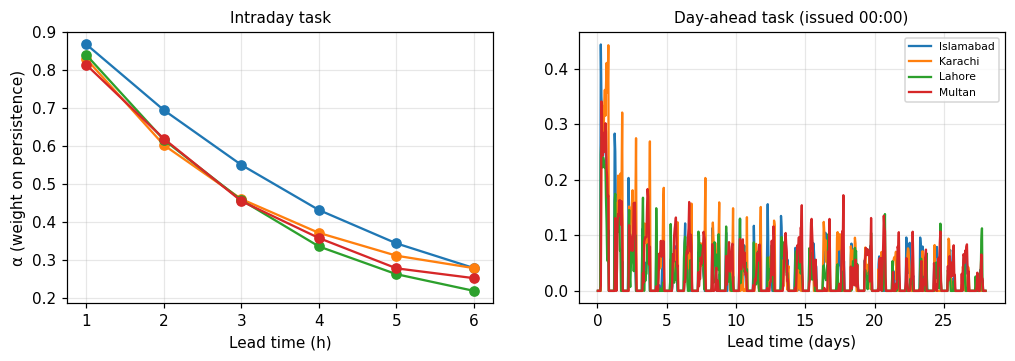

In [8]:
MET = ["RMSE", "MAE", "MBE", "nRMSE_pct", "R2", "Skill_pct", "Skill_SP_pct"]

def metrics(y, p, m):
    """y, p, m: arrays of the same shape; m = 1 for scored daytime hours."""
    m = m.astype(bool)
    y, p = y[m].astype(np.float64), p[m].astype(np.float64)
    e = p - y
    rmse = float(np.sqrt(np.mean(e ** 2)))
    return dict(RMSE=rmse, MAE=float(np.mean(np.abs(e))), MBE=float(np.mean(e)),
                nRMSE_pct=100 * rmse / float(np.mean(y)), R2=float(1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2)))

def test_targets(city, H):
    a = ARR[city]
    i = a.windows("test", input_lengths(H)[0], H)
    out = i[:, None] + np.arange(1, H + 1)
    return i, a.ghi[out], a.cs[out], a.day[out]

def dm_test(loss_a, loss_b, h):
    """Diebold–Mariano test (Newey–West variance, Harvey et al. small-sample correction).
    loss_* = one value per daily forecast; h = overlap of consecutive forecasts in days."""
    d = np.asarray(loss_a, float) - np.asarray(loss_b, float)
    T = len(d)
    dc = d - d.mean()
    lag = max(0, min(h - 1, T - 2))
    v = np.sum(dc * dc) / T
    for k in range(1, lag + 1):
        v += 2 * (1 - k / (lag + 1)) * np.sum(dc[k:] * dc[:-k]) / T
    dm = d.mean() / np.sqrt(max(v, 1e-12) / T)
    dm *= np.sqrt(max((T + 1 - 2 * h + h * (h - 1) / T) / T, 1e-6))
    return float(dm), float(2 * stats.t.sf(abs(dm), df=T - 1))

HMAX = max(CFG["HORIZONS"])

def k_climatology(city):
    a = ARR[city]
    m = a.train_rows & a.day
    tab = pd.DataFrame({"month": a.month[m], "hour": a.hour_start[m], "k": a.k[m]}).groupby(["month", "hour"])["k"].mean()
    full = pd.MultiIndex.from_product([range(1, 13), range(24)], names=["month", "hour"])
    tab = tab.reindex(full)
    tab = tab.fillna(tab.groupby(level="hour").transform("mean")).fillna(float(np.mean(a.k[m])))
    return tab.to_numpy().reshape(12, 24)

def kind(H):
    return "intra" if H < 24 else "day"

def ref_components(city, idx, H):
    """Persistence k, climatology k and seasonal-persistence GHI for forecasts issued at idx."""
    a = ARR[city]
    lead = np.arange(1, H + 1)
    out = idx[:, None] + lead
    src24 = idx[:, None] + ((lead - 1) % 24) + 1 - 24        # same hour of the last observed day
    if H < 24:   # intraday: k of the issue hour (sun up), otherwise the same hour of the previous day
        kp = np.where((a.cs[idx] >= CFG["CS_MIN"])[:, None], a.k[idx][:, None], a.k[out - 24])
    else:
        kp = a.k[src24]
    return kp, CLIM[city][a.month[out] - 1, a.hour_start[out]], a.ghi[src24]

def fit_alpha(city, H):
    a = ARR[city]
    i = a.windows("train", input_lengths(H)[-1], H)
    if H >= 24:
        i = i[a.hour[i] == CFG["ISSUE_HOUR_LOCAL"]]           # daily issues, like the test set
    kp, kc, _ = ref_components(city, i, H)
    out = i[:, None] + np.arange(1, H + 1)
    y, w = a.k[out], (a.cs[out] ** 2) * a.day[out]             # weights: minimise the GHI error
    return np.clip(np.sum(w * (y - kc) * (kp - kc), 0) / (np.sum(w * (kp - kc) ** 2, 0) + 1e-9), 0, 1)

CLIM, ALPHA = {}, {}
H_INTRA_MAX = max(INTRADAY_H) if INTRADAY_H else 1
for c in CITIES:
    CLIM[c] = k_climatology(c)
    ALPHA[(c, "day")] = fit_alpha(c, HMAX)
    ALPHA[(c, "intra")] = fit_alpha(c, H_INTRA_MAX)

REF_NAMES = ["Seasonal persistence", "Smart persistence", "Climatology", "CLIPER"]

def ref_forecasts(city, H):
    i, y, cs, m = test_targets(city, H)
    kp, kc, gp = ref_components(city, i, H)
    al = ALPHA[(city, kind(H))][:H][None, :]
    return {"Seasonal persistence": gp, "Smart persistence": kp * cs, "Climatology": kc * cs,
            "CLIPER": np.clip(al * kp + (1 - al) * kc, 0, CFG["K_MAX"]) * cs}

fig, axes = grid(1, 2, w=5.5, h=3.2)
for c in CITIES:
    axes[0, 0].plot(np.arange(1, H_INTRA_MAX + 1), ALPHA[(c, "intra")], marker="o", label=c)
    axes[0, 1].plot(np.arange(1, HMAX + 1) / 24, ALPHA[(c, "day")], label=c)
axes[0, 0].set(title="Intraday task", xlabel="Lead time (h)", ylabel="α (weight on persistence)")
axes[0, 1].set(title="Day-ahead task (issued 00:00)", xlabel="Lead time (days)")
axes[0, 1].legend(fontsize=7)
save_fig(fig, f"{NOTEBOOK[:2]}_F00_cliper_alpha", "CLIPER weight on persistence by lead time (fitted on the training years)")

## Part 5 — Shared analysis and plotting functions
The same functions make the tables and figures in notebooks 01 and 02, so every number and plot is computed the same way.

In [9]:
P = NOTEBOOK[:2]                      # prefix for table/figure names ("01", "02", "03")
PRED = {}                             # (model, city, H) -> array (seeds, forecasts, H) of GHI forecasts in W/m²
L_USED = {}                           # (model, city, H) -> input length used
MODEL_ORDER = REF_NAMES + CFG["BASELINE_MODELS"] + [CFG["MAIN_MODEL"]]
PALETTE = ["#7f7f7f", "#bcbd22", "#17becf", "#ff7f0e", "#2ca02c", "#9467bd", "#8c564b", "#e377c2", "#d62728", "#1f77b4"]
COLORS = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(MODEL_ORDER)}
COLORS[CFG["MAIN_MODEL"]] = "#1f77b4"
COLORS["CLIPER"] = "#ff7f0e"
SEASON = {12: "Winter (DJF)", 1: "Winter (DJF)", 2: "Winter (DJF)", 3: "Pre-monsoon (MAM)", 4: "Pre-monsoon (MAM)",
          5: "Pre-monsoon (MAM)", 6: "Monsoon (JJAS)", 7: "Monsoon (JJAS)", 8: "Monsoon (JJAS)",
          9: "Monsoon (JJAS)", 10: "Post-monsoon (ON)", 11: "Post-monsoon (ON)"}
SEASON_ORDER = ["Winter (DJF)", "Pre-monsoon (MAM)", "Monsoon (JJAS)", "Post-monsoon (ON)"]
SKY_ORDER = ["Clear (k≥0.8)", "Partly cloudy (0.5–0.8)", "Cloudy (k<0.5)"]

def color(m):
    if m not in COLORS:
        COLORS[m] = PALETTE[len(COLORS) % len(PALETTE)]
    return COLORS[m]

def order_models(ms):
    ms = list(dict.fromkeys(ms))
    return sorted(ms, key=lambda m: MODEL_ORDER.index(m) if m in MODEL_ORDER else len(MODEL_ORDER))

def add_reference_predictions():
    for c in CITIES:
        for H in CFG["HORIZONS"]:
            for n, g in ref_forecasts(c, H).items():
                PRED[(n, c, H)] = g[None].astype(np.float32)

def mean_pred(m, c, H):
    return PRED[(m, c, H)].mean(0)

def results_frame(models):
    rows = []
    for (m, c, H), arr in PRED.items():
        if m not in models:
            continue
        _, y, cs, msk = test_targets(c, H)
        cl = metrics(y, PRED[("CLIPER", c, H)][0], msk)["RMSE"]
        sp = metrics(y, PRED[("Smart persistence", c, H)][0], msk)["RMSE"]
        for s in range(arr.shape[0]):
            r = metrics(y, arr[s], msk)
            rows.append(dict(model=m, Region=c, H=H, L=L_USED.get((m, c, H), np.nan), seed=s, **r,
                             Skill_pct=100 * (1 - r["RMSE"] / cl), Skill_SP_pct=100 * (1 - r["RMSE"] / sp)))
    return pd.DataFrame(rows)

def pm(mean, std, metric):
    return f"{mean:.3f} ± {std:.3f}" if metric == "R2" else f"{mean:.2f} ± {std:.2f}"

def summary(models, tname="T10"):
    """Per city × horizon × model results (mean ± std over seeds). One table per horizon."""
    R = results_frame(models)
    g = R.groupby(["Region", "H", "model"])
    mean, std = g[MET].mean(), g[MET].std().fillna(0)
    txt = mean.copy()
    for c in MET:
        txt[c] = [pm(a, b, c) for a, b in zip(mean[c], std[c])]
    txt = txt.reset_index()
    txt.insert(3, "L", [L_USED.get((m, r, h), np.nan) for m, r, h in zip(txt.model, txt.Region, txt.H)])
    txt.insert(4, "seeds", g.size().values)
    txt["_o"] = [MODEL_ORDER.index(m) if m in MODEL_ORDER else 99 for m in txt.model]
    txt = txt.sort_values(["Region", "H", "_o"]).drop(columns="_o")
    NUM = mean.reset_index().merge(std[["RMSE", "Skill_pct"]].reset_index().rename(
        columns={"RMSE": "RMSE_std", "Skill_pct": "Skill_std"}), on=["Region", "H", "model"])
    show_md("### Results per city, horizon and model (test year, daytime hours, mean ± std over seeds)")
    for H in CFG["HORIZONS"]:
        save_table(txt[txt.H == H].drop(columns="H"), f"{P}_{tname}_results_H{H}",
                   caption=f"Horizon {hlabel(H)} ({'intraday, issued every hour' if H < 24 else 'issued daily at 00:00'}). "
                           "RMSE, MAE, MBE in W/m²; nRMSE, skill vs CLIPER and skill vs smart persistence (SP) in %")
    save_table(NUM.round(4), f"{P}_{tname}_results_numeric", show=False)
    return R, NUM

def pooled(models, tname="T11"):
    """All cities' test hours concatenated, then scored — the same procedure for every model."""
    rows = []
    for H in CFG["HORIZONS"]:
        parts = [test_targets(c, H) for c in CITIES]
        Y = np.concatenate([p[1] for p in parts]); M = np.concatenate([p[3] for p in parts])
        cl = metrics(Y, np.concatenate([PRED[("CLIPER", c, H)][0] for c in CITIES]), M)["RMSE"]
        sp = metrics(Y, np.concatenate([PRED[("Smart persistence", c, H)][0] for c in CITIES]), M)["RMSE"]
        for m in models:
            if not all((m, c, H) in PRED for c in CITIES):
                continue
            S = min(PRED[(m, c, H)].shape[0] for c in CITIES)
            for s in range(S):
                r = metrics(Y, np.concatenate([PRED[(m, c, H)][s] for c in CITIES]), M)
                rows.append(dict(H=H, model=m, seed=s, **r, Skill_pct=100 * (1 - r["RMSE"] / cl),
                                 Skill_SP_pct=100 * (1 - r["RMSE"] / sp)))
    POOL = pd.DataFrame(rows)
    g = POOL.groupby(["H", "model"])
    txt = g[MET].mean()
    for c in MET:
        txt[c] = [pm(a, b, c) for a, b in zip(g[c].mean(), g[c].std().fillna(0))]
    txt = txt.reset_index()
    txt["_o"] = [MODEL_ORDER.index(m) if m in MODEL_ORDER else 99 for m in txt.model]
    save_table(txt.sort_values(["H", "_o"]).drop(columns="_o"), f"{P}_{tname}_pooled_results",
               caption="Pooled results: test hours of all cities concatenated and scored together (identical procedure for every model)")
    return POOL

def city_average(NUM, tname="T12"):
    t = NUM.groupby(["H", "model"])[MET].mean().reset_index()
    t["_o"] = [MODEL_ORDER.index(m) if m in MODEL_ORDER else 99 for m in t.model]
    return save_table(t.sort_values(["H", "_o"]).drop(columns="_o").round(3), f"{P}_{tname}_city_averaged",
                      caption="City-averaged results (mean of the four city scores; same for every model)")

def best_models(NUM, tname="T13"):
    rows = []
    main = CFG["MAIN_MODEL"]
    for (r, h), g in NUM.groupby(["Region", "H"]):
        g = g.sort_values("RMSE").reset_index(drop=True)
        rows.append(dict(Region=r, H=h, best_model=g.model[0], best_RMSE=g.RMSE[0], best_Skill_pct=g.Skill_pct[0],
                         second_model=g.model[1] if len(g) > 1 else "", second_RMSE=g.RMSE[1] if len(g) > 1 else np.nan,
                         main_model_rank=(int(g.index[g.model == main][0]) + 1) if main in set(g.model) else np.nan,
                         models_compared=len(g)))
    return save_table(pd.DataFrame(rows).round(3), f"{P}_{tname}_best_model",
                      caption=f"Best model (lowest mean RMSE) per city and horizon, and the rank of {main}")

# ------------------------------------------------------------------ figures
def fig_skill_vs_horizon(R, models, name="F10"):
    ms = [m for m in order_models(models) if m not in ("Seasonal persistence", "CLIPER", "Climatology")]   # very negative at 1 h (see tables)
    fig, axes = grid(1, len(CITIES), sharey=True)
    for ax, c in zip(axes[0], CITIES):
        for m in ms:
            g = R[(R.Region == c) & (R.model == m)].groupby("H")["Skill_pct"]
            mu, sd = g.mean(), g.std().fillna(0)
            ax.errorbar(mu.index, mu.values, yerr=sd.values, marker="o", ms=4, capsize=2, label=m, color=color(m))
        ax.axhline(0, color="k", lw=0.8)
        ax.set_xscale("log"); ax.set_xticks(CFG["HORIZONS"]); ax.set_xticklabels([hlabel(h) for h in CFG["HORIZONS"]], rotation=45, fontsize=7)
        ax.axvspan(0.8, 23, color="#ffd27f", alpha=0.15)
        ax.set(title=c, xlabel="Forecast horizon (shaded = intraday)")
    axes[0, 0].set_ylabel("Skill vs CLIPER (%)")
    axes[0, -1].legend(fontsize=7)
    save_fig(fig, f"{P}_{name}_skill_vs_horizon", "Skill score against CLIPER by horizon (error bars = std over seeds)")

def fig_rmse_vs_horizon(R, models, name="F11"):
    fig, axes = grid(1, len(CITIES), sharey=True)
    for ax, c in zip(axes[0], CITIES):
        for m in order_models(models):
            g = R[(R.Region == c) & (R.model == m)].groupby("H")["RMSE"]
            mu, sd = g.mean(), g.std().fillna(0)
            ax.errorbar(mu.index, mu.values, yerr=sd.values, marker="o", ms=4, capsize=2, label=m, color=color(m))
        ax.set_xscale("log"); ax.set_xticks(CFG["HORIZONS"]); ax.set_xticklabels([hlabel(h) for h in CFG["HORIZONS"]], rotation=45, fontsize=7)
        ax.set(title=c, xlabel="Forecast horizon")
    axes[0, 0].set_ylabel("RMSE (W/m²)")
    axes[0, -1].legend(fontsize=7)
    save_fig(fig, f"{P}_{name}_rmse_vs_horizon", "Test RMSE by horizon (daytime hours)")

def fig_heatmaps(NUM, models, metric="Skill_pct", name="F12", cmap="RdYlGn"):
    ms = order_models(models)
    sub = NUM[NUM.model.isin(ms)]
    vmin, vmax = np.nanpercentile(sub[metric], 2), np.nanpercentile(sub[metric], 98)
    if metric == "Skill_pct":
        v = max(abs(vmin), abs(vmax)); vmin, vmax = -v, v
    fig, axes = grid(1, len(ms), w=3.6, h=2.9)
    for jj, (ax, m) in enumerate(zip(axes[0], ms)):
        t = sub[sub.model == m].pivot_table(index="Region", columns="H", values=metric).reindex(index=CITIES)
        im = ax.imshow(t.values, cmap=cmap if metric == "Skill_pct" else cmap + "_r", vmin=vmin, vmax=vmax, aspect="auto")
        ax.set_xticks(range(len(t.columns))); ax.set_xticklabels([hlabel(h) for h in t.columns], rotation=45, fontsize=7)
        ax.set_yticks(range(len(t.index))); ax.set_yticklabels(t.index if jj == 0 else [])
        ax.grid(False)
        for i_ in range(t.shape[0]):
            for j_ in range(t.shape[1]):
                if np.isfinite(t.values[i_, j_]):
                    ax.text(j_, i_, f"{t.values[i_, j_]:.1f}", ha="center", va="center", fontsize=7)
        ax.set_title(m)
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label=metric)
    save_fig(fig, f"{P}_{name}_heatmap_{metric}", f"{metric} by city (rows) and horizon (columns) for each model")

def fig_rmse_bars(R, models, name="F13"):
    ms = order_models(models)
    Hs = CFG["HORIZONS"]
    fig, axes = grid(len(Hs), 1, w=12, h=2.7)
    w = 0.8 / len(ms)
    for ax, H in zip(axes[:, 0], Hs):
        for j, m in enumerate(ms):
            g = R[(R.H == H) & (R.model == m)].groupby("Region")["RMSE"]
            mu, sd = g.mean().reindex(CITIES), g.std().reindex(CITIES).fillna(0)
            ax.bar(np.arange(len(CITIES)) + (j - (len(ms) - 1) / 2) * w, mu.values, w, yerr=sd.values,
                   capsize=2, label=m, color=color(m))
        ax.set_xticks(range(len(CITIES))); ax.set_xticklabels(CITIES)
        ax.set(ylabel="RMSE (W/m²)", title=f"Horizon {hlabel(H)}")
    axes[0, 0].legend(ncol=min(len(ms), 5), fontsize=7)
    fig.tight_layout()
    save_fig(fig, f"{P}_{name}_rmse_bars", "Test RMSE per city, horizon and model (error bars = std over seeds)")

def lead_day_analysis(models, tname="T15", name="F14"):
    Hx = HMAX
    rows = []
    for c in CITIES:
        _, y, cs, m = test_targets(c, Hx)
        for day_ in range(Hx // 24):
            sl = slice(24 * day_, 24 * (day_ + 1))
            cl = metrics(y[:, sl], PRED[("CLIPER", c, Hx)][0][:, sl], m[:, sl])["RMSE"]
            for n in order_models(models):
                if (n, c, Hx) not in PRED:
                    continue
                r = metrics(y[:, sl], mean_pred(n, c, Hx)[:, sl], m[:, sl])
                rows.append(dict(Region=c, lead_day=day_ + 1, model=n, RMSE=r["RMSE"], MAE=r["MAE"],
                                 Skill_pct=100 * (1 - r["RMSE"] / cl)))
    LEAD = pd.DataFrame(rows)
    save_table(LEAD.pivot_table(index=["Region", "lead_day"], columns="model", values="RMSE").round(2).reset_index(),
               f"{P}_{tname}_rmse_by_lead_day", caption=f"RMSE (W/m²) by lead day, models trained for H = {Hx} h (seed-mean forecast)")
    fig, axes = grid(2, len(CITIES), sharey="row")
    for j, c in enumerate(CITIES):
        for n in order_models(models):
            g = LEAD[(LEAD.Region == c) & (LEAD.model == n)]
            if len(g) == 0:
                continue
            axes[0, j].plot(g.lead_day, g.RMSE, marker=".", label=n, color=color(n))
            if n != "Seasonal persistence":
                axes[1, j].plot(g.lead_day, g.Skill_pct, marker=".", label=n, color=color(n))
        axes[1, j].axhline(0, color="k", lw=0.8)
        axes[0, j].set_title(c); axes[1, j].set_xlabel("Lead day")
    axes[0, 0].set_ylabel("RMSE (W/m²)"); axes[1, 0].set_ylabel("Skill vs CLIPER (%)")
    axes[0, -1].legend(fontsize=7)
    save_fig(fig, f"{P}_{name}_error_by_lead_day", "Error growth with lead time (top) and skill vs CLIPER (bottom)")
    return LEAD

DAILY_K = {}
for _c in CITIES:
    _a = ARR[_c]
    _d = pd.DataFrame({"date": _a.start_local.dt.floor("D"), "g": _a.ghi * _a.day, "cs": _a.cs * _a.day})
    _g = _d.groupby("date")[["g", "cs"]].sum()
    DAILY_K[_c] = (_g["g"] / _g["cs"].replace(0, np.nan)).fillna(0.0)

def day_labels(c, H):
    """Season and sky condition of the calendar day of each forecast's first target hour."""
    i, _, _, _ = test_targets(c, H)
    a = ARR[c]
    dates = a.start_local.iloc[i + 1].dt.floor("D")
    dk = DAILY_K[c].reindex(dates).to_numpy()
    sky = np.where(dk >= 0.8, SKY_ORDER[0], np.where(dk >= 0.5, SKY_ORDER[1], SKY_ORDER[2]))
    season = np.array([SEASON[mm] for mm in a.month[i + 1]])
    return season, sky

def breakdown_analysis(models, H=None, tname="T16", name="F15"):
    H = H or CFG["BREAKDOWN_HORIZON"]
    rows = []
    for c in CITIES:
        _, y, cs, m = test_targets(c, H)
        season, sky = day_labels(c, H)
        for grp, labels in [("season", season), ("sky", sky)]:
            for lab in np.unique(labels):
                sel = labels == lab
                cl = metrics(y[sel], PRED[("CLIPER", c, H)][0][sel], m[sel])["RMSE"]
                for n in order_models(models):
                    r = metrics(y[sel], mean_pred(n, c, H)[sel], m[sel])
                    rows.append(dict(Region=c, group=grp, label=lab, forecasts=int(sel.sum()), model=n, RMSE=r["RMSE"],
                                     MAE=r["MAE"], MBE=r["MBE"], Skill_pct=100 * (1 - r["RMSE"] / cl)))
    BRK = pd.DataFrame(rows)
    for grp, order in [("season", SEASON_ORDER), ("sky", SKY_ORDER)]:
        b = BRK[BRK.group == grp]
        save_table(b.pivot_table(index=["Region", "label", "forecasts"], columns="model", values="RMSE").round(2).reset_index(),
                   f"{P}_{tname}_rmse_by_{grp}_H{H}", caption=f"RMSE (W/m²) by {grp}, horizon {hlabel(H)}")
        save_table(b.pivot_table(index=["Region", "label"], columns="model", values="Skill_pct").round(1).reset_index(),
                   f"{P}_{tname}_skill_by_{grp}_H{H}", caption=f"Skill vs CLIPER (%) by {grp}, horizon {hlabel(H)}")
        ms = [n for n in order_models(models) if n not in ("CLIPER", "Seasonal persistence")]
        fig, axes = grid(1, len(CITIES), sharey=True)
        w = 0.8 / max(len(ms), 1)
        for ax, c in zip(axes[0], CITIES):
            labs = [l for l in order if l in set(b[b.Region == c].label)]
            for j, n in enumerate(ms):
                v = b[(b.Region == c) & (b.model == n)].set_index("label").reindex(labs)["Skill_pct"]
                ax.bar(np.arange(len(labs)) + (j - (len(ms) - 1) / 2) * w, v.values, w, label=n, color=color(n))
            ax.axhline(0, color="k", lw=0.8)
            ax.set_xticks(range(len(labs))); ax.set_xticklabels([l.split(" (")[0] for l in labs], rotation=25, fontsize=8)
            ax.set_title(c)
        axes[0, 0].set_ylabel(f"Skill vs CLIPER (%), {hlabel(H)}")
        axes[0, -1].legend(fontsize=7)
        save_fig(fig, f"{P}_{name}_skill_by_{grp}_H{H}", f"Skill by {grp}, horizon {hlabel(H)}")
    return BRK

def hour_month_analysis(models, H=None, name="F16"):
    H = H or CFG["BREAKDOWN_HORIZON"]
    fig, axes = grid(3, len(CITIES), sharey="row")
    for j, c in enumerate(CITIES):
        i, y, cs, m = test_targets(c, H)
        a = ARR[c]
        out = i[:, None] + np.arange(1, H + 1)
        hours, months = a.hour_start[out], a.month[out]
        for n in order_models(models):
            p = mean_pred(n, c, H)
            e = np.where(m, p - y, np.nan)
            hh = [np.sqrt(np.nanmean(e[hours == h] ** 2)) if np.any(m[hours == h]) else np.nan for h in range(24)]
            hb = [np.nanmean(e[hours == h]) if np.any(m[hours == h]) else np.nan for h in range(24)]
            mm = [np.sqrt(np.nanmean(e[months == k] ** 2)) if np.any(m[months == k]) else np.nan for k in range(1, 13)]
            axes[0, j].plot(range(24), hh, marker=".", label=n, color=color(n))
            axes[1, j].plot(range(24), hb, marker=".", label=n, color=color(n))
            axes[2, j].plot(range(1, 13), mm, marker="o", ms=3, label=n, color=color(n))
        axes[1, j].axhline(0, color="k", lw=0.8)
        axes[0, j].set_title(c); axes[1, j].set_xlabel("Hour of day (local)"); axes[2, j].set_xlabel("Month")
    axes[0, 0].set_ylabel("RMSE (W/m²)"); axes[1, 0].set_ylabel("Bias MBE (W/m²)"); axes[2, 0].set_ylabel("RMSE (W/m²)")
    axes[0, -1].legend(fontsize=7)
    fig.tight_layout()
    save_fig(fig, f"{P}_{name}_error_by_hour_and_month_H{H}", f"RMSE and bias by hour of day, and RMSE by month — horizon {hlabel(H)}")

def fig_scatter(models, H=None, name="F17"):
    H = H or CFG["BREAKDOWN_HORIZON"]
    ms = order_models(models)
    fig, axes = grid(len(ms), len(CITIES), w=3.2, h=3.0)
    for i_, n in enumerate(ms):
        for j, c in enumerate(CITIES):
            _, y, cs, m = test_targets(c, H)
            p = mean_pred(n, c, H)
            ax = axes[i_, j]
            ax.hexbin(y[m], p[m], gridsize=45, bins="log", cmap="viridis", mincnt=1)
            lim = max(y[m].max(), p[m].max())
            ax.plot([0, lim], [0, lim], "r--", lw=0.8)
            r = metrics(y, p, m)
            ax.text(0.03, 0.95, f"R²={r['R2']:.3f}\nRMSE={r['RMSE']:.0f}", transform=ax.transAxes, va="top", fontsize=7,
                    bbox=dict(fc="white", alpha=0.7, lw=0))
            ax.grid(False)
            if i_ == 0: ax.set_title(c)
            if j == 0: ax.set_ylabel(f"{n}\nforecast (W/m²)")
            if i_ == len(ms) - 1: ax.set_xlabel("Observed GHI (W/m²)")
    fig.tight_layout()
    save_fig(fig, f"{P}_{name}_scatter_H{H}", f"Forecast vs observed GHI, horizon {hlabel(H)} (daytime hours, colour = log count)")

def fig_error_hist(models, H=None, name="F18"):
    H = H or CFG["BREAKDOWN_HORIZON"]
    fig, axes = grid(1, len(CITIES), sharey=True)
    for ax, c in zip(axes[0], CITIES):
        _, y, cs, m = test_targets(c, H)
        for n in order_models(models):
            e = (mean_pred(n, c, H) - y)[m]
            ax.hist(e, bins=np.linspace(-500, 500, 81), histtype="step", density=True, lw=1.2, label=n, color=color(n))
        ax.set(title=c, xlabel="Forecast error (W/m²)")
    axes[0, 0].set_ylabel("Density")
    axes[0, -1].legend(fontsize=7)
    save_fig(fig, f"{P}_{name}_error_distribution_H{H}", f"Distribution of errors, horizon {hlabel(H)} (daytime hours)")

def fig_examples(models, H=None, name="F19"):
    H = H or (168 if 168 in CFG["HORIZONS"] else CFG["HORIZONS"][-1])
    ms = order_models(models)
    fig, axes = grid(len(CITIES), 2, w=7, h=2.6)
    for r_, c in enumerate(CITIES):
        i, y, cs, m = test_targets(c, H)
        a = ARR[c]
        if H < 24:
            # rolling intraday forecasts: lead-H value of every hourly forecast during the clearest / cloudiest week
            wk = DAILY_K[c][DAILY_K[c].index.year == CFG["TEST_YEARS"][0]].rolling(7).mean().dropna()
            for col, end in enumerate([wk.idxmax(), wk.idxmin()]):
                t_end = i + H
                tt = a.start_local.iloc[t_end].reset_index(drop=True)
                sel = ((tt > end - pd.Timedelta(days=7)) & (tt <= end + pd.Timedelta(days=1))).to_numpy()
                ax = axes[r_, col]
                ax.plot(tt[sel], y[sel, -1], color="k", lw=1.6, label="Observed")
                ax.plot(tt[sel], cs[sel, -1], color="grey", lw=0.8, ls=":", label="Clear-sky")
                for n in ms:
                    ax.plot(tt[sel], mean_pred(n, c, H)[sel, -1], lw=1.1, ls="--", label=n, color=color(n))
                ax.set(title=f"{c} — {'clearest' if col == 0 else 'cloudiest'} week, rolling {hlabel(H)}-ahead forecasts", ylabel="GHI (W/m²)")
                ax.tick_params(axis="x", labelrotation=20, labelsize=7)
        else:
            dk = (y * m).sum(1) / np.maximum((cs * m).sum(1), 1)
            for col, w in enumerate([int(np.argmax(dk)), int(np.argmin(dk))]):
                tt = a.start_local.iloc[i[w] + 1: i[w] + H + 1]
                ax = axes[r_, col]
                ax.plot(tt, y[w], color="k", lw=1.6, label="Observed")
                ax.plot(tt, cs[w], color="grey", lw=0.8, ls=":", label="Clear-sky")
                for n in ms:
                    ax.plot(tt, mean_pred(n, c, H)[w], lw=1.1, ls="--", label=n, color=color(n))
                ax.set(title=f"{c} — {'clearest' if col == 0 else 'cloudiest'} forecast, issued {a.time_local.iloc[i[w]]:%Y-%m-%d}",
                       ylabel="GHI (W/m²)")
                ax.tick_params(axis="x", labelrotation=20, labelsize=7)
    axes[0, 0].legend(fontsize=7, ncol=2)
    fig.tight_layout()
    save_fig(fig, f"{P}_{name}_example_forecasts_H{H}", f"Example forecasts, horizon {hlabel(H)}: clearest and cloudiest test periods")

def lead_hour_analysis(models, H=None, tname="T15b", name="F14b"):
    """Error and skill for each lead hour of the intraday task (1 … H hours ahead)."""
    H = H or (max(INTRADAY_H) if INTRADAY_H else None)
    if not H:
        return None
    rows = []
    for c in CITIES:
        _, y, cs, m = test_targets(c, H)
        for h in range(H):
            sl = slice(h, h + 1)
            cl = metrics(y[:, sl], PRED[("CLIPER", c, H)][0][:, sl], m[:, sl])["RMSE"]
            sp = metrics(y[:, sl], PRED[("Smart persistence", c, H)][0][:, sl], m[:, sl])["RMSE"]
            for n in order_models(models):
                if (n, c, H) not in PRED:
                    continue
                r = metrics(y[:, sl], mean_pred(n, c, H)[:, sl], m[:, sl])
                rows.append(dict(Region=c, lead_h=h + 1, model=n, RMSE=r["RMSE"], Skill_pct=100 * (1 - r["RMSE"] / cl),
                                 Skill_SP_pct=100 * (1 - r["RMSE"] / sp)))
    LH = pd.DataFrame(rows)
    save_table(LH.pivot_table(index=["Region", "lead_h"], columns="model", values="RMSE").round(2).reset_index(),
               f"{P}_{tname}_rmse_by_lead_hour", caption=f"Intraday RMSE (W/m²) by lead hour, models trained for H = {H} h (seed-mean forecast)")
    fig, axes = grid(2, len(CITIES), sharey="row")
    for j, c in enumerate(CITIES):
        for n in order_models(models):
            g = LH[(LH.Region == c) & (LH.model == n)]
            if len(g) == 0:
                continue
            axes[0, j].plot(g.lead_h, g.RMSE, marker="o", ms=3, label=n, color=color(n))
            if n != "Smart persistence":
                axes[1, j].plot(g.lead_h, g.Skill_SP_pct, marker="o", ms=3, label=n, color=color(n))
        axes[1, j].axhline(0, color="k", lw=0.8)
        axes[0, j].set_title(c); axes[1, j].set_xlabel("Lead time (h)")
    axes[0, 0].set_ylabel("RMSE (W/m²)"); axes[1, 0].set_ylabel("Skill vs smart persistence (%)")
    axes[0, -1].legend(fontsize=7)
    save_fig(fig, f"{P}_{name}_error_by_lead_hour", "Intraday error growth with lead time (top) and skill vs smart persistence (bottom)")
    return LH

def ensemble_table(models, tname="T10e"):
    """Seed ensemble (mean of the seed forecasts) vs the average single-seed score, per city and horizon."""
    rows = []
    for (m, c, H), arr in PRED.items():
        if m not in models or arr.shape[0] < 2:
            continue
        _, y, cs, msk = test_targets(c, H)
        cl = metrics(y, PRED[("CLIPER", c, H)][0], msk)["RMSE"]
        single = np.mean([metrics(y, arr[s], msk)["RMSE"] for s in range(arr.shape[0])])
        ens = metrics(y, arr.mean(0), msk)
        rows.append(dict(model=m, Region=c, H=H, single_seed_RMSE=single, ensemble_RMSE=ens["RMSE"],
                         ensemble_gain_pct=100 * (1 - ens["RMSE"] / single), ensemble_Skill_pct=100 * (1 - ens["RMSE"] / cl),
                         ensemble_R2=ens["R2"]))
    if not rows:
        return None
    E_ = pd.DataFrame(rows)
    save_table(E_.pivot_table(index=["Region", "H"], columns="model", values="ensemble_Skill_pct").round(2).reset_index(),
               f"{P}_{tname}_seed_ensemble_skill", caption="Skill vs CLIPER (%) of the seed ensemble (mean of the seed forecasts)")
    save_table(E_.round(3), f"{P}_{tname}_seed_ensemble_detail", show=False)
    return E_

def fig_daily_series(models, name="F20"):
    HB = CFG["BREAKDOWN_HORIZON"]
    fig, axes = grid(len(CITIES), 1, w=13, h=2.4)
    for ax, c in zip(axes[:, 0], CITIES):
        i, y, cs, m = test_targets(c, HB)
        t = ARR[c].start_local.iloc[i + 1].dt.floor("D").to_numpy()
        ax.plot(t, y.sum(1) / 1000, color="k", lw=1.4, label="Observed")
        for n in order_models(models):
            ax.plot(t, mean_pred(n, c, HB).sum(1) / 1000, lw=0.9, label=n, color=color(n), alpha=0.85)
        ax.set(title=c, ylabel="Daily GHI (kWh/m²)")
    axes[0, 0].legend(fontsize=7, ncol=4)
    fig.tight_layout()
    save_fig(fig, f"{P}_{name}_daily_irradiation_2024", "Daily irradiation in the test year: observed vs day-ahead forecasts")

def dm_analysis(main, others, tname="T14", name="F21"):
    rows = []
    for c in CITIES:
        for H in CFG["HORIZONS"]:
            if (main, c, H) not in PRED:
                continue
            _, y, cs, m = test_targets(c, H)
            def wl(arr):
                return np.mean([np.sum(m * (a - y) ** 2, 1) / np.maximum(m.sum(1), 1) for a in arr], axis=0)
            lm = wl(PRED[(main, c, H)])
            for o in others:
                if (o, c, H) not in PRED or o == main:
                    continue
                dm, p = dm_test(lm, wl(PRED[(o, c, H)]), H if H < 24 else math.ceil(H / 24))
                rows.append(dict(Region=c, H=H, comparison=f"{main} vs {o}", other=o, DM=dm, p_value=p,
                                 result=("better" if dm < 0 else "worse") + (" (p<0.05)" if p < 0.05 else " (not significant)")))
    DMT = pd.DataFrame(rows)
    save_table(DMT.drop(columns="other").round(4), f"{P}_{tname}_diebold_mariano",
               caption=f"Diebold–Mariano tests: negative DM = {main} has lower error (per-forecast MSE averaged over seeds, two-sided; "
                       "overlap of consecutive forecasts handled with a Newey–West variance)")
    if len(DMT):
        t = DMT.pivot_table(index=["Region", "H"], columns="other", values="DM")
        p = DMT.pivot_table(index=["Region", "H"], columns="other", values="p_value").reindex_like(t)
        fig, ax = plt.subplots(figsize=(1.6 * t.shape[1] + 3, 0.32 * t.shape[0] + 1.5))
        v = np.nanmax(np.abs(t.values)) if np.isfinite(t.values).any() else 1
        im = ax.imshow(t.values, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")   # negative DM (main model better) = blue
        for i_ in range(t.shape[0]):
            for j_ in range(t.shape[1]):
                if np.isfinite(t.values[i_, j_]):
                    ax.text(j_, i_, f"{t.values[i_, j_]:.1f}{'*' if p.values[i_, j_] < 0.05 else ''}", ha="center", va="center", fontsize=7)
        ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, rotation=30)
        ax.set_yticks(range(t.shape[0])); ax.set_yticklabels([f"{r} H{h}" for r, h in t.index], fontsize=7)
        ax.grid(False)
        fig.colorbar(im, ax=ax, label="DM statistic (blue = main model better)")
        ax.set_title(f"Diebold–Mariano: {main} vs other models (* p < 0.05)")
        save_fig(fig, f"{P}_{name}_diebold_mariano_heatmap")
    return DMT

def energy_error(models, tname="T24", name="F22"):
    E = CFG["ECON"]
    HB = 24 if 24 in CFG["HORIZONS"] else CFG["HORIZONS"][0]
    rows = []
    for c in CITIES:
        i, y, cs, m = test_targets(c, HB)
        f_e = lambda g: (np.clip(g, 0, None).sum(1) / 1000) * E["PV_KWP"] * E["PR"]   # kWh/day
        e_obs = f_e(y)
        for n in order_models(models):
            e_f = f_e(mean_pred(n, c, HB))
            err = e_f - e_obs
            rows.append(dict(Region=c, model=n, days=len(e_obs), daily_MAE_kWh=np.mean(np.abs(err)),
                             daily_RMSE_kWh=np.sqrt(np.mean(err ** 2)), daily_MAE_pct=100 * np.mean(np.abs(err)) / np.mean(e_obs),
                             annual_obs_kWh=e_obs.sum(), annual_fc_kWh=e_f.sum(), annual_bias_pct=100 * (e_f.sum() / e_obs.sum() - 1),
                             annual_savings_error_USD=(e_f.sum() - e_obs.sum()) * E["TARIFF_PKR"] / E["PKR_PER_USD"]))
    FE = pd.DataFrame(rows)
    save_table(FE.round(2), f"{P}_{tname}_forecast_energy_error",
               caption=f"Day-ahead PV energy forecast error in the test year ({E['PV_KWP']:.0f} kWp, PR = {E['PR']})")
    fig, axes = grid(1, 2, w=6.5, h=3.4)
    ms = order_models(models)
    w = 0.8 / len(ms)
    for j, n in enumerate(ms):
        v = FE[FE.model == n].set_index("Region").reindex(CITIES)
        axes[0, 0].bar(np.arange(len(CITIES)) + (j - (len(ms) - 1) / 2) * w, v.daily_MAE_pct, w, label=n, color=color(n))
        axes[0, 1].bar(np.arange(len(CITIES)) + (j - (len(ms) - 1) / 2) * w, v.annual_bias_pct, w, label=n, color=color(n))
    for ax, t in zip(axes[0], ["Daily energy error, MAE (%)", "Annual energy bias (%)"]):
        ax.set_xticks(range(len(CITIES))); ax.set_xticklabels(CITIES); ax.set_title(t)
    axes[0, 1].axhline(0, color="k", lw=0.8)
    axes[0, 0].legend(fontsize=7)
    save_fig(fig, f"{P}_{name}_forecast_energy_error", "How day-ahead forecast errors translate into PV energy errors")
    return FE

def export_all():
    try:
        with pd.ExcelWriter(OUT / "tables" / f"ALL_TABLES_{NOTEBOOK}.xlsx") as xw:
            for nm, df_ in ALL_TABLES.items():
                try:
                    df_.to_excel(xw, sheet_name=nm[:31], index=False)
                except Exception as e:
                    print("  sheet skipped:", nm, e)
        print("Excel workbook written:", OUT / "tables" / f"ALL_TABLES_{NOTEBOOK}.xlsx")
    except Exception as e:
        print("Excel export skipped (CSV files are complete):", e)
    with open(OUT / "environment.json", "w") as f:
        json.dump(dict(env_info, data_file=DATA_PATH, total_runtime_min=(time.time() - T0_NOTEBOOK) / 60,
                       tables=len(ALL_TABLES), figures=FIG_COUNT[0]), f, indent=2)
    print(f"{len(ALL_TABLES)} tables and {FIG_COUNT[0]} figures saved in {OUT.resolve()} "
          f"| run time {(time.time() - T0_NOTEBOOK) / 60:.1f} min")

## Part 6 — Training engine (multi-GPU, mixed precision, early stopping, cached runs)

* **One model for all cities** (`TRAINING_MODE="global"`): each model is trained on the training years of all four cities together
  (4× more data, no city identifier — the model must learn from the weather inputs), and is then scored on every city separately.
  `TRAINING_MODE="per_city"` trains one model per city instead. The same mode is used for every model.
* **Output of every learning model** (identical for all models): `k̂ = K_MAX · σ( logit(k_CLIPER / K_MAX) + z )`, where `z` is the
  network output and `k_CLIPER` the CLIPER reference of that city for the same target hours. The output layer starts near zero, so every
  model starts from the reference and learns only the correction that the past data support.
* Data sit on the GPU and mini-batches are gathered by indexing (no DataLoader). With two GPUs (Kaggle "GPU T4 x2") two models are
  trained at the same time. Every finished run is saved in `outputs/runs/` and is loaded instead of retrained when the notebook is re-run.

In [10]:
import threading, queue
from concurrent.futures import ThreadPoolExecutor, as_completed

DEVICES = ([torch.device(f"cuda:{i}") for i in range(torch.cuda.device_count())] if torch.cuda.is_available()
           else [torch.device("cpu")])
if os.environ.get("MPF_TEST_DEVICES"):                       # only for testing the parallel code on a CPU machine
    DEVICES = [torch.device("cpu")] * int(os.environ["MPF_TEST_DEVICES"])
print("Training devices:", [str(d) for d in DEVICES], "| training mode:", CFG["TRAINING_MODE"])
CITY_IDX = {c: i for i, c in enumerate(CITIES)}
_LOCK = threading.Lock()

class Bank:
    """Standardised inputs, targets and the CLIPER reference ingredients of several cities on one device.
    The scaler comes from the training years of `scaler_cities`. Each city uses its own climatology and CLIPER weights;
    a city outside `scaler_cities` (blind test) uses the mean climatology / weights of the training cities."""
    def __init__(self, cities, scaler_cities, device):
        self.device = device
        rows = np.concatenate([ARR[c].X[ARR[c].train_rows] for c in scaler_cities])
        self.mu, self.sd = rows.mean(0), rows.std(0) + 1e-6
        self.cities, self.offset = list(cities), {}
        mean_clim = np.mean([CLIM[c] for c in scaler_cities], axis=0)
        mean_alpha = {kd: np.mean([ALPHA[(c, kd)] for c in scaler_cities], axis=0) for kd in ["intra", "day"]}
        Xs, ghi, cs, day, kk, kc, cid, off = [], [], [], [], [], [], [], 0
        alpha_tab = {kd: [] for kd in ["intra", "day"]}
        for j, c in enumerate(self.cities):
            a = ARR[c]
            self.offset[c] = off
            known = c in scaler_cities
            clim = CLIM[c] if known else mean_clim
            for kd in ["intra", "day"]:
                alpha_tab[kd].append(ALPHA[(c, kd)] if known else mean_alpha[kd])
            Xs.append((a.X - self.mu) / self.sd); ghi.append(a.ghi); cs.append(a.cs); day.append(a.day); kk.append(a.k)
            kc.append(clim[a.month - 1, a.hour_start].astype(np.float32)); cid.append(np.full(len(a.ghi), j))
            off += len(a.ghi)
        t = lambda x, dt=torch.float32: torch.tensor(x, dtype=dt, device=device)
        self.X = t(np.nan_to_num(np.concatenate(Xs)))
        self.ghi, self.cs, self.k, self.kclim = t(np.concatenate(ghi)), t(np.concatenate(cs)), t(np.concatenate(kk)), t(np.concatenate(kc))
        self.day = t(np.concatenate(day).astype(np.float32))
        self.cid = t(np.concatenate(cid), torch.long)
        self.alpha = {kd: t(np.stack(v)) for kd, v in alpha_tab.items()}          # (n_cities, H_max of the task)
        self.np = dict(ghi=np.concatenate(ghi), cs=np.concatenate(cs), day=np.concatenate(day))

    def idx(self, city, split, L, H):
        return ARR[city].windows(split, L, H) + self.offset[city]

    def gather(self, idx, L, H, drop_channel=None):
        xb = self.X[idx[:, None] + torch.arange(-L + 1, 1, device=self.device)]          # (B, L, C)
        if drop_channel is not None:
            xb = xb.clone(); xb[:, :, drop_channel] = 0.0                                  # = training mean
        out = idx[:, None] + torch.arange(1, H + 1, device=self.device)
        return xb.transpose(1, 2).contiguous(), self.ghi[out], self.cs[out], self.day[out]

    def kref(self, idx, H, no_persistence=False):
        """CLIPER clear-sky-index reference (same formula as the reference forecasts of Part 4)."""
        lead = torch.arange(1, H + 1, device=self.device)
        out = idx[:, None] + lead
        if H < 24:
            sun = (self.cs[idx] >= CFG["CS_MIN"])[:, None]
            kp = torch.where(sun, self.k[idx][:, None].expand(-1, H), self.k[out - 24])
            al = self.alpha["intra"][self.cid[idx]][:, :H]
        else:
            kp = self.k[idx[:, None] + ((lead - 1) % 24) + 1 - 24]
            al = self.alpha["day"][self.cid[idx]][:, :H]
        kc = self.kclim[out]
        if no_persistence:          # the clear-sky index itself is missing → reference falls back to climatology
            return kc
        return (al * kp + (1 - al) * kc).clamp(0, CFG["K_MAX"])

_BANKS = {}
def get_bank(cities, scaler_cities, device):
    key = (tuple(cities), tuple(scaler_cities), str(device))
    with _LOCK:
        if key not in _BANKS:
            _BANKS[key] = Bank(list(cities), list(scaler_cities), device)
    return _BANKS[key]

def bounded(z):
    return CFG["K_MAX"] * torch.sigmoid(z)

def to_k(z, kref):
    """Network output z → clear-sky index forecast (a correction of the CLIPER reference, or directly)."""
    z = z.float()
    if CFG["RESIDUAL_ON_REFERENCE"]:
        p = (kref / CFG["K_MAX"]).clamp(0.01, 0.99)
        return CFG["K_MAX"] * torch.sigmoid(torch.logit(p) + z)
    return bounded(z)

def small_init(layer):
    """Output layer starts near zero → the model starts from the reference forecast."""
    if CFG["RESIDUAL_ON_REFERENCE"]:
        nn.init.normal_(layer.weight, std=1e-3)
        nn.init.zeros_(layer.bias)

def segment_sizes(H, S):
    S = max(1, min(S, H))
    base = [H // S] * S
    base[-1] += H - sum(base)
    return base

MODEL_BUILDERS = {}      # filled by the model-definition cells

def build_model(name, L, H, variant="full"):
    return MODEL_BUILDERS[name](len(FEATURES), L, H, variant)

def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def run_key(**kw):
    s = "|".join(f"{k}={kw[k]}" for k in sorted(kw))
    return hashlib.md5(s.encode()).hexdigest()[:16], s

def amp_on(device):
    return CFG["USE_AMP"] and device.type == "cuda"

@torch.no_grad()
def predict(model, bank, idx_np, L, H, drop_channel=None, bs=1024):
    model.eval()
    outs = []
    for s in range(0, len(idx_np), bs):
        idx = torch.as_tensor(idx_np[s:s + bs], device=bank.device, dtype=torch.long)
        xb, _, _, _ = bank.gather(idx, L, H, drop_channel)
        kr = bank.kref(idx, H, no_persistence=(drop_channel is not None and FEATURES[drop_channel] == "k"))
        with torch.autocast(device_type=bank.device.type, dtype=torch.float16, enabled=amp_on(bank.device)):
            z = model(xb)
        outs.append(to_k(z, kr))
    return torch.cat(outs).cpu().numpy()

def val_rmse(model, bank, idx_np, L, H):
    k = predict(model, bank, idx_np, L, H)
    out = idx_np[:, None] + np.arange(1, H + 1)
    return metrics(bank.np["ghi"][out], k * bank.np["cs"][out], bank.np["day"][out])["RMSE"]

class TimeBudgetReached(Exception):
    pass

def default_cities():
    return list(CITIES)

def train_one(model_name, L, H, seed, variant="full", train_cities=None, test_cities=None, scope=None, device=None):
    """Train one model (or load it from the cache). Returns (record, {city: test k̂ array (N, H)}).
    If the GPU runs out of memory the run is repeated with a smaller batch size."""
    device = device or DEVICES[0]
    bs = CFG["BATCH_SIZE"]
    while True:
        try:
            return _train_one_impl(model_name, L, H, seed, variant, train_cities, test_cities, scope, bs, device)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            if bs <= 16:
                raise
            bs //= 2
            print(f"    GPU out of memory for {model_name} L={L} H={H}: retrying with batch size {bs}")

def _train_one_impl(model_name, L, H, seed, variant, train_cities, test_cities, scope, batch_size, device):
    train_cities = list(train_cities or default_cities())
    test_cities = list(test_cities or train_cities)
    scope = scope or CFG["TRAINING_MODE"]
    key, desc = run_key(model=model_name, L=L, H=H, seed=seed, variant=variant, train=",".join(train_cities),
                        test=",".join(test_cities), scope=scope, residual=CFG["RESIDUAL_ON_REFERENCE"], quick=CFG["QUICK_TEST"])
    jf, nf = OUT / "runs" / f"{key}.json", OUT / "runs" / f"{key}.npz"
    if jf.exists() and nf.exists():
        with open(jf) as f:
            rec = json.load(f)
        z = np.load(nf)
        return rec, {c: z[c].astype(np.float32) for c in test_cities}
    if (time.time() - T0_NOTEBOOK) / 3600 > CFG["TIME_BUDGET_HOURS"]:
        raise TimeBudgetReached(
            f"Time budget of {CFG['TIME_BUDGET_HOURS']} h reached. {len(list((OUT / 'runs').glob('*.json')))} finished runs are "
            f"saved in {OUT / 'runs'}. Save this output as a Kaggle dataset, set CFG['RESUME_DIR'] to its 'outputs' folder and run "
            "again: finished runs load instantly and only the missing ones are trained.")

    bank = get_bank(sorted(set(train_cities) | set(test_cities)), sorted(train_cities), device)
    tr = np.concatenate([bank.idx(c, "train", L, H) for c in train_cities])
    va = np.concatenate([bank.idx(c, "val", L, H) for c in train_cities])

    with _LOCK:                                   # identical initial weights for a given seed, whichever GPU is used
        set_seed(seed)
        model = build_model(model_name, L, H, variant)
    model = model.to(device)
    if device.type == "cuda":
        with torch.cuda.device(device):
            torch.cuda.manual_seed(seed)
    gen = torch.Generator(device=device).manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"][model_name], weight_decay=CFG["WEIGHT_DECAY"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=amp_on(device))
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=amp_on(device))
    tr_t = torch.as_tensor(tr, device=device, dtype=torch.long)
    best, best_state, best_ep, wait, hist = np.inf, None, 0, 0, []
    t0 = time.time()
    for ep in range(1, CFG["MAX_EPOCHS"] + 1):
        model.train()
        perm = tr_t[torch.randperm(len(tr_t), device=device, generator=gen)]
        tot, nb = 0.0, 0
        for s in range(0, len(perm), batch_size):
            idx = perm[s:s + batch_size]
            if len(idx) < 2:
                continue
            xb, g, cs, m = bank.gather(idx, L, H)
            kr = bank.kref(idx, H)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on(device)):
                z = model(xb)
            k_hat = to_k(z, kr)
            err = (k_hat * cs - g) / 1000.0                          # GHI error in kW/m²
            loss = (m * err ** 2).sum() / m.sum().clamp(min=1.0)       # daytime MSE
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), CFG["GRAD_CLIP"])
            scaler.step(opt); scaler.update()
            tot += loss.item(); nb += 1
        v = val_rmse(model, bank, va, L, H)
        sched.step(v)
        hist.append((ep, float(np.sqrt(tot / max(nb, 1)) * 1000), v))   # (epoch, train RMSE W/m², val RMSE W/m²)
        if v < best - 1e-4:
            best, best_ep, wait = v, ep, 0
            best_state = {k_: t_.detach().clone() for k_, t_ in model.state_dict().items()}
        else:
            wait += 1
            if wait >= CFG["PATIENCE"]:
                break
    train_time = time.time() - t0
    if best_state is not None:
        model.load_state_dict(best_state)
    k_test = {c: predict(model, bank, bank.idx(c, "test", L, H), L, H) for c in test_cities}
    rec = dict(model=model_name, variant=variant, scope=scope, test_cities=test_cities, train_cities=train_cities,
               L=L, H=H, seed=seed, val_RMSE=float(best), best_epoch=best_ep, epochs_run=len(hist),
               train_time_s=train_time, params=n_params(model), n_train=len(tr), n_val=len(va),
               batch_size=batch_size, device=str(device), history=hist, desc=desc)
    if scope in ("global", "per_city") and variant == "full" and seed == CFG["SEEDS"][0]:
        tag = "all" if scope == "global" else test_cities[0]
        torch.save({k_: v_.cpu() for k_, v_ in model.state_dict().items()},
                   OUT / "weights" / f"{model_name}_{tag}_L{L}_H{H}_s{seed}.pt")
    with open(jf, "w") as f:
        json.dump(rec, f)
    np.savez_compressed(nf, **{c: k_test[c].astype(np.float16) for c in test_cities})
    del model, opt
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return rec, k_test

def run_jobs(jobs, label="runs"):
    """Run a list of train_one(**job) calls, on all available GPUs in parallel. Returns results in the same order."""
    results = [None] * len(jobs)
    t_start = time.time()
    def report(n):
        if n % 10 == 0 or n == len(jobs):
            el = time.time() - t_start
            print(f"  {label}: {n}/{len(jobs)} | elapsed {el / 60:.1f} min | est. remaining {el / n * (len(jobs) - n) / 60:.1f} min")
    if len(DEVICES) == 1:
        for n, j in enumerate(jobs, 1):
            results[n - 1] = train_one(**j, device=DEVICES[0]); report(n)
        return results
    free = queue.Queue()
    for d in DEVICES:
        free.put(d)
    def work(i, j):
        d = free.get()
        try:
            return i, train_one(**j, device=d)
        finally:
            free.put(d)
    with ThreadPoolExecutor(max_workers=len(DEVICES)) as ex:
        futs = [ex.submit(work, i, j) for i, j in enumerate(jobs)]
        for n, f in enumerate(as_completed(futs), 1):
            i, r = f.result()
            results[i] = r
            report(n)
    return results

def train_groups():
    """(train_cities, test_cities) groups for the chosen training mode."""
    if CFG["TRAINING_MODE"] == "global":
        return [(list(CITIES), list(CITIES))]
    return [([c], [c]) for c in CITIES]

def score(city, H, k_test):
    _, y, cs, m = test_targets(city, H)
    return metrics(y, k_test * cs, m)

Training devices: ['cuda:0', 'cuda:1'] | training mode: global


In [11]:
SEL_REC, FINAL_REC, FINAL_K, BEST_L = [], [], {}, {}

def run_selection(models):
    """Experiment 1: every input length, seed 0. The input length is chosen on the VALIDATION year only
    (pooled over the training cities of each model)."""
    jobs, meta = [], []
    for m in models:
        for H in CFG["HORIZONS"]:
            for L in input_lengths(H):
                for trc, tec in train_groups():
                    jobs.append(dict(model_name=m, L=L, H=H, seed=CFG["SEEDS"][0], train_cities=trc, test_cities=tec))
                    meta.append((m, H, L, tuple(tec)))
    print(f"Input-length selection: {len(jobs)} training runs on {len(DEVICES)} device(s)")
    res = run_jobs(jobs, "selection")
    for (m, H, L, tec), (rec, ks) in zip(meta, res):
        grp = "all cities" if len(tec) > 1 else tec[0]
        row = dict(model=m, Region=grp, H=H, L=L, val_RMSE=rec["val_RMSE"], best_epoch=rec["best_epoch"],
                   train_time_s=rec["train_time_s"], params=rec["params"])
        for c in tec:
            row[f"test_RMSE_{c}"] = score(c, H, ks[c])["RMSE"]
        SEL_REC.append(row)
    SEL = pd.DataFrame(SEL_REC)
    for r in SEL.loc[SEL.groupby(["model", "Region", "H"])["val_RMSE"].idxmin()].itertuples():
        for c in (CITIES if r.Region == "all cities" else [r.Region]):
            BEST_L[(r.model, c, r.H)] = int(r.L)
    save_table(SEL.pivot_table(index=["Region", "H", "L"], columns="model", values="val_RMSE").round(2).reset_index(),
               f"{P}_T08_validation_RMSE_by_input_length", caption="Validation RMSE (W/m², year 2023) for each input length — used to choose L")
    save_table(pd.DataFrame([dict(model=m, Region=c, H=H, selected_L=L) for (m, c, H), L in BEST_L.items()])
               .pivot_table(index=["Region", "H"], columns="model", values="selected_L").reset_index(),
               f"{P}_T09_selected_input_length", caption="Selected input length L (h) per model and horizon (chosen on validation)")
    save_table(SEL.round(4), f"{P}_S01_selection_runs_all_L", show=False)
    show_md(f"*`{P}_S01` (test scores for every L, seed 0) is saved for transparency only — it was not used for any choice.*")
    groups = sorted(SEL.Region.unique())
    fig, axes = grid(len(CFG["HORIZONS"]), len(groups), w=3.6, h=2.3)
    for i_, H in enumerate(CFG["HORIZONS"]):
        for j, grp in enumerate(groups):
            ax = axes[i_, j]
            for m in models:
                g = SEL[(SEL.model == m) & (SEL.Region == grp) & (SEL.H == H)].sort_values("L")
                ax.plot(g.L, g.val_RMSE, marker="o", ms=3, label=m, color=color(m))
                b = BEST_L[(m, CITIES[0] if grp == "all cities" else grp, H)]
                ax.plot([b], g.set_index("L").loc[b, "val_RMSE"], marker="*", ms=11, color=color(m))
            ax.set_xscale("log", base=2); ax.set_xticks(input_lengths(H)); ax.set_xticklabels(input_lengths(H), fontsize=7)
            ax.minorticks_off()
            if i_ == 0: ax.set_title(grp)
            if j == 0: ax.set_ylabel(f"H = {hlabel(H)}\nval RMSE (W/m²)")
            if i_ == len(CFG["HORIZONS"]) - 1: ax.set_xlabel("Input length L (h)")
    axes[0, -1].legend(fontsize=7)
    fig.tight_layout()
    save_fig(fig, f"{P}_F01_validation_rmse_vs_input_length", "Validation RMSE vs input length (star = selected L)")
    return SEL

def run_final(models):
    """Experiment 2: selected L, all seeds; predictions on the hidden test year are saved."""
    jobs, meta = [], []
    for m in models:
        for H in CFG["HORIZONS"]:
            for trc, tec in train_groups():
                L = BEST_L[(m, tec[0], H)]
                for s in CFG["SEEDS"]:
                    jobs.append(dict(model_name=m, L=L, H=H, seed=s, train_cities=trc, test_cities=tec))
                    meta.append((m, H, L, s, tuple(tec)))
    print(f"Final runs: {len(jobs)} (runs of seed {CFG['SEEDS'][0]} are re-used from the selection step)")
    res = run_jobs(jobs, "final")
    store = {}
    for (m, H, L, s, tec), (rec, ks) in zip(meta, res):
        for c in tec:
            store.setdefault((m, c, H), {})[s] = ks[c]
            FINAL_REC.append(dict(model=m, Region=c, H=H, L=L, seed=s, val_RMSE=rec["val_RMSE"], best_epoch=rec["best_epoch"],
                                  epochs_run=rec["epochs_run"], train_time_s=rec["train_time_s"], params=rec["params"],
                                  batch_size=rec.get("batch_size", CFG["BATCH_SIZE"]), history=json.dumps(rec["history"]),
                                  **score(c, H, ks[c])))
    for (m, c, H), d in store.items():
        FINAL_K[(m, c, H)] = np.stack([d[s] for s in CFG["SEEDS"]])
        _, _, cs, _ = test_targets(c, H)
        PRED[(m, c, H)] = (FINAL_K[(m, c, H)] * cs[None]).astype(np.float32)
        L_USED[(m, c, H)] = BEST_L[(m, c, H)]
        np.savez_compressed(OUT / "predictions" / f"{m}__{c}__H{H}.npz", k=FINAL_K[(m, c, H)].astype(np.float16),
                            issue=test_targets(c, H)[0], L=BEST_L[(m, c, H)], seeds=np.array(CFG["SEEDS"]))
    FR = pd.DataFrame(FINAL_REC)
    FR.to_csv(OUT / "predictions" / "final_runs.csv", index=False)
    pd.DataFrame(SEL_REC).to_csv(OUT / "predictions" / "selection_runs.csv", index=False)
    print("Test predictions saved in", OUT / "predictions", "(used for the final model comparison)")
    return FR

def fig_training_curves(FR, models, name="F02"):
    FRu = FR.drop_duplicates(["model", "H", "seed", "L"]) if CFG["TRAINING_MODE"] == "global" else FR
    groups = ["all cities"] if CFG["TRAINING_MODE"] == "global" else CITIES
    for m in models:
        fig, axes = grid(len(CFG["HORIZONS"]), len(groups), w=4.5 if len(groups) == 1 else 3.4, h=2.3)
        for i_, H in enumerate(CFG["HORIZONS"]):
            for j, grp in enumerate(groups):
                ax = axes[i_, j]
                sub = FRu[(FRu.model == m) & (FRu.H == H)]
                if grp != "all cities":
                    sub = sub[sub.Region == grp]
                for r in sub.itertuples():
                    h = np.array(json.loads(r.history))
                    ax.plot(h[:, 0], h[:, 1], color="grey", lw=0.8, alpha=0.7)
                    ax.plot(h[:, 0], h[:, 2], color=color(m), lw=1.2)
                    ax.axvline(r.best_epoch, color=color(m), ls=":", lw=0.8)
                if i_ == 0: ax.set_title(grp)
                if j == 0: ax.set_ylabel(f"H = {hlabel(H)}\nRMSE (W/m²)")
                if i_ == len(CFG["HORIZONS"]) - 1: ax.set_xlabel("Epoch")
        fig.suptitle(f"{m}: training (grey) and validation (colour) RMSE per epoch for each seed; dotted = best epoch", y=1.0)
        fig.tight_layout()
        save_fig(fig, f"{P}_{name}_training_curves_{m}")

def hyperparameter_table(models, tname="T07"):
    rows = []
    sub = {"MultiPatchFormer": "MPF", "PatchTST": "PATCHTST", "DLinear": "DLINEAR", "LSTM": "LSTM"}
    Hh = 168 if 168 in CFG["HORIZONS"] else CFG["HORIZONS"][-1]
    for m in models:
        rows.append(dict(model=m, architecture=json.dumps(CFG[sub[m]]), learning_rate=CFG["LR"][m], optimizer="AdamW",
                         weight_decay=CFG["WEIGHT_DECAY"], batch_size=CFG["BATCH_SIZE"], max_epochs=CFG["MAX_EPOCHS"],
                         early_stopping_patience=CFG["PATIENCE"], lr_schedule="ReduceLROnPlateau(factor 0.5, patience 2)",
                         grad_clip=CFG["GRAD_CLIP"], training_mode=CFG["TRAINING_MODE"], loss="daytime MSE of k̂·GHI_cs",
                         input=f"(C={len(FEATURES)}, L)",
                         output=("k̂ = K_MAX·σ(logit(k_CLIPER/K_MAX) + z)" if CFG["RESIDUAL_ON_REFERENCE"] else "k̂ = K_MAX·σ(z)"),
                         input_lengths_searched=f"intraday {CFG['INTRADAY_INPUT_LENGTHS']}, day-ahead {CFG['INPUT_LENGTHS']}",
                         **{f"params_L{L}_H{Hh}": n_params(build_model(m, L, Hh)) for L in CFG["INPUT_LENGTHS"]}))
    T = pd.DataFrame(rows)
    T.to_csv(OUT / "predictions" / "hyperparameters.csv", index=False)
    return save_table(T, f"{P}_{tname}_hyperparameters", caption="Hyperparameters (identical training protocol for every learning model)")

def compute_time_table(models, FR, tname="T20", name="F09"):
    rows = []
    c0 = CITIES[0]
    for m in models:
        for H in [CFG["HORIZONS"][0], HMAX]:
            L = BEST_L[(m, c0, H)]
            for dv in ([DEVICES[0], torch.device("cpu")] if DEVICES[0].type == "cuda" else [torch.device("cpu")]):
                net = build_model(m, L, H).to(dv).eval()
                x = torch.randn(1, len(FEATURES), L, device=dv)
                with torch.no_grad():
                    for _ in range(5):
                        net(x)
                    if dv.type == "cuda":
                        torch.cuda.synchronize(dv)
                    ts = []
                    for _ in range(30):
                        t1 = time.perf_counter(); net(x)
                        if dv.type == "cuda":
                            torch.cuda.synchronize(dv)
                        ts.append(time.perf_counter() - t1)
                rows.append(dict(model=m, device=dv.type, L=L, H=H, params=n_params(net), ms_per_forecast_median=1000 * float(np.median(ts))))
    tt = pd.DataFrame(rows)
    FRu = FR.drop_duplicates(["model", "H", "seed", "L"])
    trn = FRu.groupby("model").agg(mean_train_time_s=("train_time_s", "mean"), max_train_time_s=("train_time_s", "max"),
                                   mean_best_epoch=("best_epoch", "mean")).reset_index()
    T = tt.merge(trn, on="model", how="left").round(3)
    T.to_csv(OUT / "predictions" / "compute_time.csv", index=False)
    save_table(T, f"{P}_{tname}_compute_time", caption=f"Compute cost on {env_info['gpu']}: time to issue one forecast and training time per run")
    fig, axes = grid(1, 2, w=5.5, h=3.2)
    g = FRu.groupby(["model", "H"])["train_time_s"].mean().unstack()
    g.T.plot(ax=axes[0, 0], marker="o", color=[color(m) for m in g.index])
    axes[0, 0].set(xscale="log", xlabel="Horizon (h)", ylabel="Mean training time per run (s)", title="Training time")
    p_ = tt[tt.device == tt.device.iloc[0]].groupby("model")["ms_per_forecast_median"].mean()
    axes[0, 1].bar(p_.index, p_.values, color=[color(m) for m in p_.index])
    axes[0, 1].set(ylabel="ms per forecast", title=f"Inference time ({tt.device.iloc[0]})")
    save_fig(fig, f"{P}_{name}_compute_time", "Training time and time to issue one forecast")
    return T

## Part 7 — MultiPatchFormer (main model)

MultiPatchFormer (Naghashi et al., 2025): multi-scale patch embedding → temporal Transformer encoder → channel-wise attention →
multi-step decoder. Corrections compared with the first submission's implementation:
1. multi-scale patches are **aligned in time** — every scale has one token ending at the same hour (left padding), so no scale loses the most recent hours;
2. a learnable **positional embedding** is added (the first version had none, so patch order was invisible to the attention);
3. all layers, including the channel encoder, are created in `__init__`, so **every weight is trained**;
4. GELU feed-forward layers (instead of softmax), pre-layer normalisation;
5. the output is the clear-sky index, bounded to `[0, K_MAX]`, formed as a correction of the CLIPER reference (same for all models).

**Why this design suits solar irradiance (physical link):**
* patch scales of **6, 12, 24 and 48 h** match sub-daily cloud changes, morning/afternoon changes, the diurnal cycle and 2-day synoptic
  weather systems (e.g. western disturbances in winter, monsoon spells in summer);
* the clear-sky index removes the deterministic sun-geometry cycle, so attention focuses on cloud and aerosol variability;
* **channel-wise attention** learns the physical links between beam (DNI) and diffuse (DHI) irradiance, humidity, temperature and wind,
  which together describe cloud and aerosol (dust/haze) conditions;
* the **multi-step decoder** predicts the horizon in segments conditioned on earlier segments, which keeps long horizons smooth.

In [12]:
class MultiScalePatchEmbedding(nn.Module):
    def __init__(self, C, L, d_model, scales, stride):
        super().__init__()
        assert L % stride == 0, "input length must be divisible by the patch stride"
        assert all(p >= stride for p in scales), "patch sizes must be >= stride"
        assert d_model % len(scales) == 0
        self.C, self.scales, self.stride = C, scales, stride
        self.e = d_model // len(scales)
        self.N = L // stride
        self.convs = nn.ModuleList([nn.Conv1d(C, C * self.e, kernel_size=p, stride=stride, groups=C) for p in scales])
        self.pos = nn.Parameter(torch.zeros(1, 1, self.N, d_model))
        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, x):                      # x: (B, C, L)
        B = x.shape[0]
        outs = []
        for p, conv in zip(self.scales, self.convs):
            pad = p - self.stride
            xp = torch.cat([x[:, :, :1].expand(-1, -1, pad), x], dim=2) if pad > 0 else x
            o = conv(xp)                       # (B, C*e, N): token n covers the p hours ending at hour (n+1)*stride
            outs.append(o.view(B, self.C, self.e, self.N).permute(0, 1, 3, 2))
        return torch.cat(outs, dim=-1) + self.pos   # (B, C, N, d_model)

class ChannelEncoder(nn.Module):
    def __init__(self, N, d_model, n_heads, dropout, use_attention=True):
        super().__init__()
        self.reduce = nn.Linear(N * d_model, d_model)
        self.use_attention = use_attention
        if use_attention:
            self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
            self.norm1 = nn.LayerNorm(d_model)
            self.ff = nn.Sequential(nn.Linear(d_model, 2 * d_model), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d_model, d_model))
            self.norm2 = nn.LayerNorm(d_model)

    def forward(self, z):                      # z: (B, C, N*d)
        h = self.reduce(z)
        if self.use_attention:
            a, _ = self.attn(h, h, h, need_weights=False)
            h = self.norm1(h + a)
            h = self.norm2(h + self.ff(h))
        return h                               # (B, C, d)

class MultiStepDecoder(nn.Module):
    def __init__(self, in_dim, H, segments):
        super().__init__()
        self.sizes = segment_sizes(H, segments)
        self.heads = nn.ModuleList()
        prev = 0
        for s in self.sizes:
            self.heads.append(nn.Linear(in_dim + prev, s))
            prev += s

    def forward(self, h):
        outs = []
        for head in self.heads:
            outs.append(head(torch.cat([h] + outs, dim=1)))
        return torch.cat(outs, dim=1)

class MultiPatchFormer(nn.Module):
    def __init__(self, C, L, H, cfg, multiscale=True, channel_attention=True, multistep=True):
        super().__init__()
        d = cfg["d_model"]
        scales = cfg["scales"] if multiscale else [cfg["single_scale"]]
        self.embed = MultiScalePatchEmbedding(C, L, d, scales, cfg["patch_stride"])
        N = self.embed.N
        layer = nn.TransformerEncoderLayer(d, cfg["n_heads"], cfg["ff_mult"] * d, cfg["dropout"],
                                           activation="gelu", batch_first=True, norm_first=True)
        self.temporal = nn.TransformerEncoder(layer, cfg["n_layers"], enable_nested_tensor=False)
        self.channel = ChannelEncoder(N, d, cfg["n_heads"], cfg["dropout"], use_attention=channel_attention)
        self.drop = nn.Dropout(cfg["dropout"])
        self.decoder = MultiStepDecoder(C * d, H, cfg["decoder_segments"]) if multistep else nn.Linear(C * d, H)
        for head in (self.decoder.heads if multistep else [self.decoder]):
            small_init(head)

    def forward(self, x):                      # (B, C, L) -> z (B, H); k̂ is formed from z by to_k()
        B = x.shape[0]
        z = self.embed(x)                      # (B, C, N, d)
        _, C, N, d = z.shape
        z = self.temporal(z.reshape(B * C, N, d))
        h = self.channel(z.reshape(B, C, N * d))
        return self.decoder(self.drop(h.reshape(B, C * d)))

VARIANTS = {"full": {}, "no_multiscale": dict(multiscale=False),
            "no_channel_attention": dict(channel_attention=False), "no_multistep_decoder": dict(multistep=False)}
MODEL_BUILDERS["MultiPatchFormer"] = lambda C, L, H, v="full": MultiPatchFormer(C, L, H, CFG["MPF"], **VARIANTS[v])

def module_params(model):
    return {name: sum(p.numel() for p in mod.parameters()) for name, mod in model.named_children()}

Hh = 168 if 168 in CFG["HORIZONS"] else CFG["HORIZONS"][-1]
rows = []
for L in CFG["INPUT_LENGTHS"]:
    for v in VARIANTS:
        net = build_model("MultiPatchFormer", L, Hh, v)
        rows.append(dict(L=L, H=Hh, variant=v, tokens_per_channel=L // CFG["MPF"]["patch_stride"], **module_params(net), total=n_params(net)))
save_table(pd.DataFrame(rows), f"{P}_T07b_mpf_parameter_breakdown",
           caption="Trainable parameters per module of MultiPatchFormer and of each ablation variant")

**02_T07b_mpf_parameter_breakdown — Trainable parameters per module of MultiPatchFormer and of each ablation variant**

,L,H,variant,tokens_per_channel,embed,temporal,channel,drop,decoder,total
0,96,168,full,16,44160,264960,394752,0,311808,1015680
1,96,168,no_multiscale,16,46848,264960,394752,0,311808,1018368
2,96,168,no_channel_attention,16,44160,264960,262272,0,311808,883200
3,96,168,no_multistep_decoder,16,44160,264960,394752,0,301224,1005096
4,168,168,full,28,45696,264960,591360,0,311808,1213824
5,168,168,no_multiscale,28,48384,264960,591360,0,311808,1216512
6,168,168,no_channel_attention,28,45696,264960,458880,0,311808,1081344
7,168,168,no_multistep_decoder,28,45696,264960,591360,0,301224,1203240
8,336,168,full,56,49280,264960,1050112,0,311808,1676160
9,336,168,no_multiscale,56,51968,264960,1050112,0,311808,1678848


,L,H,variant,tokens_per_channel,embed,temporal,channel,drop,decoder,total
0,96,168,full,16,44160,264960,394752,0,311808,1015680
1,96,168,no_multiscale,16,46848,264960,394752,0,311808,1018368
2,96,168,no_channel_attention,16,44160,264960,262272,0,311808,883200
3,96,168,no_multistep_decoder,16,44160,264960,394752,0,301224,1005096
4,168,168,full,28,45696,264960,591360,0,311808,1213824
5,168,168,no_multiscale,28,48384,264960,591360,0,311808,1216512
6,168,168,no_channel_attention,28,45696,264960,458880,0,311808,1081344
7,168,168,no_multistep_decoder,28,45696,264960,591360,0,301224,1203240
8,336,168,full,56,49280,264960,1050112,0,311808,1676160
9,336,168,no_multiscale,56,51968,264960,1050112,0,311808,1678848


## Part 8 — Hyperparameters of MultiPatchFormer

In [13]:
MAIN = [CFG["MAIN_MODEL"]]
hyperparameter_table(MAIN)
n_sel = len(CITIES) * len(CFG["HORIZONS"]) * len(CFG["INPUT_LENGTHS"])
n_fin = len(CITIES) * len(CFG["HORIZONS"]) * (len(CFG["SEEDS"]) - 1)
n_abl = len(CITIES) * len(CFG["ABLATION_HORIZONS"]) * (len(VARIANTS) - 1) * len(CFG["SEEDS"])
n_loco = len(CITIES) * len(CFG["LOCO_HORIZONS"]) * len(CFG["SEEDS"])
print(f"Planned training runs: selection {n_sel}, extra seeds {n_fin}, ablation {n_abl}, blind test {n_loco} "
      f"-> total {n_sel + n_fin + n_abl + n_loco}")

**02_T07_hyperparameters — Hyperparameters (identical training protocol for every learning model)**

,model,architecture,learning_rate,optimizer,weight_decay,batch_size,max_epochs,early_stopping_patience,lr_schedule,grad_clip,training_mode,loss,input,output,input_lengths_searched,params_L96_H168,params_L168_H168,params_L336_H168,params_L672_H168
0,MultiPatchFormer,"{""d_model"": 128, ""scales"": [6, 12, 24, 48], ""p...",0.0003,AdamW,0.0100,256,40,5,"ReduceLROnPlateau(factor 0.5, patience 2)",1.0000,global,daytime MSE of k̂·GHI_cs,"(C=14, L)",k̂ = K_MAX·σ(logit(k_CLIPER/K_MAX) + z),"intraday [24, 72, 168], day-ahead [96, 168, 33...",1015680,1213824,1676160,2600832


Planned training runs: selection 128, extra seeds 64, ablation 72, blind test 24 -> total 288


## Part 9 — Experiment 1: choose the input length on the validation year (seed 0)

Input-length selection: 29 training runs on 2 device(s)
  selection: 10/29 | elapsed 8.6 min | est. remaining 16.4 min
  selection: 20/29 | elapsed 31.6 min | est. remaining 14.2 min
  selection: 29/29 | elapsed 55.5 min | est. remaining 0.0 min


**02_T08_validation_RMSE_by_input_length — Validation RMSE (W/m², year 2023) for each input length — used to choose L**

model,Region,H,L,MultiPatchFormer
0,all cities,1,24,53.8800
1,all cities,1,72,54.0300
2,all cities,1,168,54.2000
3,all cities,3,24,74.2800
4,all cities,3,72,74.2500
5,all cities,3,168,74.3600
6,all cities,6,24,88.0900
7,all cities,6,72,88.0900
8,all cities,6,168,88.5700
9,all cities,24,96,106.5100


**02_T09_selected_input_length — Selected input length L (h) per model and horizon (chosen on validation)**

model,Region,H,MultiPatchFormer
0,Islamabad,1,24.0000
1,Islamabad,3,72.0000
2,Islamabad,6,72.0000
3,Islamabad,24,96.0000
4,Islamabad,96,96.0000
5,Islamabad,168,672.0000
6,Islamabad,336,672.0000
7,Islamabad,672,672.0000
8,Karachi,1,24.0000
9,Karachi,3,72.0000


*`02_S01` (test scores for every L, seed 0) is saved for transparency only — it was not used for any choice.*

*02_F01_validation_rmse_vs_input_length — Validation RMSE vs input length (star = selected L)*

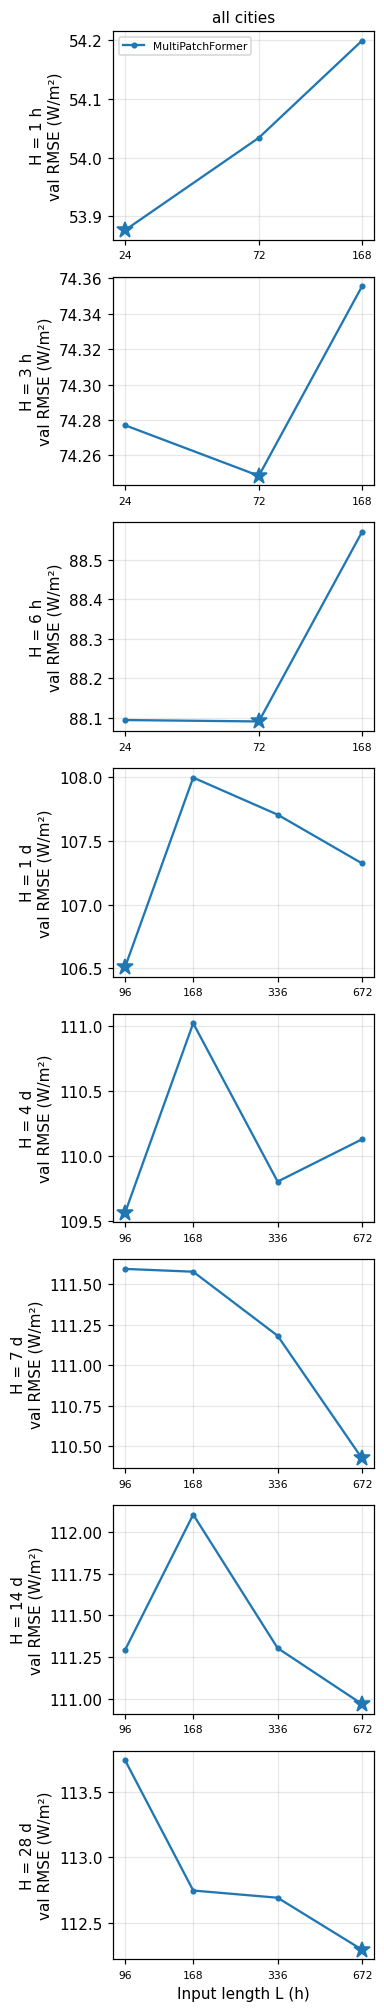

In [14]:
SEL = run_selection(MAIN)

## Part 10 — Experiment 2: final runs with all seeds

Final runs: 24 (runs of seed 0 are re-used from the selection step)
  final: 10/24 | elapsed 5.6 min | est. remaining 7.9 min
  final: 20/24 | elapsed 25.5 min | est. remaining 5.1 min
  final: 24/24 | elapsed 36.0 min | est. remaining 0.0 min
Test predictions saved in /kaggle/working/outputs/predictions (used for the final model comparison)


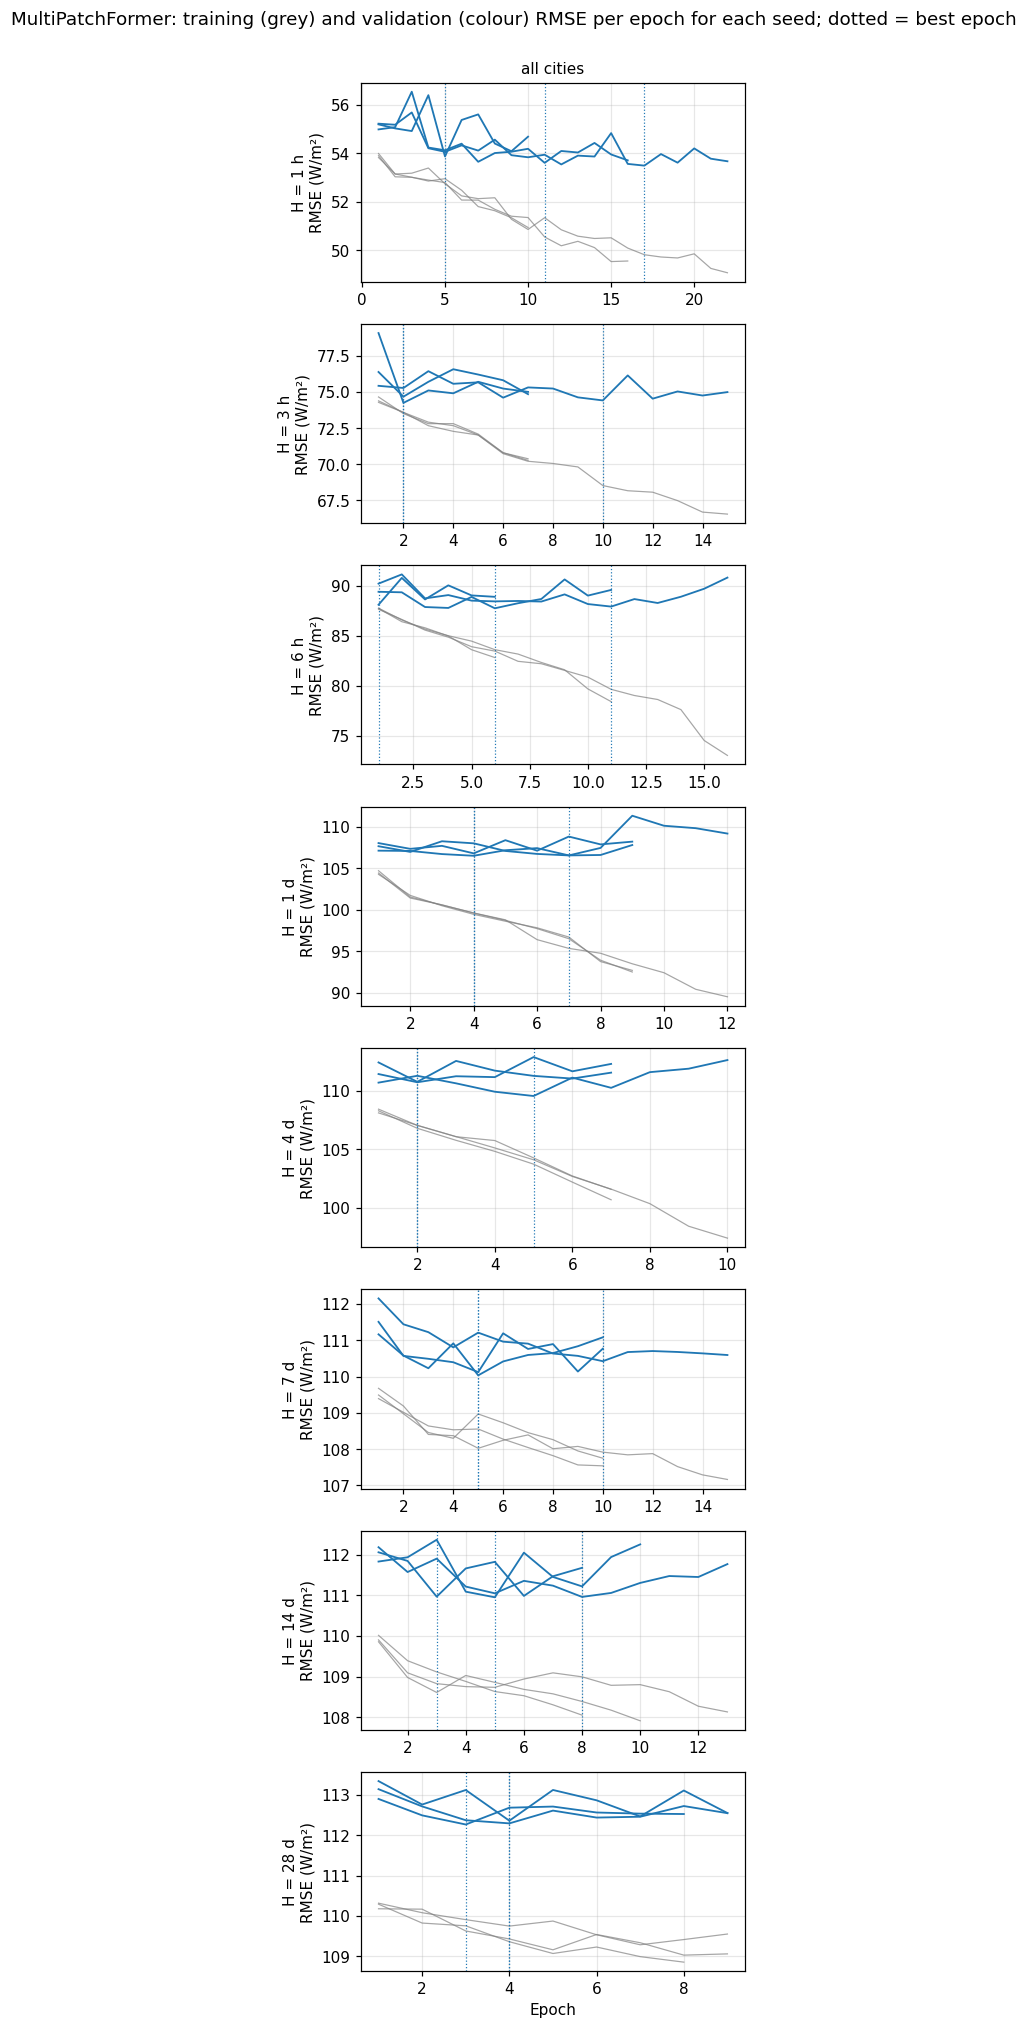

In [15]:
FR = run_final(MAIN)
fig_training_curves(FR, MAIN)

## Part 11 — Results on the hidden test year (2024): MultiPatchFormer vs reference forecasts
The full comparison with PatchTST, DLinear and LSTM is made from the saved predictions of both notebooks.

In [16]:
add_reference_predictions()
ALLM = REF_NAMES + MAIN
R, NUM = summary(ALLM)
POOL = pooled(ALLM)
city_average(NUM)
best_models(NUM)

### Results per city, horizon and model (test year, daytime hours, mean ± std over seeds)

**02_T10_results_H1 — Horizon 1 h (intraday, issued every hour). RMSE, MAE, MBE in W/m²; nRMSE, skill vs CLIPER and skill vs smart persistence (SP) in %**

,Region,model,L,seeds,RMSE,MAE,MBE,nRMSE_pct,R2,Skill_pct,Skill_SP_pct
0,Islamabad,Seasonal persistence,NaN,1,184.43 ± 0.00,101.48 ± 0.00,-0.12 ± 0.00,46.76 ± 0.00,0.566 ± 0.000,-221.30 ± 0.00,-218.62 ± 0.00
1,Islamabad,Smart persistence,NaN,1,57.88 ± 0.00,25.62 ± 0.00,-2.29 ± 0.00,14.67 ± 0.00,0.957 ± 0.000,-0.84 ± 0.00,0.00 ± 0.00
2,Islamabad,Climatology,NaN,1,139.03 ± 0.00,92.33 ± 0.00,-5.25 ± 0.00,35.25 ± 0.00,0.754 ± 0.000,-142.20 ± 0.00,-140.18 ± 0.00
3,Islamabad,CLIPER,NaN,1,57.40 ± 0.00,30.70 ± 0.00,-2.68 ± 0.00,14.55 ± 0.00,0.958 ± 0.000,0.00 ± 0.00,0.83 ± 0.00
4,Islamabad,MultiPatchFormer,24.0000,3,56.55 ± 0.38,29.16 ± 0.30,2.59 ± 2.79,14.34 ± 0.10,0.959 ± 0.001,1.48 ± 0.66,2.30 ± 0.66
5,Karachi,Seasonal persistence,NaN,1,124.64 ± 0.00,65.36 ± 0.00,-0.12 ± 0.00,27.96 ± 0.00,0.806 ± 0.000,-135.91 ± 0.00,-127.68 ± 0.00
6,Karachi,Smart persistence,NaN,1,54.74 ± 0.00,23.72 ± 0.00,-2.59 ± 0.00,12.28 ± 0.00,0.963 ± 0.000,-3.62 ± 0.00,0.00 ± 0.00
7,Karachi,Climatology,NaN,1,102.39 ± 0.00,54.87 ± 0.00,5.11 ± 0.00,22.97 ± 0.00,0.869 ± 0.000,-93.79 ± 0.00,-87.03 ± 0.00
8,Karachi,CLIPER,NaN,1,52.83 ± 0.00,25.45 ± 0.00,-1.28 ± 0.00,11.85 ± 0.00,0.965 ± 0.000,0.00 ± 0.00,3.49 ± 0.00
9,Karachi,MultiPatchFormer,24.0000,3,53.60 ± 0.18,27.42 ± 0.37,2.40 ± 0.97,12.02 ± 0.04,0.964 ± 0.000,-1.44 ± 0.35,2.10 ± 0.33


**02_T10_results_H3 — Horizon 3 h (intraday, issued every hour). RMSE, MAE, MBE in W/m²; nRMSE, skill vs CLIPER and skill vs smart persistence (SP) in %**

,Region,model,L,seeds,RMSE,MAE,MBE,nRMSE_pct,R2,Skill_pct,Skill_SP_pct
0,Islamabad,Seasonal persistence,NaN,1,184.43 ± 0.00,101.48 ± 0.00,-0.12 ± 0.00,46.76 ± 0.00,0.566 ± 0.000,-116.40 ± 0.00,-109.09 ± 0.00
1,Islamabad,Smart persistence,NaN,1,88.21 ± 0.00,40.30 ± 0.00,-4.73 ± 0.00,22.36 ± 0.00,0.901 ± 0.000,-3.50 ± 0.00,0.00 ± 0.00
2,Islamabad,Climatology,NaN,1,139.03 ± 0.00,92.33 ± 0.00,-5.25 ± 0.00,35.25 ± 0.00,0.754 ± 0.000,-63.12 ± 0.00,-57.61 ± 0.00
3,Islamabad,CLIPER,NaN,1,85.23 ± 0.00,49.26 ± 0.00,-4.63 ± 0.00,21.61 ± 0.00,0.907 ± 0.000,0.00 ± 0.00,3.38 ± 0.00
4,Islamabad,MultiPatchFormer,72.0000,3,83.47 ± 0.42,46.41 ± 1.63,-0.71 ± 3.79,21.16 ± 0.11,0.911 ± 0.001,2.07 ± 0.49,5.38 ± 0.47
5,Karachi,Seasonal persistence,NaN,1,124.64 ± 0.00,65.36 ± 0.00,-0.12 ± 0.00,27.96 ± 0.00,0.806 ± 0.000,-78.50 ± 0.00,-67.70 ± 0.00
6,Karachi,Smart persistence,NaN,1,74.33 ± 0.00,34.02 ± 0.00,-5.15 ± 0.00,16.68 ± 0.00,0.931 ± 0.000,-6.44 ± 0.00,0.00 ± 0.00
7,Karachi,Climatology,NaN,1,102.39 ± 0.00,54.87 ± 0.00,5.11 ± 0.00,22.97 ± 0.00,0.869 ± 0.000,-46.63 ± 0.00,-37.76 ± 0.00
8,Karachi,CLIPER,NaN,1,69.83 ± 0.00,36.08 ± 0.00,-1.05 ± 0.00,15.67 ± 0.00,0.939 ± 0.000,0.00 ± 0.00,6.05 ± 0.00
9,Karachi,MultiPatchFormer,72.0000,3,70.68 ± 0.32,37.88 ± 0.48,6.77 ± 1.73,15.86 ± 0.07,0.938 ± 0.001,-1.22 ± 0.45,4.90 ± 0.42


**02_T10_results_H6 — Horizon 6 h (intraday, issued every hour). RMSE, MAE, MBE in W/m²; nRMSE, skill vs CLIPER and skill vs smart persistence (SP) in %**

... (14 outputs left out)

,H,model,RMSE,MAE,MBE,nRMSE_pct,R2,Skill_pct,Skill_SP_pct
0,1,Seasonal persistence,148.2040,81.9000,-0.1660,36.2230,0.7050,-171.2670,-165.1490
1,1,Smart persistence,55.7360,24.5820,-2.0090,13.5590,0.9590,-2.4320,0.0000
2,1,Climatology,113.5680,70.3170,-1.3080,27.6990,0.8290,-108.3310,-103.5840
3,1,CLIPER,54.4290,28.1230,-1.8350,13.2460,0.9610,0.0000,2.3650
4,1,MultiPatchFormer,53.9490,28.0790,2.1730,13.1200,0.9620,0.8350,3.1880
5,3,Seasonal persistence,148.2040,81.9000,-0.1660,36.2230,0.7050,-93.6840,-81.7800
6,3,Smart persistence,81.1580,37.4240,-4.1050,19.7840,0.9130,-6.6970,0.0000
7,3,Climatology,113.5680,70.3170,-1.3080,27.6990,0.8290,-48.9300,-39.7900
8,3,CLIPER,76.1240,42.5240,-2.8110,18.5580,0.9230,0.0000,6.2420
9,3,MultiPatchFormer,75.6030,41.9080,1.4750,18.4210,0.9250,0.5900,6.8020


**02_T13_best_model — Best model (lowest mean RMSE) per city and horizon, and the rank of MultiPatchFormer**

,Region,H,best_model,best_RMSE,best_Skill_pct,second_model,second_RMSE,main_model_rank,models_compared
0,Islamabad,1,MultiPatchFormer,56.5520,1.4810,CLIPER,57.4020,1,5
1,Islamabad,3,MultiPatchFormer,83.4650,2.0680,CLIPER,85.2280,1,5
2,Islamabad,6,MultiPatchFormer,103.3350,2.8430,CLIPER,106.3590,1,5
3,Islamabad,24,MultiPatchFormer,133.1990,1.5410,CLIPER,135.2840,1,5
4,Islamabad,96,MultiPatchFormer,137.3080,0.7750,CLIPER,138.3800,1,5
5,Islamabad,168,MultiPatchFormer,138.6640,0.3100,CLIPER,139.0960,1,5
6,Islamabad,336,MultiPatchFormer,139.8240,0.2830,CLIPER,140.2210,1,5
7,Islamabad,672,MultiPatchFormer,141.8740,0.1500,CLIPER,142.0870,1,5
8,Karachi,1,CLIPER,52.8340,0.0000,MultiPatchFormer,53.5970,2,5
9,Karachi,3,CLIPER,69.8280,0.0000,MultiPatchFormer,70.6800,2,5


,Region,H,best_model,best_RMSE,best_Skill_pct,second_model,second_RMSE,main_model_rank,models_compared
0,Islamabad,1,MultiPatchFormer,56.5520,1.4810,CLIPER,57.4020,1,5
1,Islamabad,3,MultiPatchFormer,83.4650,2.0680,CLIPER,85.2280,1,5
2,Islamabad,6,MultiPatchFormer,103.3350,2.8430,CLIPER,106.3590,1,5
3,Islamabad,24,MultiPatchFormer,133.1990,1.5410,CLIPER,135.2840,1,5
4,Islamabad,96,MultiPatchFormer,137.3080,0.7750,CLIPER,138.3800,1,5
5,Islamabad,168,MultiPatchFormer,138.6640,0.3100,CLIPER,139.0960,1,5
6,Islamabad,336,MultiPatchFormer,139.8240,0.2830,CLIPER,140.2210,1,5
7,Islamabad,672,MultiPatchFormer,141.8740,0.1500,CLIPER,142.0870,1,5
8,Karachi,1,CLIPER,52.8340,0.0000,MultiPatchFormer,53.5970,2,5
9,Karachi,3,CLIPER,69.8280,0.0000,MultiPatchFormer,70.6800,2,5


*02_F10_skill_vs_horizon — Skill score against CLIPER by horizon (error bars = std over seeds)*

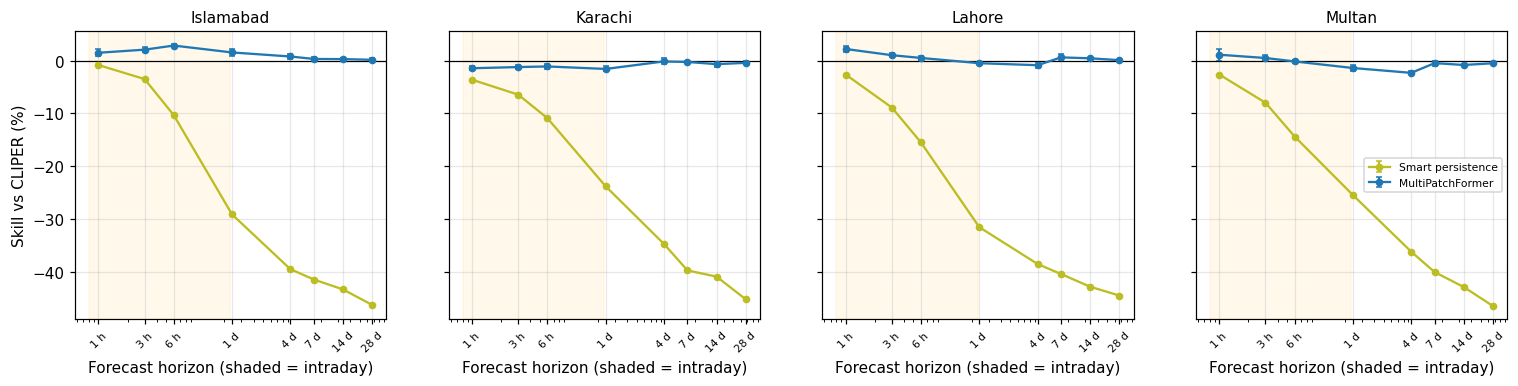

*02_F11_rmse_vs_horizon — Test RMSE by horizon (daytime hours)*

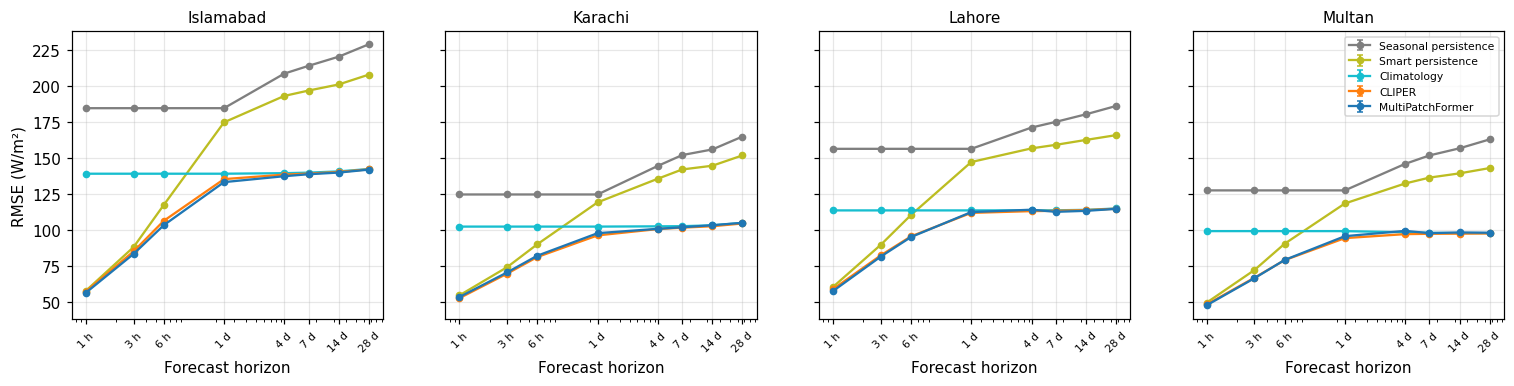

*02_F12_heatmap_Skill_pct — Skill_pct by city (rows) and horizon (columns) for each model*

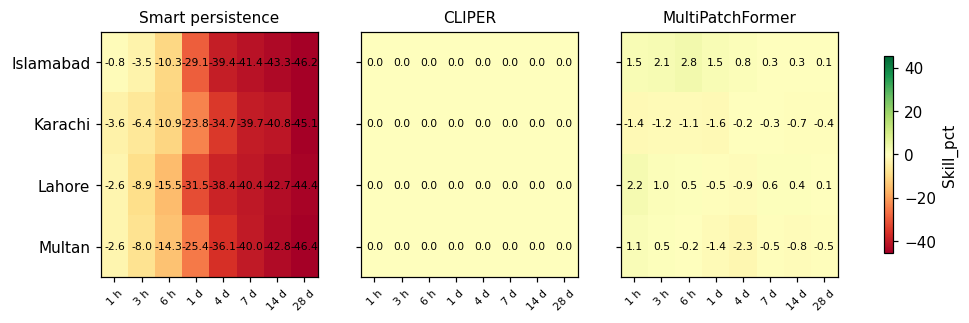

*02_F12b_heatmap_RMSE — RMSE by city (rows) and horizon (columns) for each model*

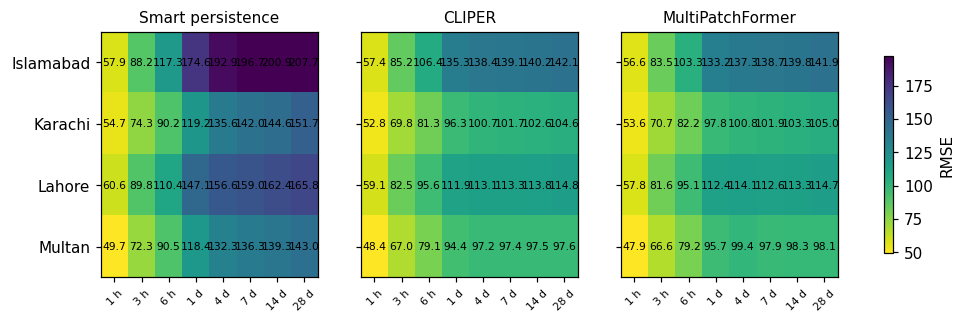

*02_F12c_heatmap_nRMSE_pct — nRMSE_pct by city (rows) and horizon (columns) for each model*

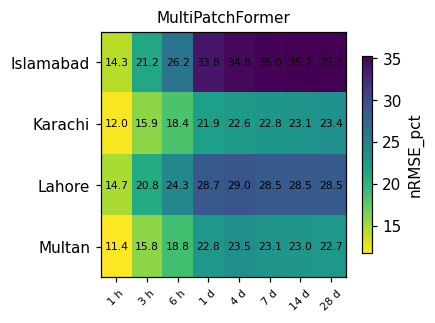

*02_F13_rmse_bars — Test RMSE per city, horizon and model (error bars = std over seeds)*

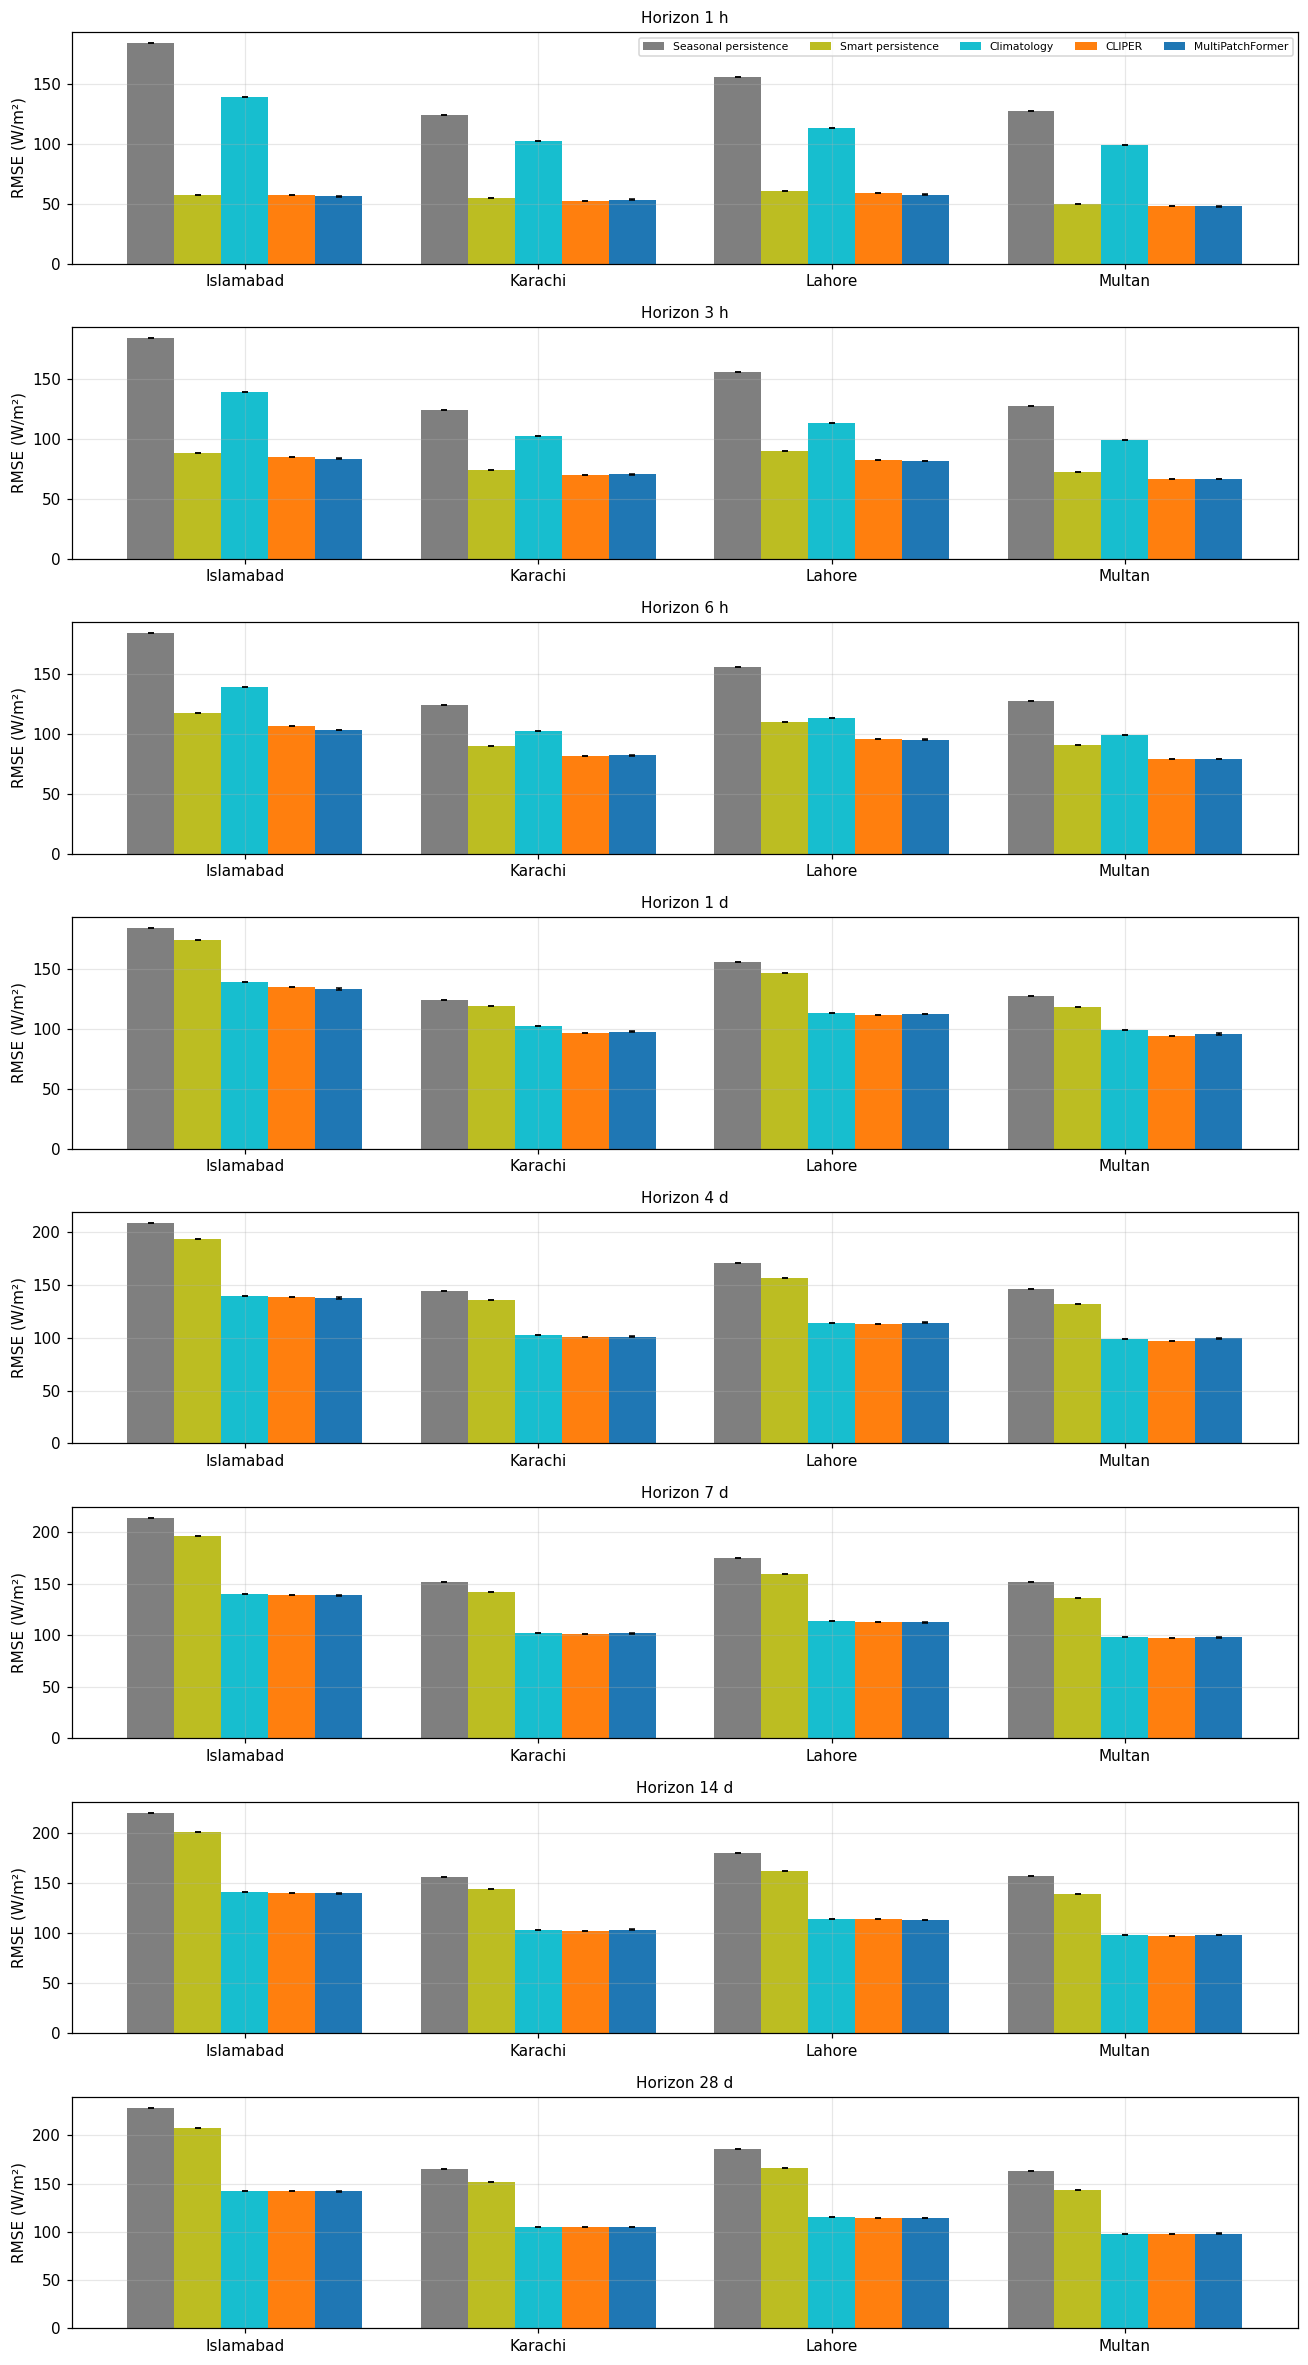

In [17]:
fig_skill_vs_horizon(R, ALLM)
fig_rmse_vs_horizon(R, ALLM)
fig_heatmaps(NUM, ["Smart persistence", "CLIPER"] + MAIN, "Skill_pct")
fig_heatmaps(NUM, ["Smart persistence", "CLIPER"] + MAIN, "RMSE", name="F12b", cmap="viridis")
fig_heatmaps(NUM, MAIN, "nRMSE_pct", name="F12c", cmap="viridis")
fig_rmse_bars(R, ALLM)

**02_T15_rmse_by_lead_day — RMSE (W/m²) by lead day, models trained for H = 672 h (seed-mean forecast)**

model,Region,lead_day,CLIPER,Climatology,MultiPatchFormer,Seasonal persistence,Smart persistence
0,Islamabad,1,138.8300,142.7200,138.3200,188.9000,179.1100
1,Islamabad,2,142.3600,142.6700,141.5900,214.2900,198.4400
2,Islamabad,3,142.6400,142.6400,141.6700,221.9300,204.0500
3,Islamabad,4,142.4900,142.6000,141.6000,224.8200,206.7800
4,Islamabad,5,142.4900,142.5500,141.4300,225.6600,206.7500
5,Islamabad,6,142.2600,142.5100,141.0900,223.6800,204.4200
6,Islamabad,7,142.0700,142.4600,140.9900,223.3400,202.9500
7,Islamabad,8,142.6600,142.4300,141.8500,232.2900,210.9800
8,Islamabad,9,142.2300,142.4100,141.2800,229.0800,207.4400
9,Islamabad,10,142.3100,142.3600,141.7500,231.6800,208.9400


*02_F14_error_by_lead_day — Error growth with lead time (top) and skill vs CLIPER (bottom)*

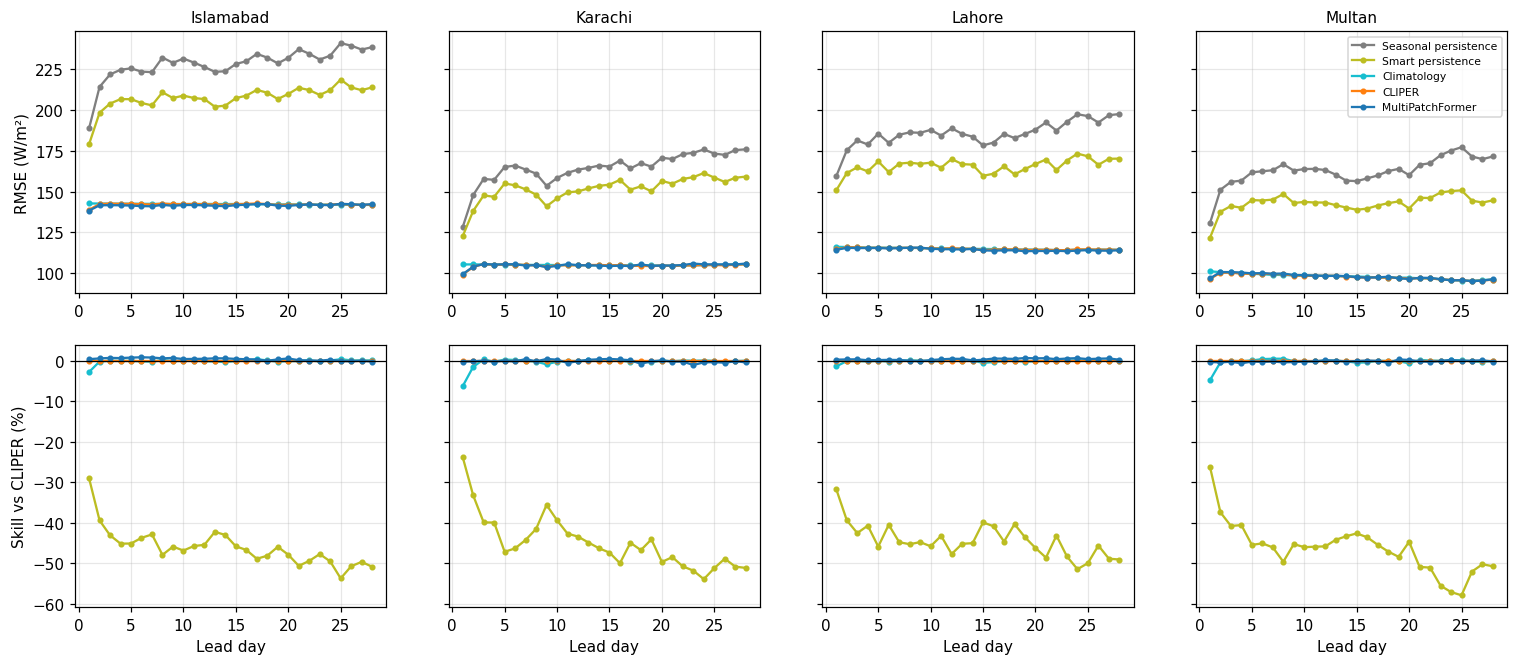

In [18]:
LEAD = lead_day_analysis(ALLM)

**02_T16_rmse_by_season_H24 — RMSE (W/m²) by season, horizon 1 d**

model,Region,label,forecasts,CLIPER,MultiPatchFormer,Smart persistence
0,Islamabad,Monsoon (JJAS),122,154.0600,149.2500,203.9400
1,Islamabad,Post-monsoon (ON),61,53.6100,52.6500,68.9400
2,Islamabad,Pre-monsoon (MAM),92,162.6800,160.9600,204.4900
3,Islamabad,Winter (DJF),91,96.7100,93.9500,122.2000
4,Karachi,Monsoon (JJAS),122,116.2000,114.7800,143.0200
5,Karachi,Post-monsoon (ON),61,52.7300,57.3500,69.2700
6,Karachi,Pre-monsoon (MAM),92,96.8800,98.2800,119.8500
7,Karachi,Winter (DJF),65,74.1000,74.9200,91.8700
8,Lahore,Monsoon (JJAS),122,136.7700,134.6500,183.1300
9,Lahore,Post-monsoon (ON),61,38.3000,37.0200,45.9100


**02_T16_skill_by_season_H24 — Skill vs CLIPER (%) by season, horizon 1 d**

model,Region,label,CLIPER,MultiPatchFormer,Smart persistence
0,Islamabad,Monsoon (JJAS),0.0000,3.1000,-32.4000
1,Islamabad,Post-monsoon (ON),0.0000,1.8000,-28.6000
2,Islamabad,Pre-monsoon (MAM),0.0000,1.1000,-25.7000
3,Islamabad,Winter (DJF),0.0000,2.9000,-26.4000
4,Karachi,Monsoon (JJAS),0.0000,1.2000,-23.1000
5,Karachi,Post-monsoon (ON),0.0000,-8.8000,-31.4000
6,Karachi,Pre-monsoon (MAM),0.0000,-1.4000,-23.7000
7,Karachi,Winter (DJF),0.0000,-1.1000,-24.0000
8,Lahore,Monsoon (JJAS),0.0000,1.6000,-33.9000
9,Lahore,Post-monsoon (ON),0.0000,3.3000,-19.9000


*02_F15_skill_by_season_H24 — Skill by season, horizon 1 d*

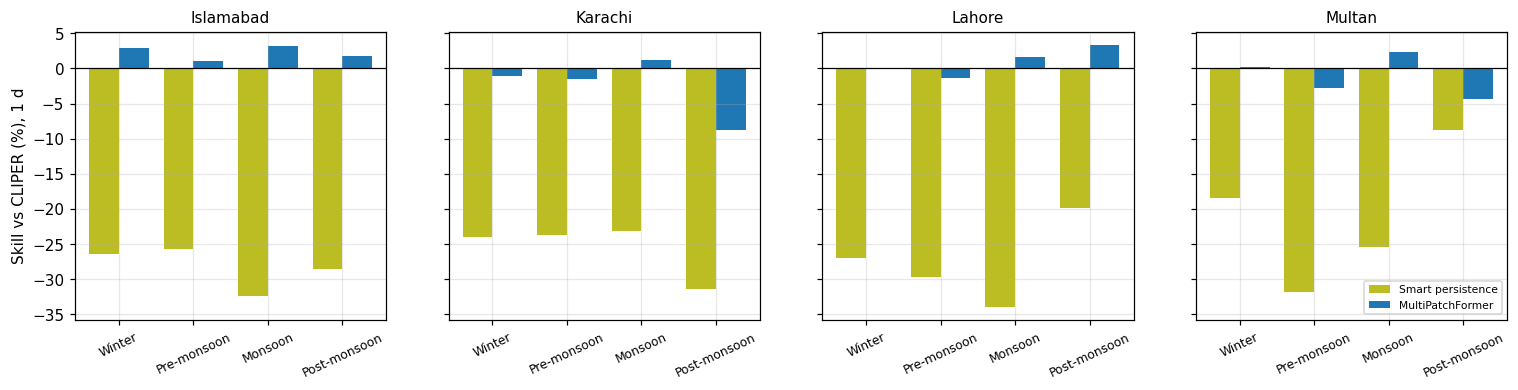

**02_T16_rmse_by_sky_H24 — RMSE (W/m²) by sky, horizon 1 d**

model,Region,label,forecasts,CLIPER,MultiPatchFormer,Smart persistence
0,Islamabad,Clear (k≥0.8),264,85.2700,76.0000,135.7100
1,Islamabad,Cloudy (k<0.5),43,278.9000,278.0300,286.5900
2,Islamabad,Partly cloudy (0.5–0.8),59,155.4800,161.4900,215.5700
3,Karachi,Clear (k≥0.8),270,57.6900,58.2900,86.9900
4,Karachi,Cloudy (k<0.5),29,241.9900,238.7600,234.0300
5,Karachi,Partly cloudy (0.5–0.8),41,139.5100,142.4400,182.6500
6,Lahore,Clear (k≥0.8),254,72.6200,68.7800,112.2300
7,Lahore,Cloudy (k<0.5),30,243.0800,246.8100,254.5600
8,Lahore,Partly cloudy (0.5–0.8),82,137.5200,139.2800,186.6600
9,Multan,Clear (k≥0.8),284,53.5600,53.6500,92.0800


**02_T16_skill_by_sky_H24 — Skill vs CLIPER (%) by sky, horizon 1 d**

model,Region,label,CLIPER,MultiPatchFormer,Smart persistence
0,Islamabad,Clear (k≥0.8),0.0000,10.9000,-59.1000
1,Islamabad,Cloudy (k<0.5),0.0000,0.3000,-2.8000
2,Islamabad,Partly cloudy (0.5–0.8),0.0000,-3.9000,-38.6000
3,Karachi,Clear (k≥0.8),0.0000,-1.0000,-50.8000
4,Karachi,Cloudy (k<0.5),0.0000,1.3000,3.3000
5,Karachi,Partly cloudy (0.5–0.8),0.0000,-2.1000,-30.9000
6,Lahore,Clear (k≥0.8),0.0000,5.3000,-54.5000
7,Lahore,Cloudy (k<0.5),0.0000,-1.5000,-4.7000
8,Lahore,Partly cloudy (0.5–0.8),0.0000,-1.3000,-35.7000
9,Multan,Clear (k≥0.8),0.0000,-0.2000,-71.9000


*02_F15_skill_by_sky_H24 — Skill by sky, horizon 1 d*

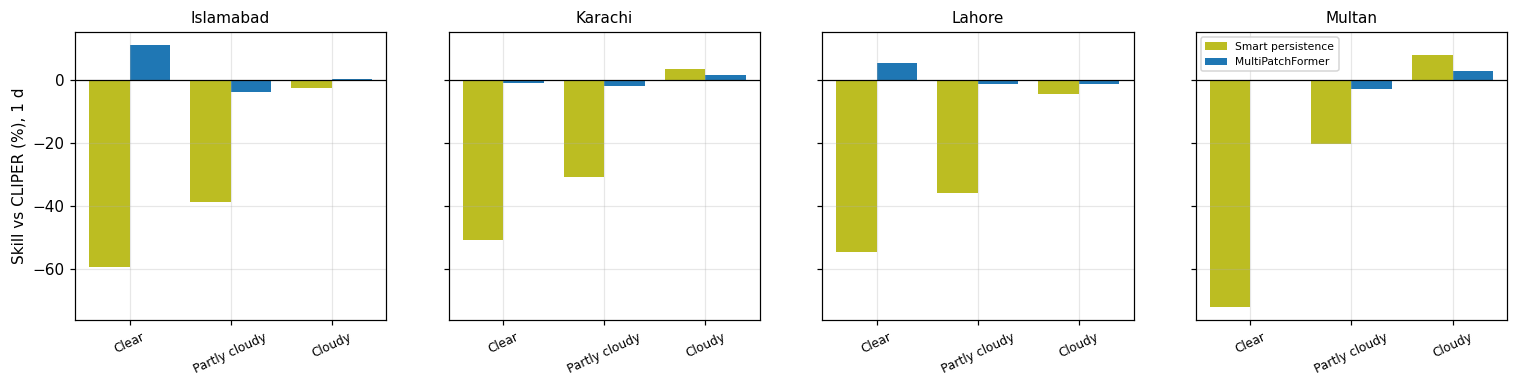

*02_F16_error_by_hour_and_month_H24 — RMSE and bias by hour of day, and RMSE by month — horizon 1 d*

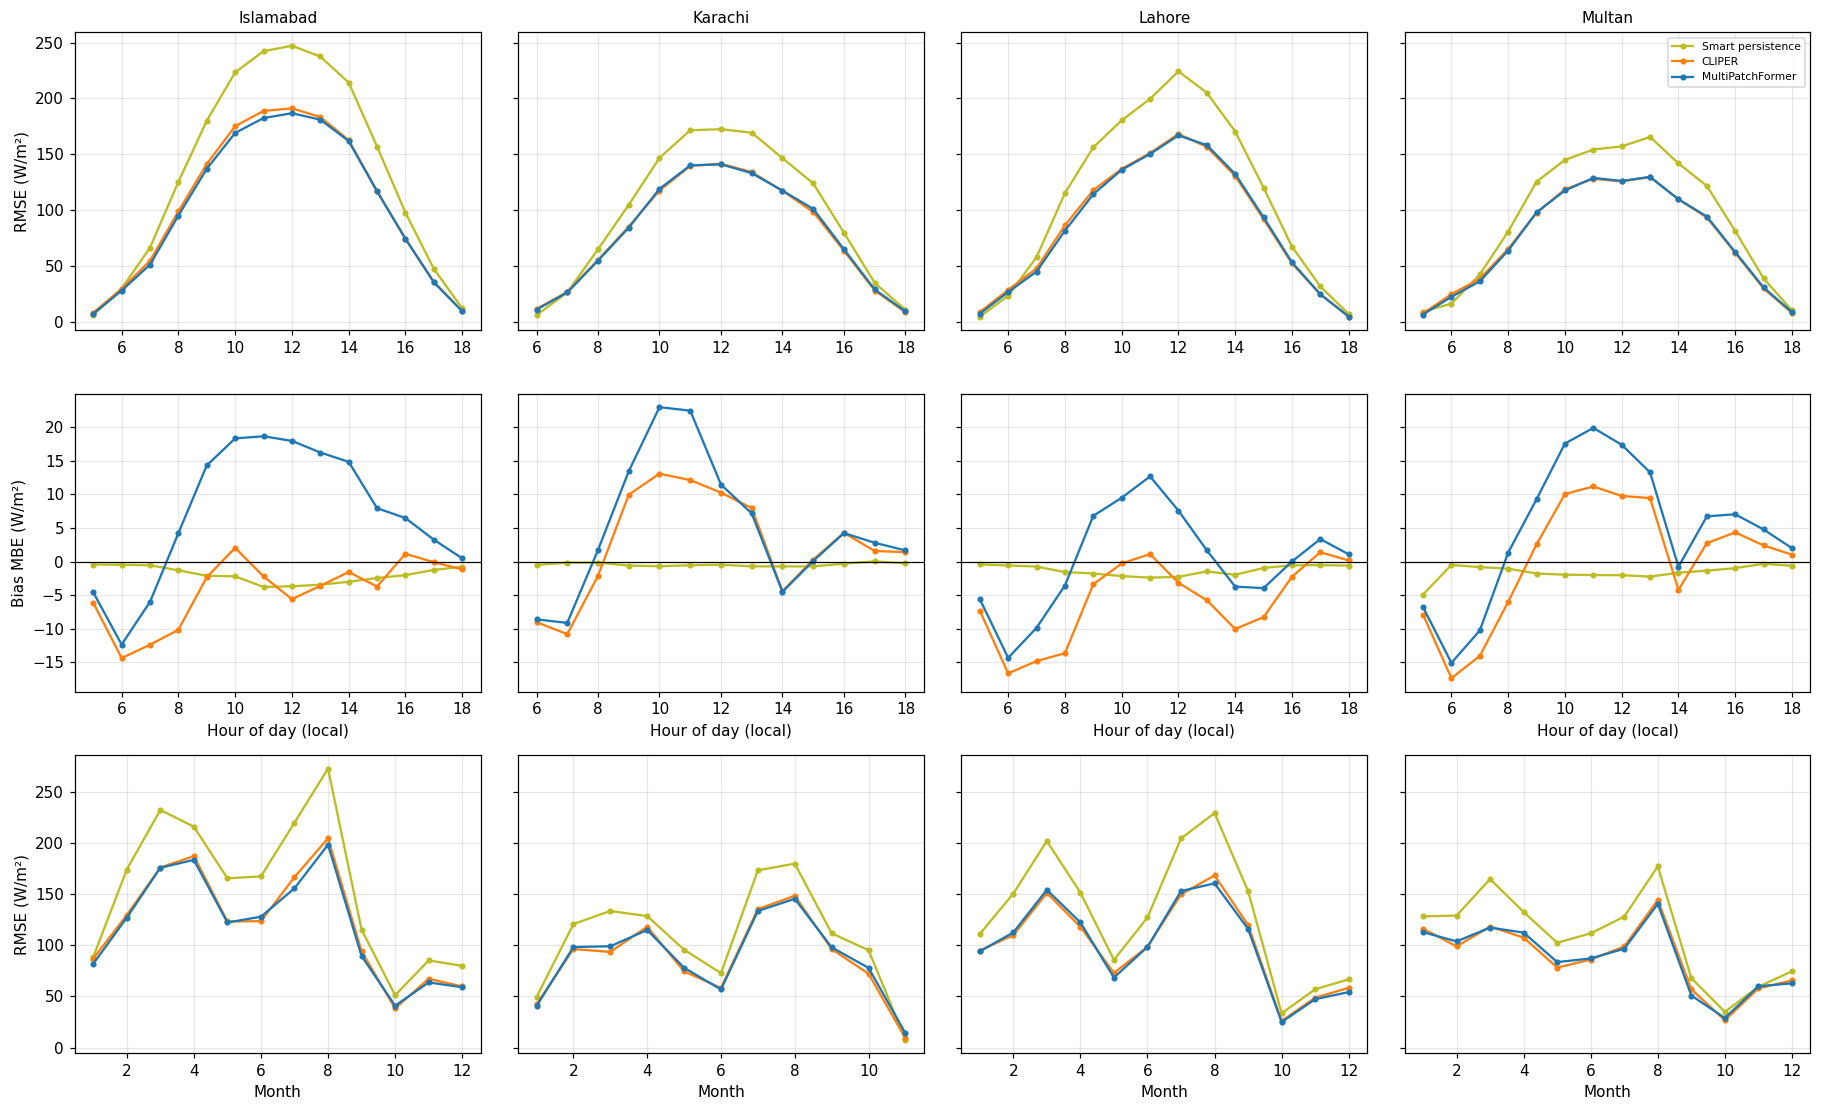

In [19]:
BRK = breakdown_analysis(["Smart persistence", "CLIPER"] + MAIN)
hour_month_analysis(["Smart persistence", "CLIPER"] + MAIN)

*02_F17_scatter_H24 — Forecast vs observed GHI, horizon 1 d (daytime hours, colour = log count)*

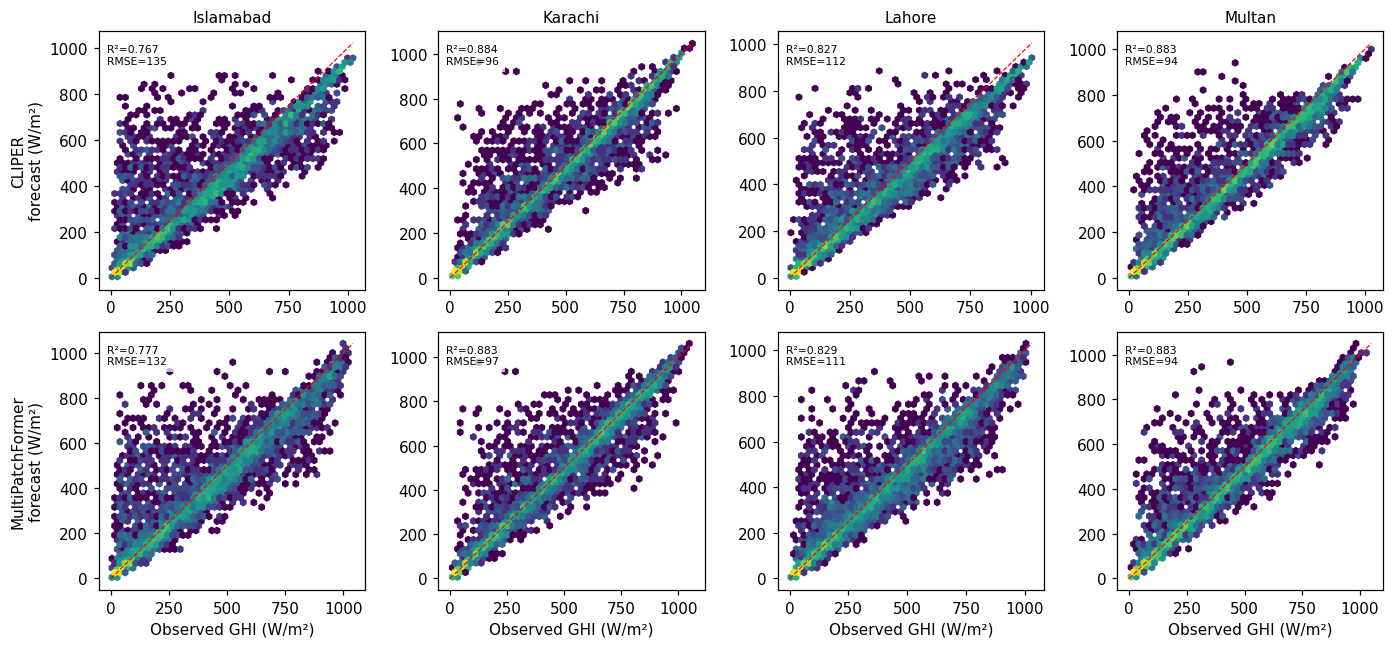

*02_F18_error_distribution_H24 — Distribution of errors, horizon 1 d (daytime hours)*

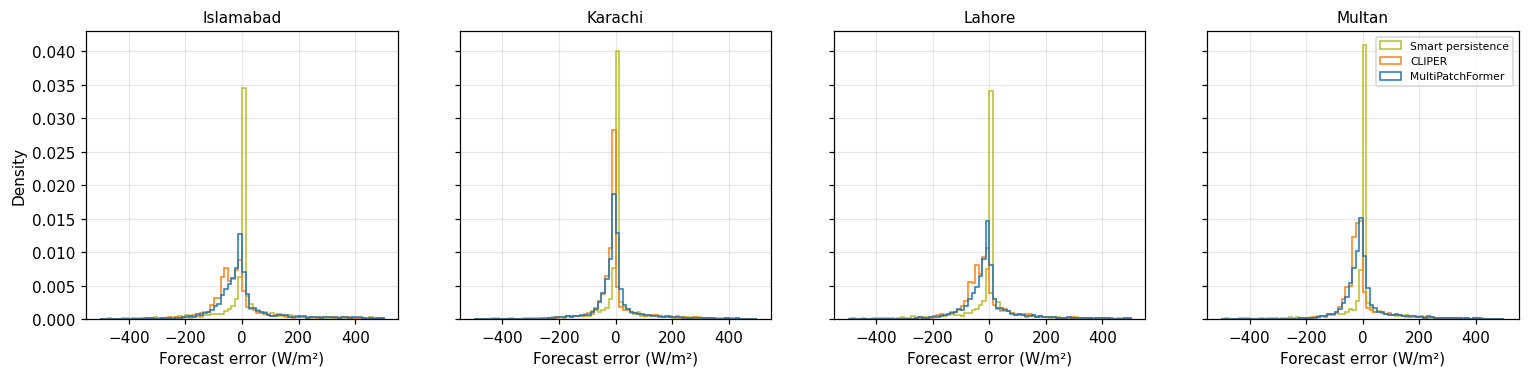

*02_F19_example_forecasts_H24 — Example forecasts, horizon 1 d: clearest and cloudiest test periods*

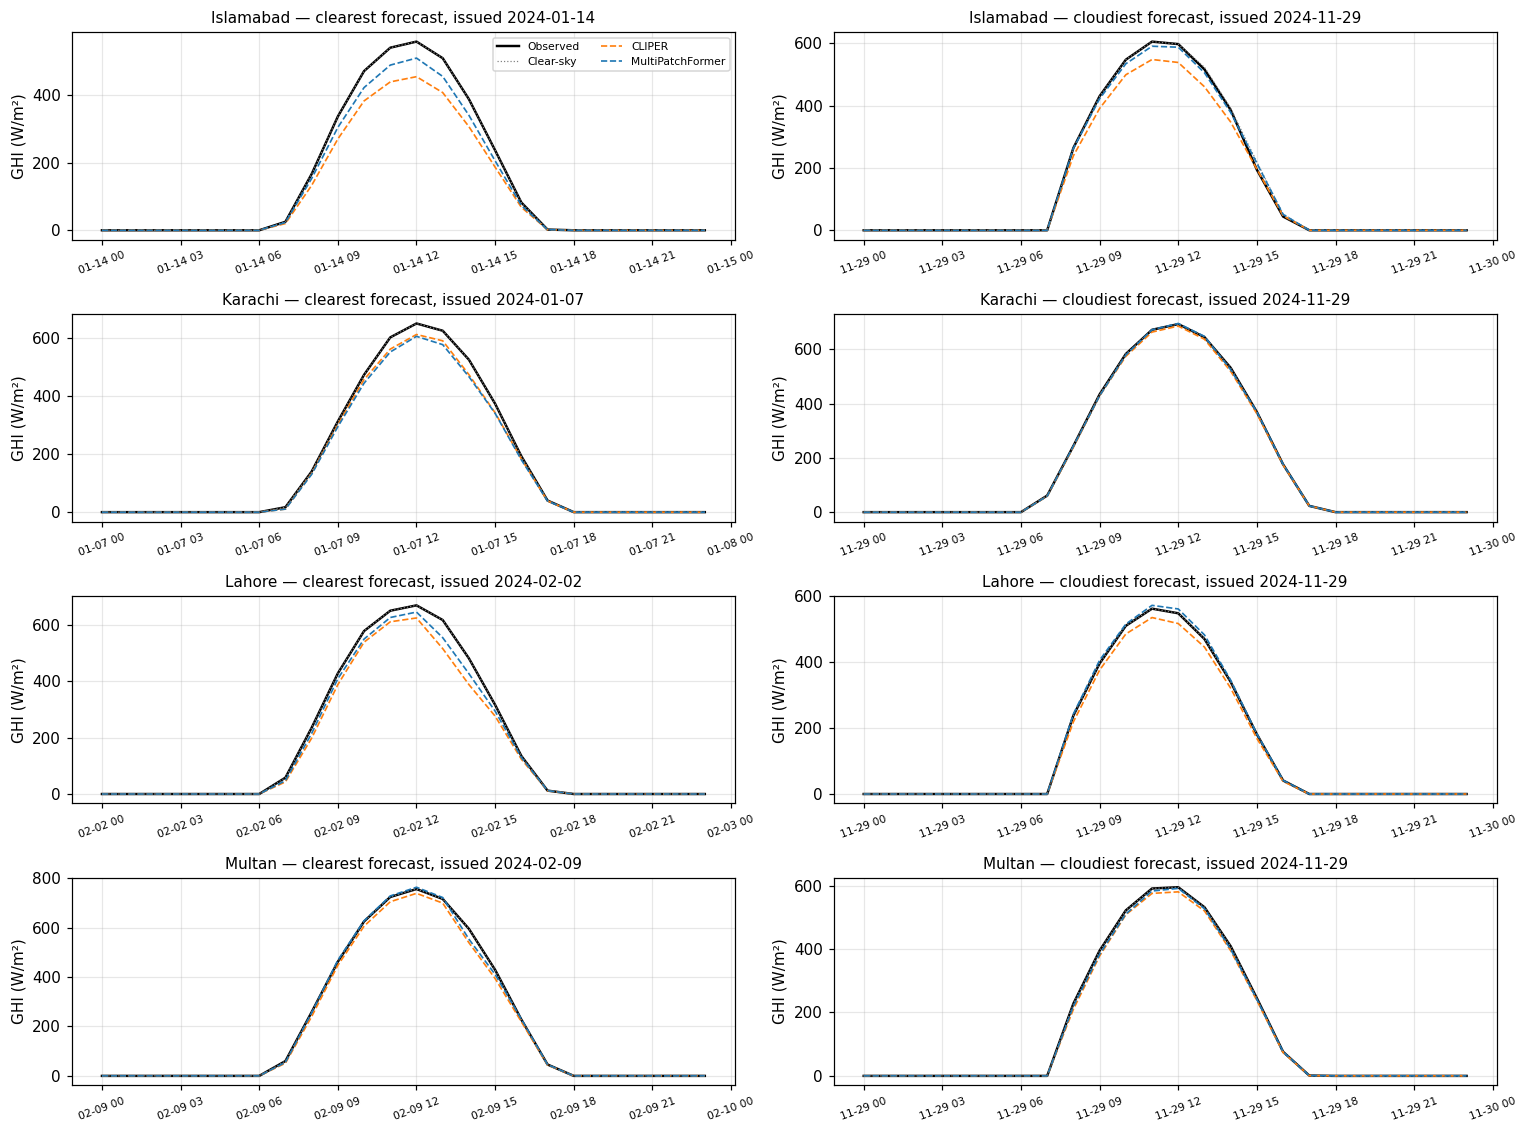

*02_F19_example_forecasts_H168 — Example forecasts, horizon 7 d: clearest and cloudiest test periods*

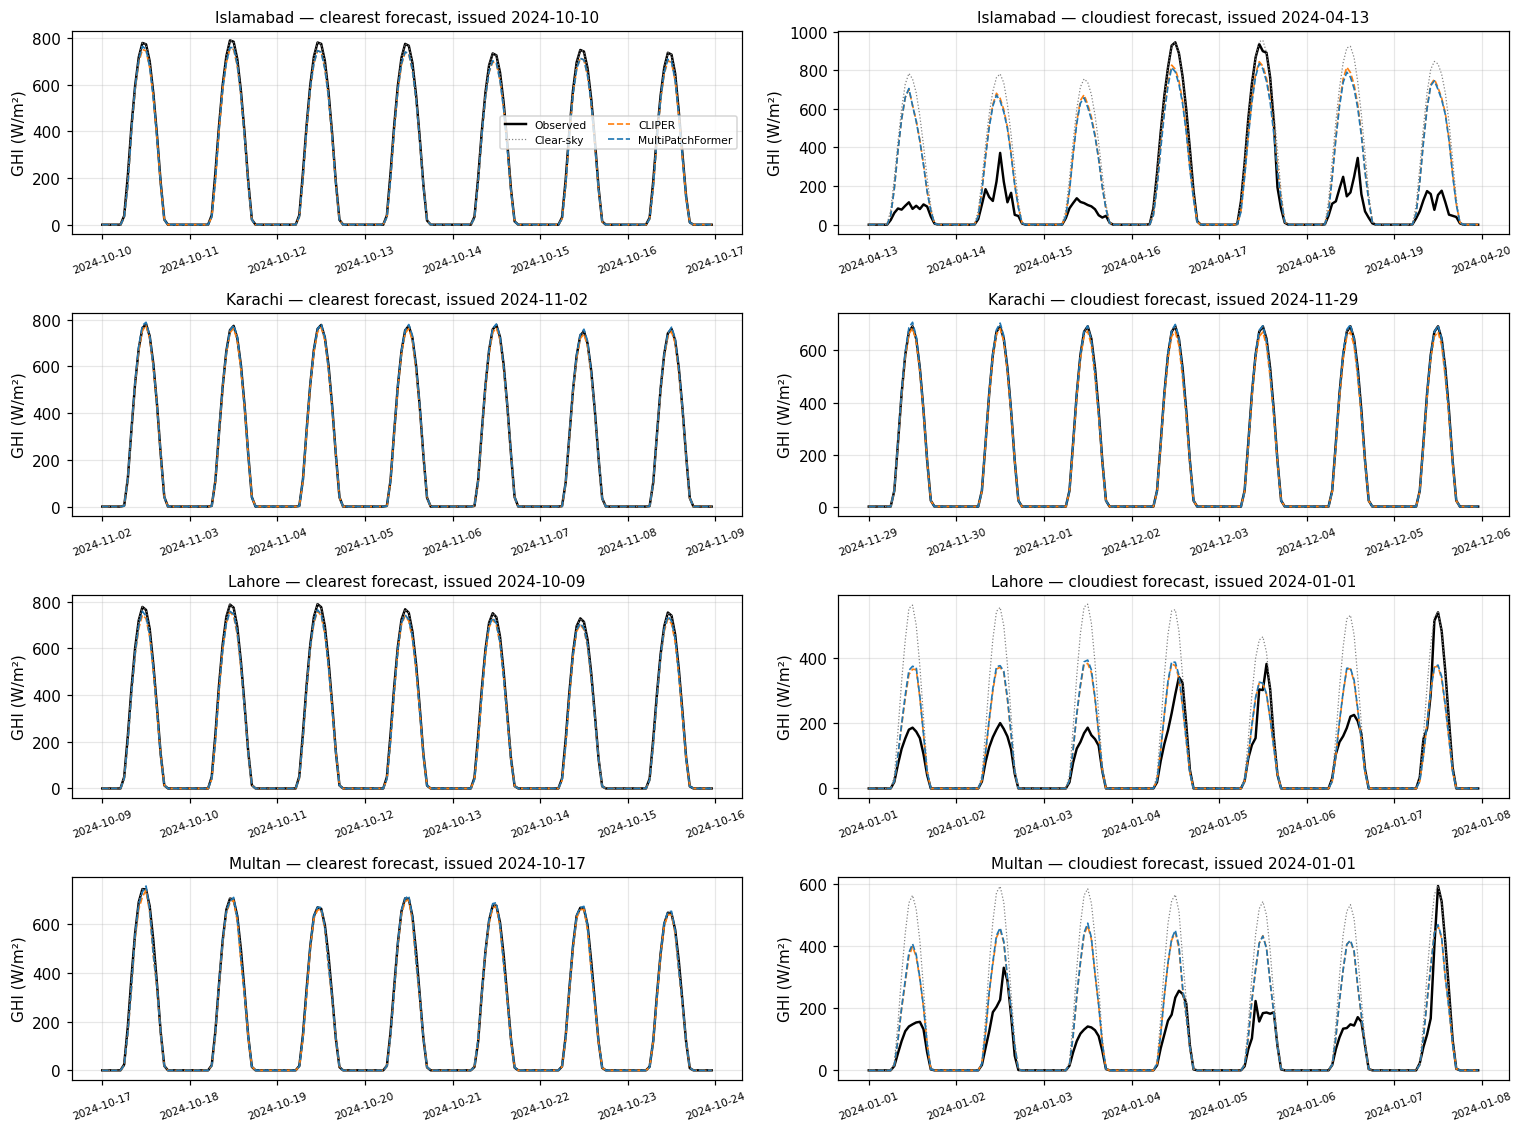

*02_F20_daily_irradiation_2024 — Daily irradiation in the test year: observed vs day-ahead forecasts*

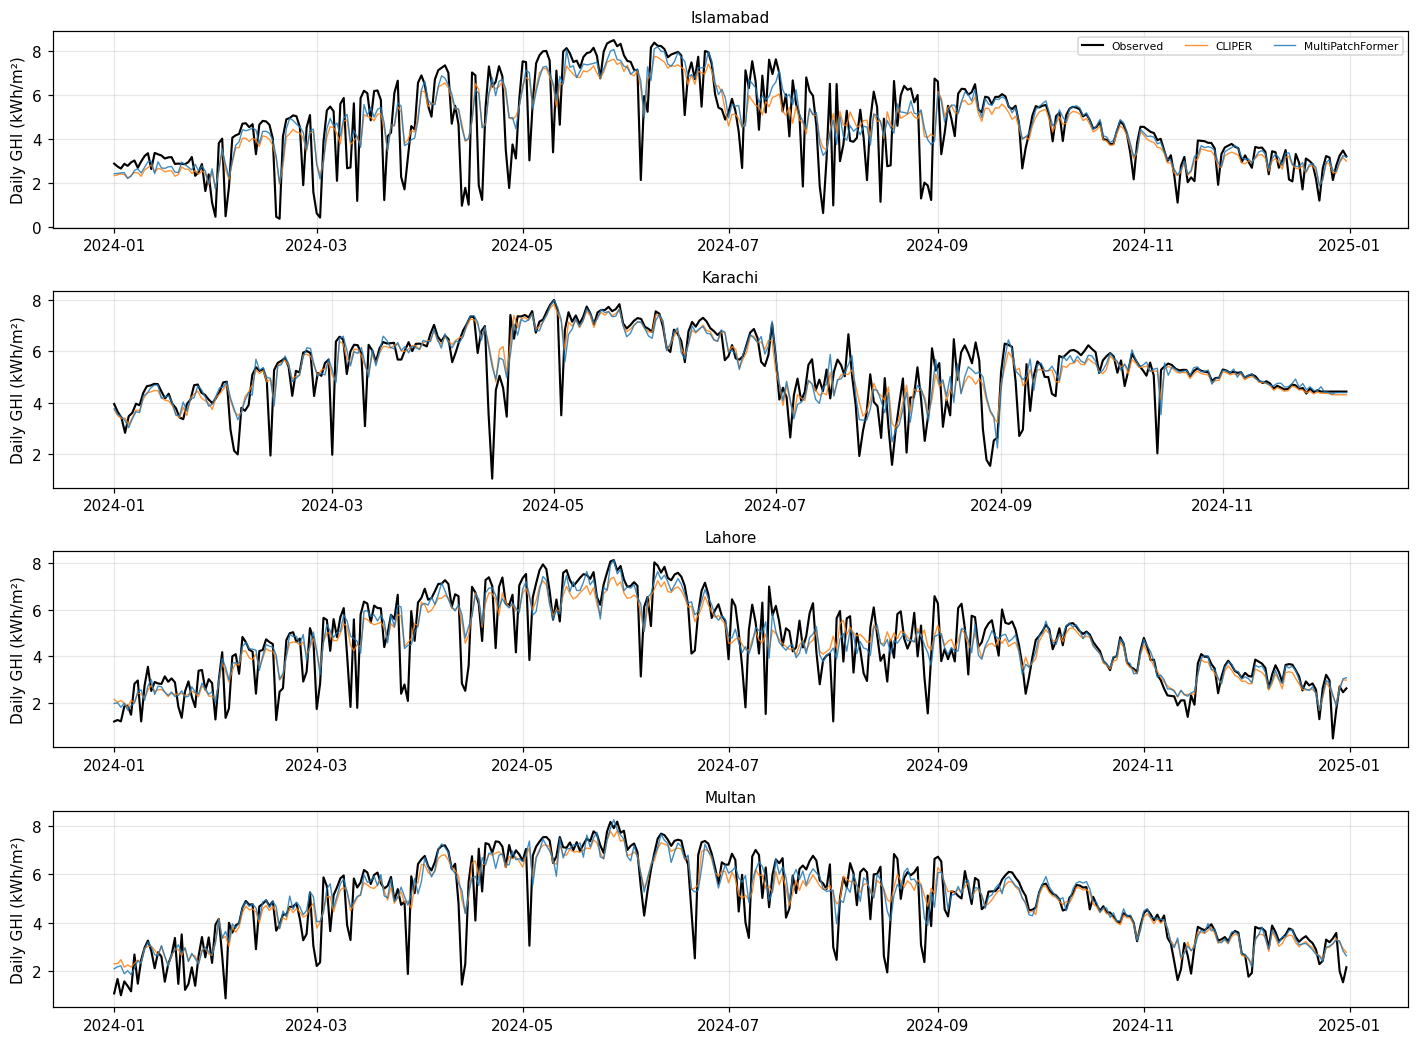

In [20]:
fig_scatter(["CLIPER"] + MAIN)
fig_error_hist(["Smart persistence", "CLIPER"] + MAIN)
fig_examples(["CLIPER"] + MAIN, H=CFG["BREAKDOWN_HORIZON"])
fig_examples(["CLIPER"] + MAIN)
fig_daily_series(["CLIPER"] + MAIN)

### Intraday task (1–6 h ahead, issued every hour): error by lead hour, season, sky, hour of day; rolling forecasts

**02_T15b_rmse_by_lead_hour — Intraday RMSE (W/m²) by lead hour, models trained for H = 6 h (seed-mean forecast)**

model,Region,lead_h,CLIPER,Climatology,MultiPatchFormer,Seasonal persistence,Smart persistence
0,Islamabad,1,57.4000,139.0300,57.2300,184.4300,57.8800
1,Islamabad,2,86.7000,139.0300,84.4700,184.4300,88.8900
2,Islamabad,3,104.7900,139.0300,100.4000,184.4300,109.9600
3,Islamabad,4,116.9200,139.0300,110.9700,184.4300,126.8300
4,Islamabad,5,124.8100,139.0300,118.8800,184.4300,141.0400
5,Islamabad,6,129.7400,139.0300,125.0400,184.4300,152.6100
6,Karachi,1,52.8300,102.3900,53.7700,124.6400,54.7400
7,Karachi,2,71.9700,102.3900,73.0500,124.6400,76.3200
8,Karachi,3,81.5900,102.3900,81.4900,124.6400,88.0400
9,Karachi,4,88.1600,102.3900,87.3900,124.6400,97.7300


*02_F14b_error_by_lead_hour — Intraday error growth with lead time (top) and skill vs smart persistence (bottom)*

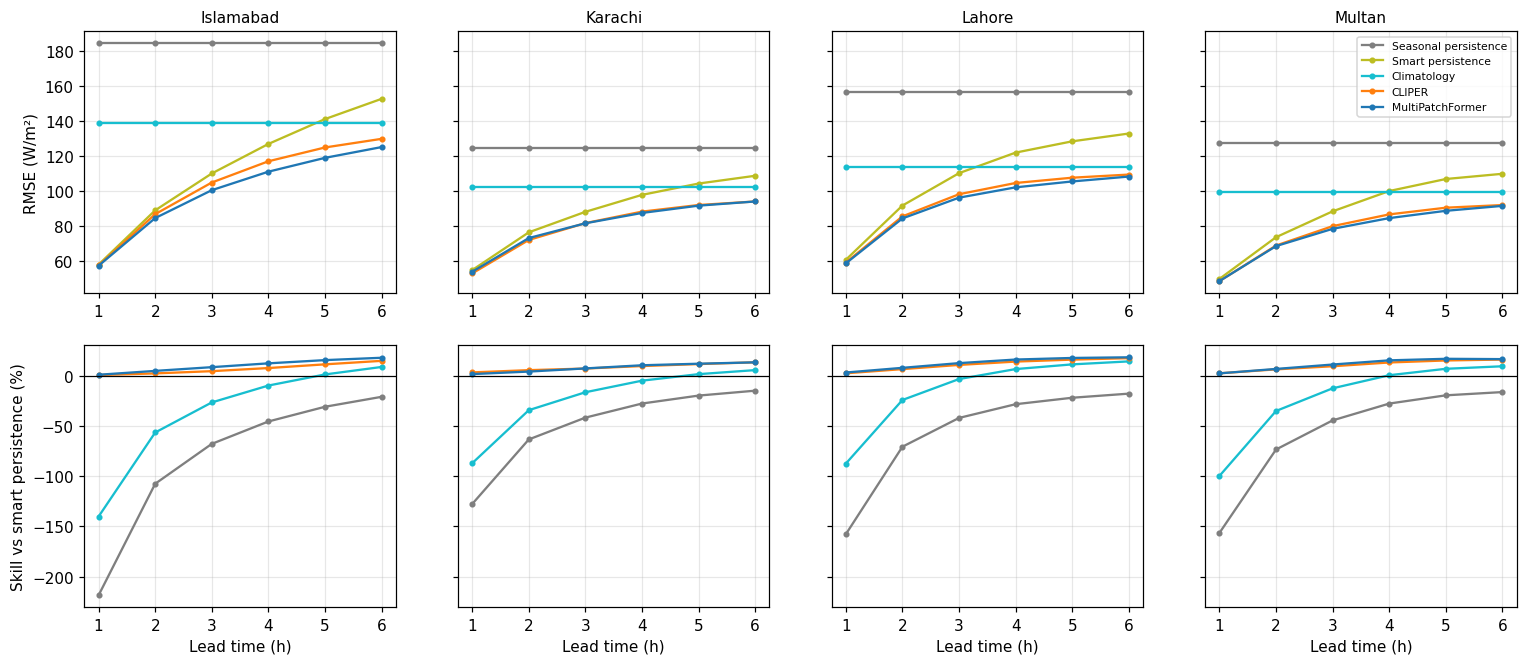

**02_T16_rmse_by_season_H1 — RMSE (W/m²) by season, horizon 1 h**

model,Region,label,forecasts,CLIPER,MultiPatchFormer,Smart persistence
0,Islamabad,Monsoon (JJAS),1596,69.2000,67.3200,70.8300
1,Islamabad,Post-monsoon (ON),633,27.6700,27.3900,29.2500
2,Islamabad,Pre-monsoon (MAM),1158,64.8100,63.8000,63.5900
3,Islamabad,Winter (DJF),934,36.5200,35.5900,36.5200
4,Karachi,Monsoon (JJAS),1545,68.6100,68.5100,71.1200
5,Karachi,Post-monsoon (ON),649,20.8400,22.0300,20.9300
6,Karachi,Pre-monsoon (MAM),1145,48.1600,48.6900,49.8500
7,Karachi,Winter (DJF),646,37.6200,38.8600,39.3400
8,Lahore,Monsoon (JJAS),1589,75.8600,72.9500,78.0100
9,Lahore,Post-monsoon (ON),633,23.2100,23.0600,25.3800


**02_T16_skill_by_season_H1 — Skill vs CLIPER (%) by season, horizon 1 h**

model,Region,label,CLIPER,MultiPatchFormer,Smart persistence
0,Islamabad,Monsoon (JJAS),0.0000,2.7000,-2.4000
1,Islamabad,Post-monsoon (ON),0.0000,1.0000,-5.7000
2,Islamabad,Pre-monsoon (MAM),0.0000,1.6000,1.9000
3,Islamabad,Winter (DJF),0.0000,2.5000,-0.0000
4,Karachi,Monsoon (JJAS),0.0000,0.1000,-3.7000
5,Karachi,Post-monsoon (ON),0.0000,-5.7000,-0.4000
6,Karachi,Pre-monsoon (MAM),0.0000,-1.1000,-3.5000
7,Karachi,Winter (DJF),0.0000,-3.3000,-4.6000
8,Lahore,Monsoon (JJAS),0.0000,3.8000,-2.8000
9,Lahore,Post-monsoon (ON),0.0000,0.6000,-9.3000


*02_F15b_skill_by_season_H1 — Skill by season, horizon 1 h*

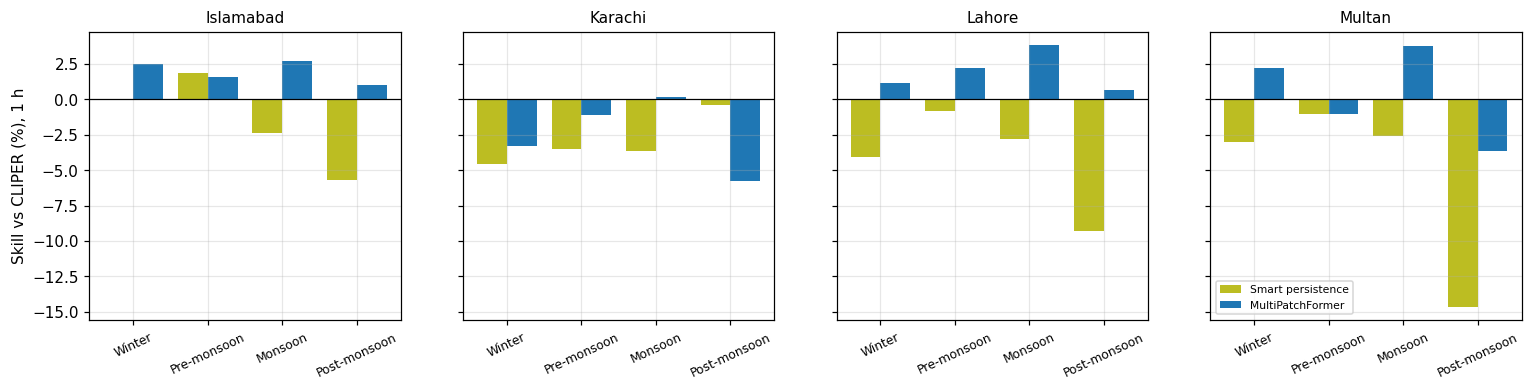

**02_T16_rmse_by_sky_H1 — RMSE (W/m²) by sky, horizon 1 h**

model,Region,label,forecasts,CLIPER,MultiPatchFormer,Smart persistence
0,Islamabad,Clear (k≥0.8),3103,35.5000,33.4000,35.7400
1,Islamabad,Cloudy (k<0.5),505,80.5000,81.0600,73.5000
2,Islamabad,Partly cloudy (0.5–0.8),713,99.4700,97.8300,104.5000
3,Karachi,Clear (k≥0.8),3190,34.8800,34.9800,36.7100
4,Karachi,Cloudy (k<0.5),278,91.1700,91.2500,85.2200
5,Karachi,Partly cloudy (0.5–0.8),517,97.6800,98.7100,104.3200
6,Lahore,Clear (k≥0.8),3002,36.3500,35.5600,37.3400
7,Lahore,Cloudy (k<0.5),335,89.1800,87.3800,84.1700
8,Lahore,Partly cloudy (0.5–0.8),963,93.2000,89.6700,97.9500
9,Multan,Clear (k≥0.8),3355,31.2800,30.6900,32.5200


**02_T16_skill_by_sky_H1 — Skill vs CLIPER (%) by sky, horizon 1 h**

model,Region,label,CLIPER,MultiPatchFormer,Smart persistence
0,Islamabad,Clear (k≥0.8),0.0000,5.9000,-0.7000
1,Islamabad,Cloudy (k<0.5),0.0000,-0.7000,8.7000
2,Islamabad,Partly cloudy (0.5–0.8),0.0000,1.7000,-5.0000
3,Karachi,Clear (k≥0.8),0.0000,-0.3000,-5.2000
4,Karachi,Cloudy (k<0.5),0.0000,-0.1000,6.5000
5,Karachi,Partly cloudy (0.5–0.8),0.0000,-1.1000,-6.8000
6,Lahore,Clear (k≥0.8),0.0000,2.2000,-2.7000
7,Lahore,Cloudy (k<0.5),0.0000,2.0000,5.6000
8,Lahore,Partly cloudy (0.5–0.8),0.0000,3.8000,-5.1000
9,Multan,Clear (k≥0.8),0.0000,1.9000,-4.0000


*02_F15b_skill_by_sky_H1 — Skill by sky, horizon 1 h*

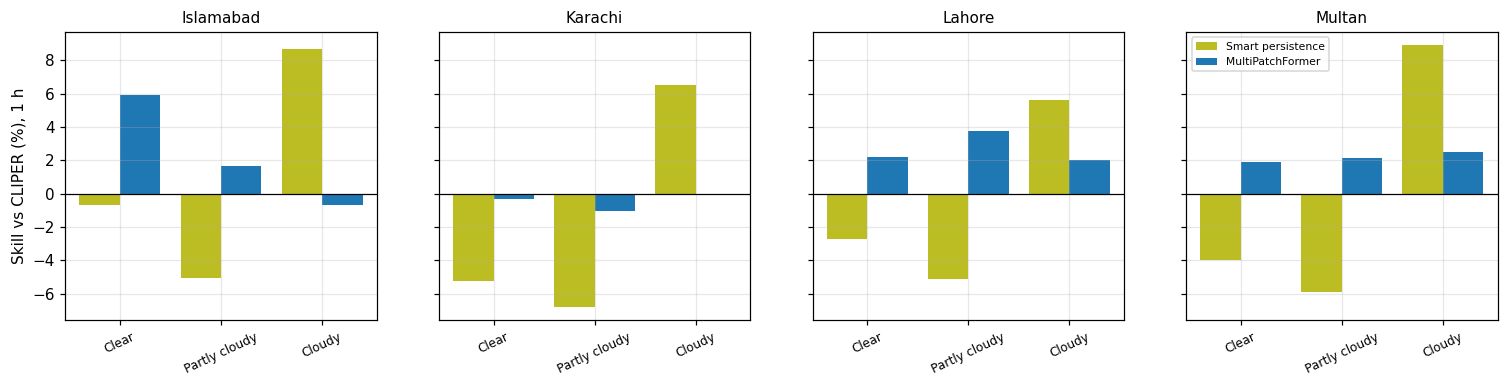

*02_F16b_error_by_hour_and_month_H1 — RMSE and bias by hour of day, and RMSE by month — horizon 1 h*

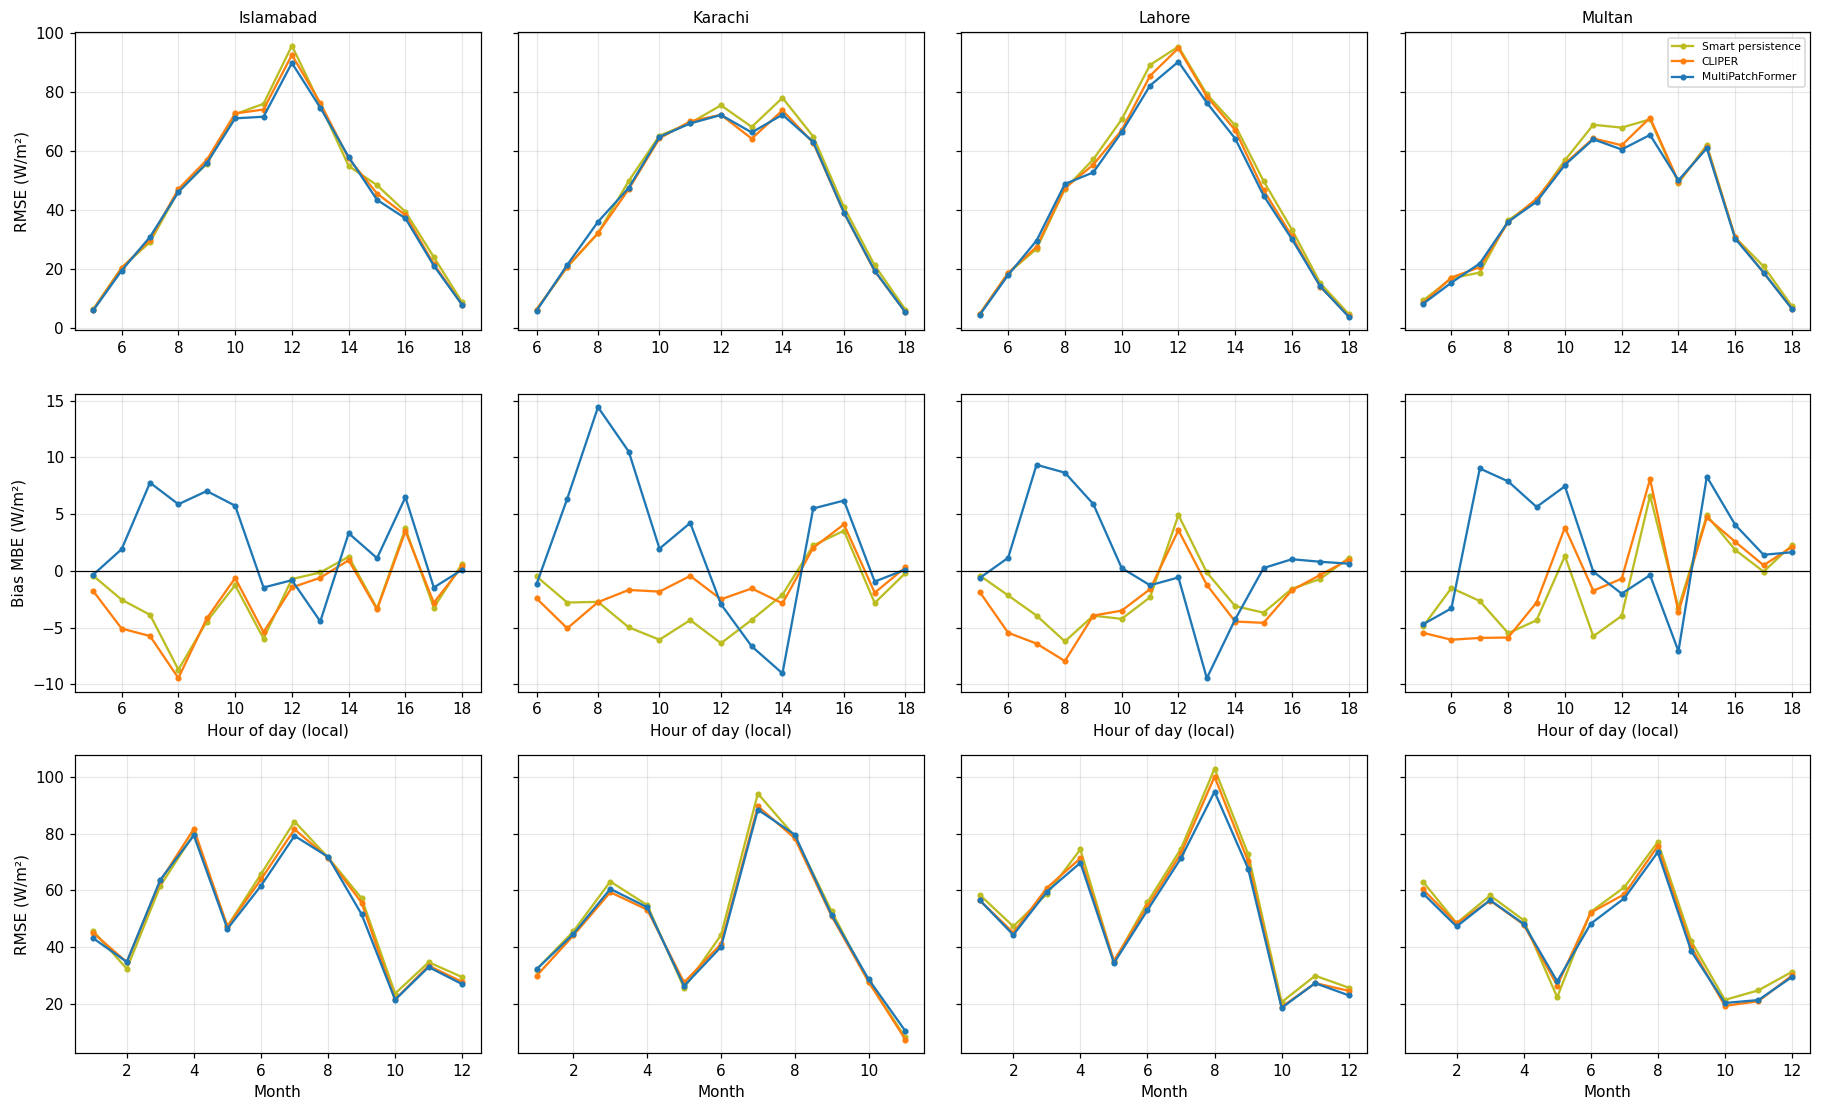

*02_F17b_scatter_H1 — Forecast vs observed GHI, horizon 1 h (daytime hours, colour = log count)*

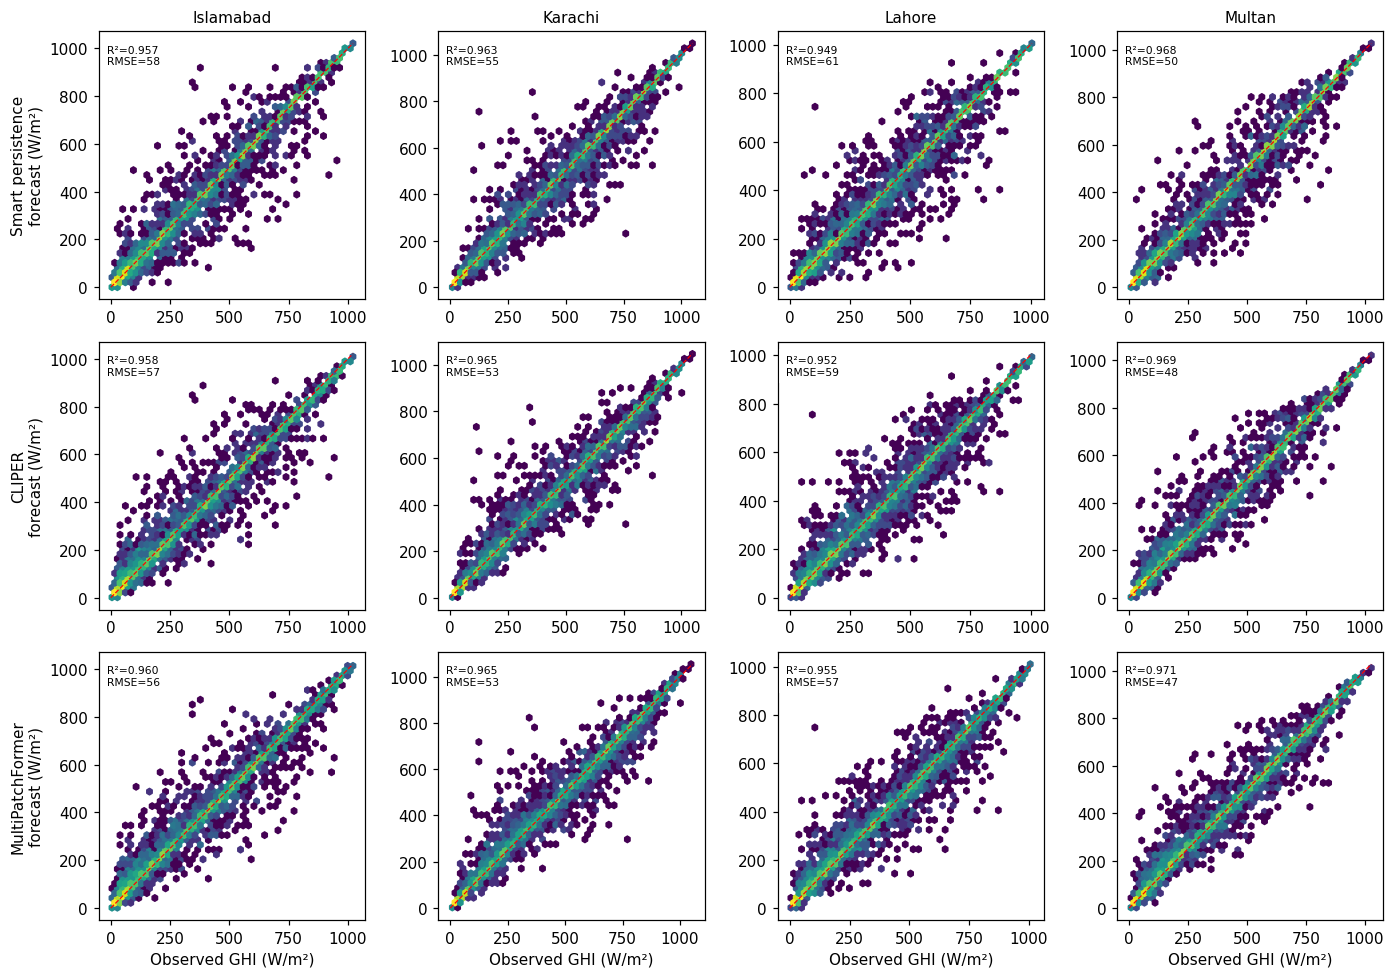

*02_F18b_error_distribution_H1 — Distribution of errors, horizon 1 h (daytime hours)*

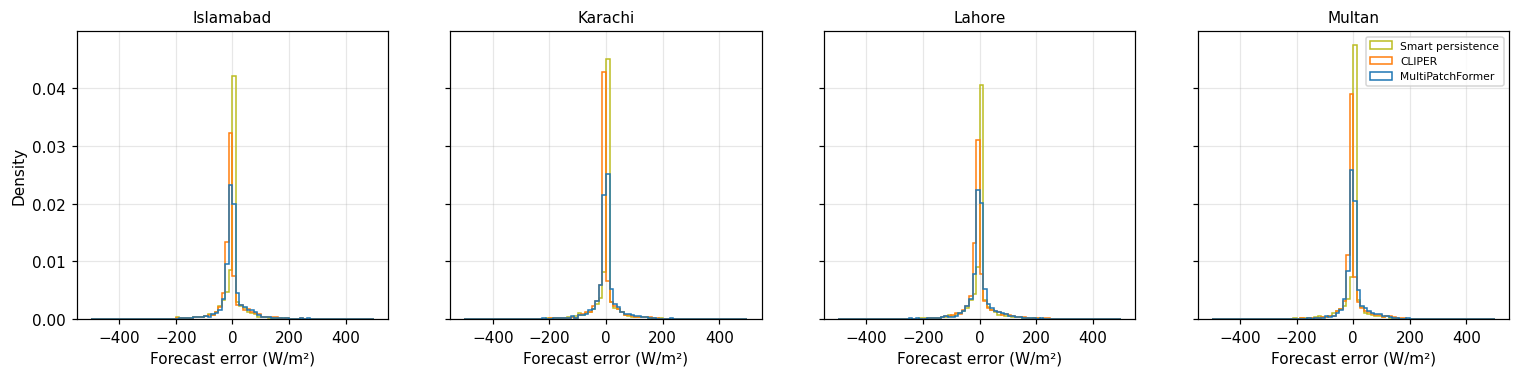

*02_F19b_example_forecasts_H6 — Example forecasts, horizon 6 h: clearest and cloudiest test periods*

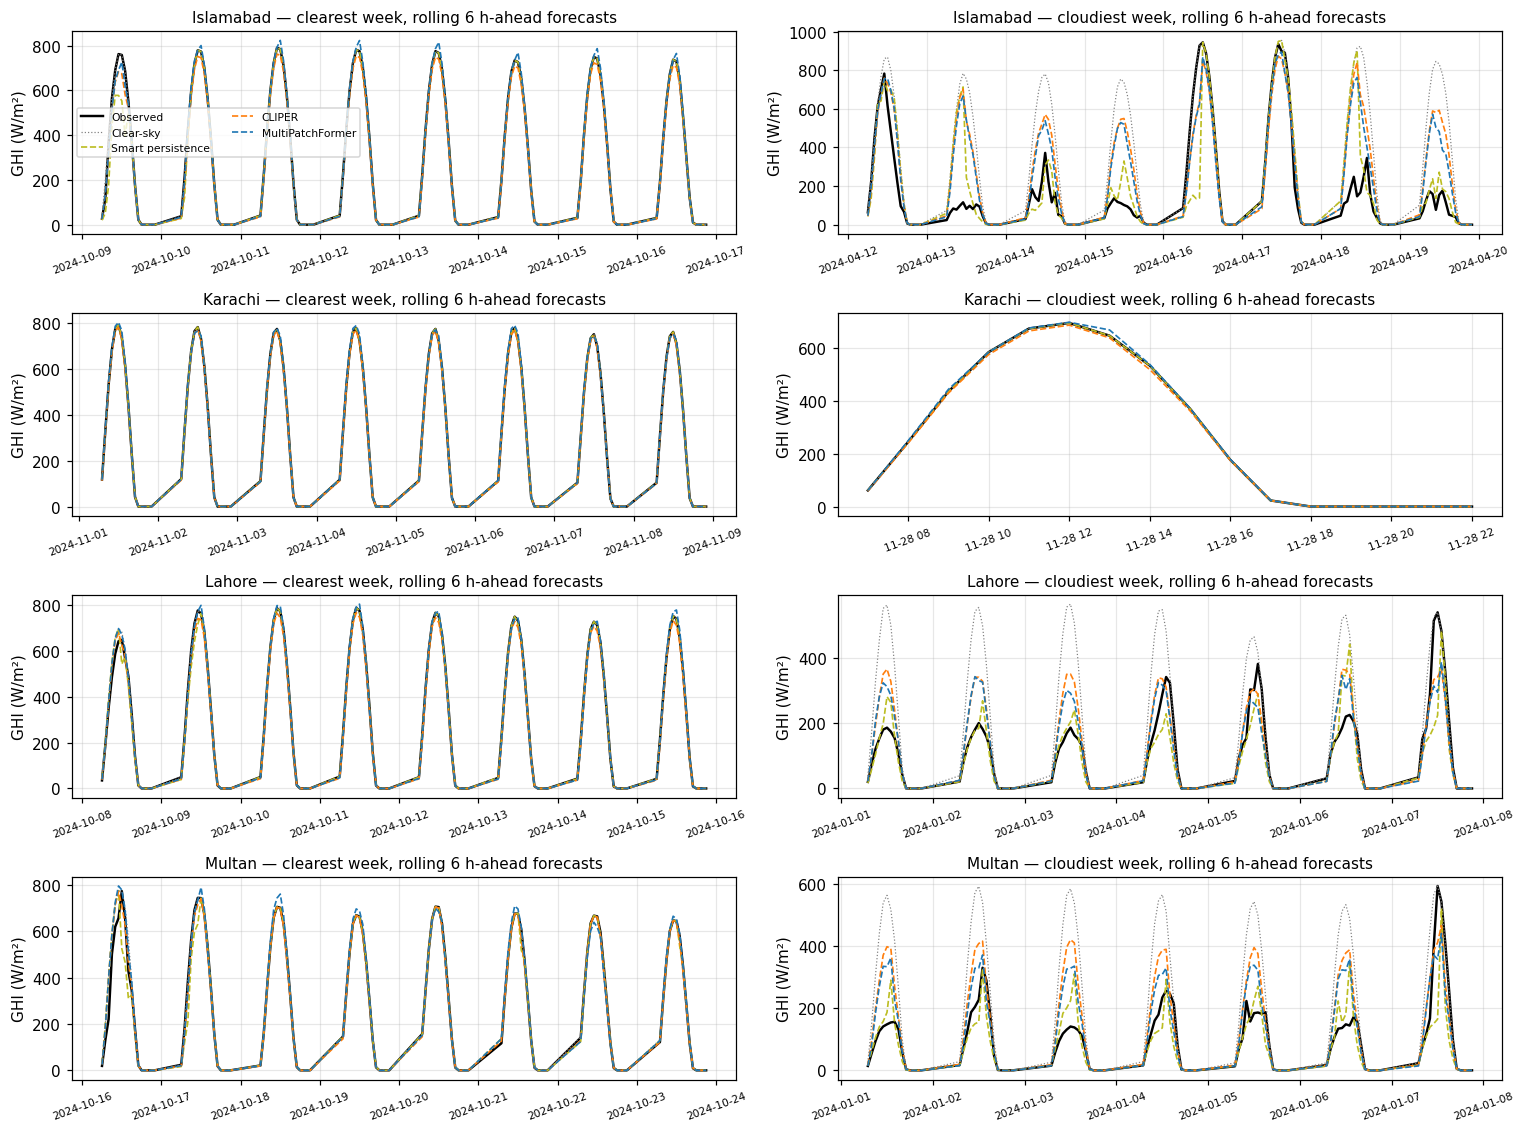

In [21]:
HI = CFG["INTRADAY_BREAKDOWN_HORIZON"]
LH = lead_hour_analysis(ALLM)
BRK_I = breakdown_analysis(["Smart persistence", "CLIPER"] + MAIN, H=HI, name="F15b")
hour_month_analysis(["Smart persistence", "CLIPER"] + MAIN, H=HI, name="F16b")
fig_scatter(["Smart persistence", "CLIPER"] + MAIN, H=HI, name="F17b")
fig_error_hist(["Smart persistence", "CLIPER"] + MAIN, H=HI, name="F18b")
fig_examples(["Smart persistence", "CLIPER"] + MAIN, H=max(INTRADAY_H), name="F19b")

### Seed ensemble (mean of the seed forecasts) — usually a little better than a single model

In [22]:
ENS = ensemble_table(MAIN)

**02_T10e_seed_ensemble_skill — Skill vs CLIPER (%) of the seed ensemble (mean of the seed forecasts)**

model,Region,H,MultiPatchFormer
0,Islamabad,1,2.2500
1,Islamabad,3,3.0600
2,Islamabad,6,3.9800
3,Islamabad,24,2.2600
4,Islamabad,96,1.3600
5,Islamabad,168,0.4700
6,Islamabad,336,0.4200
7,Islamabad,672,0.3500
8,Karachi,1,-0.5900
9,Karachi,3,-0.1000


**02_T14_diebold_mariano — Diebold–Mariano tests: negative DM = MultiPatchFormer has lower error (per-forecast MSE averaged over seeds, two-sided; overlap of consecutive forecasts handled with a Newey–West variance)**

,Region,H,comparison,DM,p_value,result
0,Islamabad,1,MultiPatchFormer vs Seasonal persistence,-22.5578,0.0000,better (p<0.05)
1,Islamabad,1,MultiPatchFormer vs Smart persistence,-2.2034,0.0276,better (p<0.05)
2,Islamabad,1,MultiPatchFormer vs Climatology,-22.5753,0.0000,better (p<0.05)
3,Islamabad,1,MultiPatchFormer vs CLIPER,-2.3119,0.0208,better (p<0.05)
4,Islamabad,3,MultiPatchFormer vs Seasonal persistence,-14.0789,0.0000,better (p<0.05)
5,Islamabad,3,MultiPatchFormer vs Smart persistence,-3.3417,0.0008,better (p<0.05)
6,Islamabad,3,MultiPatchFormer vs Climatology,-13.1815,0.0000,better (p<0.05)
7,Islamabad,3,MultiPatchFormer vs CLIPER,-2.9868,0.0028,better (p<0.05)
8,Islamabad,6,MultiPatchFormer vs Seasonal persistence,-11.9610,0.0000,better (p<0.05)
9,Islamabad,6,MultiPatchFormer vs Smart persistence,-6.0438,0.0000,better (p<0.05)


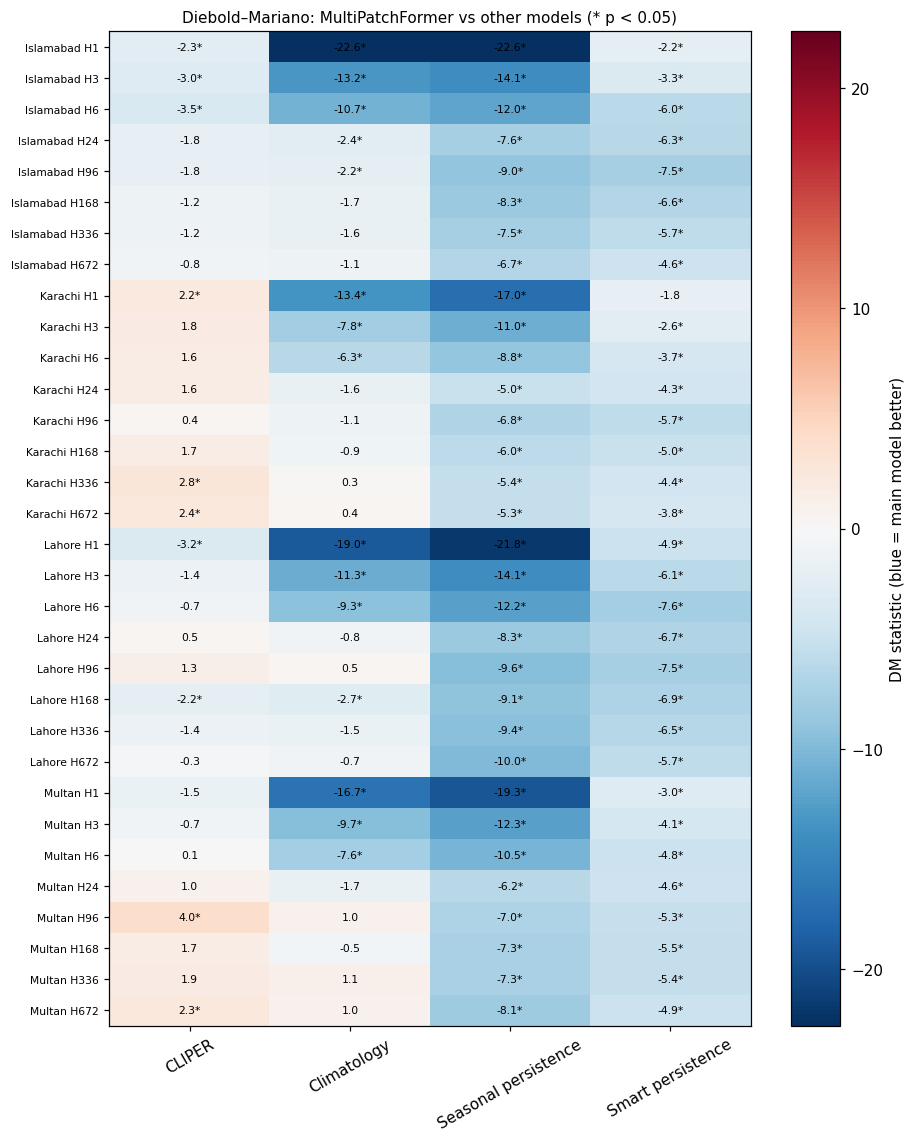

In [23]:
DMT = dm_analysis(CFG["MAIN_MODEL"], ["Seasonal persistence", "Smart persistence", "Climatology", "CLIPER"])

## Part 12 — Ablation study (all cities, two horizons, all seeds, parameter counts)
Each component is removed in turn: multi-scale embedding (→ one 24-h scale), channel-wise attention (→ linear reduction only) and the
multi-step decoder (→ one linear output layer). The input length is the one selected for the full model. One intraday (6 h) and one
day-ahead (24 h) horizon are used.

  ablation: 10/24 | elapsed 4.5 min | est. remaining 6.3 min
  ablation: 20/24 | elapsed 9.9 min | est. remaining 2.0 min
  ablation: 24/24 | elapsed 12.7 min | est. remaining 0.0 min


**02_T17_ablation — Ablation (mean over seeds). params = trainable parameters; dRMSE = change vs the full model**

,Region,H,L,variant,params,RMSE,MAE,MBE,R2,Skill_pct,RMSE_std,dRMSE_vs_full_pct
0,Islamabad,6,72,full,648594,103.3350,58.5520,3.4080,0.8640,2.8430,0.2600,0.0000
1,Islamabad,6,72,no_multiscale,651282,103.5850,59.1050,3.2100,0.8630,2.6080,0.5180,0.2420
2,Islamabad,6,72,no_channel_attention,516114,103.1950,58.3090,4.4780,0.8640,2.9750,0.5340,-0.1360
3,Islamabad,6,72,no_multistep_decoder,648582,103.0690,58.0980,4.3410,0.8650,3.0930,0.6610,-0.2580
4,Karachi,6,72,full,648594,82.2210,44.4750,3.5060,0.9150,-1.1080,0.3700,0.0000
5,Karachi,6,72,no_multiscale,651282,82.6730,45.6000,4.8370,0.9150,-1.6640,0.6010,0.5500
6,Karachi,6,72,no_channel_attention,516114,82.1810,45.0590,4.4410,0.9160,-1.0590,0.7170,-0.0490
7,Karachi,6,72,no_multistep_decoder,648582,82.9090,44.5950,8.1220,0.9140,-1.9540,0.9750,0.8370
8,Lahore,6,72,full,648594,95.1320,55.0050,-1.9640,0.8750,0.5000,0.4390,0.0000
9,Lahore,6,72,no_multiscale,651282,95.0090,55.1840,-0.9610,0.8750,0.6290,0.6210,-0.1290


**02_T17b_ablation_city_average — Ablation averaged over the four cities**

,H,variant,params,RMSE,Skill_pct,dRMSE_vs_full_pct
0,6,full,"648,594.0000",89.9840,0.5190,0.0000
1,6,no_channel_attention,"516,114.0000",89.6090,0.9370,-0.4200
2,6,no_multiscale,"651,282.0000",90.0620,0.4390,0.0800
3,6,no_multistep_decoder,"648,582.0000",89.9350,0.5480,-0.0340
4,24,full,"747,120.0000",109.8000,-0.4820,0.0000
5,24,no_channel_attention,"614,640.0000",109.3470,-0.0870,-0.3950
6,24,no_multiscale,"749,808.0000",109.3170,-0.0470,-0.4330
7,24,no_multistep_decoder,"746,904.0000",109.3630,-0.0430,-0.4340


*02_F23_ablation — Ablation: test RMSE of the full model and of each variant (error bars = std over seeds)*

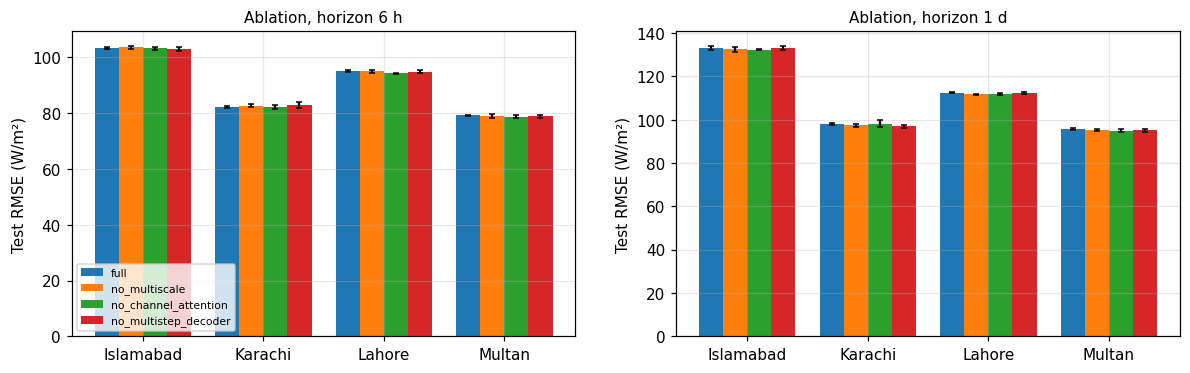

In [24]:
abl_jobs, abl_meta = [], []
for H in CFG["ABLATION_HORIZONS"]:
    for trc, tec in train_groups():
        L = BEST_L[(CFG["MAIN_MODEL"], tec[0], H)]
        for v in VARIANTS:
            for s_ in CFG["SEEDS"]:
                abl_jobs.append(dict(model_name=CFG["MAIN_MODEL"], L=L, H=H, seed=s_, variant=v, train_cities=trc, test_cities=tec))
                abl_meta.append((H, L, v, s_, tec))
abl_res = run_jobs(abl_jobs, "ablation")
abl_rows = []
for (H, L, v, s_, tec), (rec, ks) in zip(abl_meta, abl_res):
    for c in tec:
        _, y, cs, m = test_targets(c, H)
        cl = metrics(y, PRED[("CLIPER", c, H)][0], m)["RMSE"]
        sc = score(c, H, ks[c])
        abl_rows.append(dict(Region=c, H=H, L=L, variant=v, seed=s_, params=rec["params"], train_time_s=rec["train_time_s"],
                             Skill_pct=100 * (1 - sc["RMSE"] / cl), **sc))
ABL = pd.DataFrame(abl_rows)
ag = ABL.groupby(["Region", "H", "L", "variant"])
abl_tab = ag[["params"]].first().join(ag[["RMSE", "MAE", "MBE", "R2", "Skill_pct"]].mean()) \
            .join(ag[["RMSE"]].std().rename(columns={"RMSE": "RMSE_std"})).reset_index()
full_rmse = abl_tab[abl_tab.variant == "full"].set_index(["Region", "H"])["RMSE"]
abl_tab["dRMSE_vs_full_pct"] = [100 * (r.RMSE / full_rmse[(r.Region, r.H)] - 1) for r in abl_tab.itertuples()]
abl_tab["_o"] = [list(VARIANTS).index(v) for v in abl_tab.variant]
abl_tab = abl_tab.sort_values(["H", "Region", "_o"]).drop(columns="_o").round(3)
abl_tab.to_csv(OUT / "predictions" / "ablation.csv", index=False)
save_table(abl_tab, f"{P}_T17_ablation", caption="Ablation (mean over seeds). params = trainable parameters; dRMSE = change vs the full model")
avg = abl_tab.groupby(["H", "variant"])[["params", "RMSE", "Skill_pct", "dRMSE_vs_full_pct"]].mean().reset_index()
save_table(avg.round(3), f"{P}_T17b_ablation_city_average", caption="Ablation averaged over the four cities")

fig, axes = grid(1, len(CFG["ABLATION_HORIZONS"]), w=6.5, h=3.6)
vs = list(VARIANTS)
vcol = {"full": "#1f77b4", "no_multiscale": "#ff7f0e", "no_channel_attention": "#2ca02c", "no_multistep_decoder": "#d62728"}
for ax, H in zip(axes[0], CFG["ABLATION_HORIZONS"]):
    w = 0.8 / len(vs)
    for j, v in enumerate(vs):
        g = ABL[(ABL.H == H) & (ABL.variant == v)].groupby("Region")["RMSE"]
        ax.bar(np.arange(len(CITIES)) + (j - (len(vs) - 1) / 2) * w, g.mean().reindex(CITIES), w,
               yerr=g.std().reindex(CITIES).fillna(0), capsize=2, label=v, color=vcol[v])
    ax.set_xticks(range(len(CITIES))); ax.set_xticklabels(CITIES)
    ax.set(title=f"Ablation, horizon {hlabel(H)}", ylabel="Test RMSE (W/m²)")
axes[0, 0].legend(fontsize=7)
save_fig(fig, f"{P}_F23_ablation", "Ablation: test RMSE of the full model and of each variant (error bars = std over seeds)")

## Part 13 — Blind test on an unseen city (leave-one-city-out)
The model is trained and early-stopped on the other three cities only (inputs standardised with their statistics, input length = most
common choice of those cities) and then tested on the held-out city's 2024 data. This tests whether the model is location-locked.

  blind test: 10/24 | elapsed 6.1 min | est. remaining 8.5 min
  blind test: 20/24 | elapsed 12.7 min | est. remaining 2.5 min
  blind test: 24/24 | elapsed 15.4 min | est. remaining 0.0 min


**02_T18_blind_test_unseen_city — Leave-one-city-out: the model never saw the test city (mean over seeds)**

,Region,H,L,trained_on,blind_RMSE,local_RMSE,CLIPER_RMSE,blind_Skill_pct,local_Skill_pct,blind_R2,local_R2,blind_minus_local_pct
0,Islamabad,6,72,"Karachi,Lahore,Multan",107.8300,103.3350,106.3590,-1.3830,2.8430,0.8520,0.8640,4.3490
1,Islamabad,24,96,"Karachi,Lahore,Multan",137.7610,133.1990,135.2840,-1.8310,1.5410,0.7580,0.7740,3.4250
2,Karachi,6,72,"Islamabad,Lahore,Multan",87.5540,82.2210,81.3200,-7.6670,-1.1080,0.9040,0.9150,6.4870
3,Karachi,24,96,"Islamabad,Lahore,Multan",106.2680,97.8250,96.3060,-10.3450,-1.5770,0.8590,0.8800,8.6310
4,Lahore,6,72,"Islamabad,Karachi,Multan",95.6950,95.1320,95.6110,-0.0880,0.5010,0.8730,0.8750,0.5920
5,Lahore,24,96,"Islamabad,Karachi,Multan",113.8280,112.4470,111.8950,-1.7280,-0.4930,0.8210,0.8250,1.2280
6,Multan,6,72,"Islamabad,Karachi,Lahore",81.0770,79.2500,79.1230,-2.4690,-0.1600,0.9140,0.9180,2.3060
7,Multan,24,96,"Islamabad,Karachi,Lahore",100.8130,95.7330,94.4090,-6.7830,-1.4020,0.8670,0.8800,5.3070


*02_F24_blind_test — Blind test on an unseen city vs a model trained on that city*

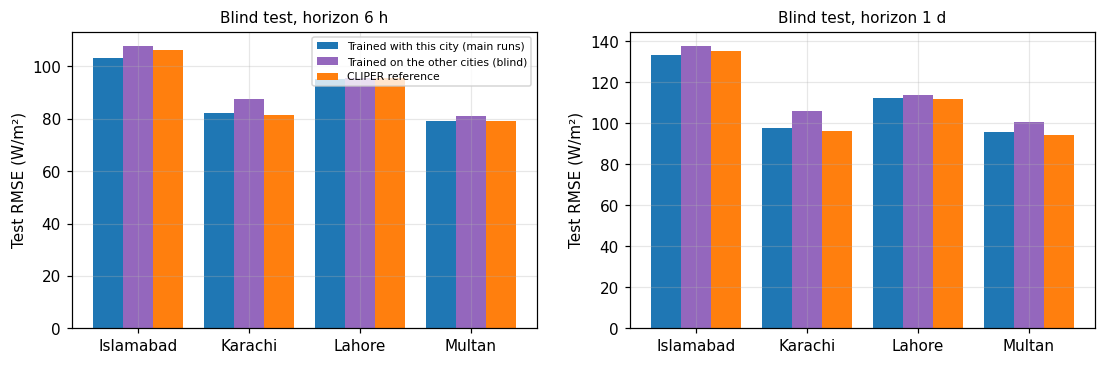

In [25]:
loco_rows = []
if len(CITIES) >= 2:
    loco_jobs, loco_meta = [], []
    for c in CITIES:
        others = [o for o in CITIES if o != c]
        for H in CFG["LOCO_HORIZONS"]:
            Ls = [BEST_L[(CFG["MAIN_MODEL"], o, H)] for o in others]
            L = max(set(Ls), key=Ls.count)              # input length of the training cities (no test-city information)
            for si, s_ in enumerate(CFG["SEEDS"]):
                loco_jobs.append(dict(model_name=CFG["MAIN_MODEL"], L=L, H=H, seed=s_, train_cities=others, test_cities=[c], scope="loco"))
                loco_meta.append((c, H, L, si, s_, others))
    loco_res = run_jobs(loco_jobs, "blind test")
    for (c, H, L, si, s_, others), (rec, ks) in zip(loco_meta, loco_res):
        _, y, cs, m = test_targets(c, H)
        cl = metrics(y, PRED[("CLIPER", c, H)][0], m)["RMSE"]
        sc = score(c, H, ks[c])
        loc = metrics(y, PRED[(CFG["MAIN_MODEL"], c, H)][si], m)
        loco_rows.append(dict(Region=c, H=H, L=L, seed=s_, trained_on=",".join(others), blind_RMSE=sc["RMSE"],
                              local_RMSE=loc["RMSE"], CLIPER_RMSE=cl, blind_Skill_pct=100 * (1 - sc["RMSE"] / cl),
                              local_Skill_pct=100 * (1 - loc["RMSE"] / cl), blind_R2=sc["R2"], local_R2=loc["R2"]))
    LOCO = pd.DataFrame(loco_rows)
    lt = LOCO.groupby(["Region", "H", "L", "trained_on"])[["blind_RMSE", "local_RMSE", "CLIPER_RMSE", "blind_Skill_pct",
                                                         "local_Skill_pct", "blind_R2", "local_R2"]].mean().reset_index()
    lt["blind_minus_local_pct"] = 100 * (lt.blind_RMSE / lt.local_RMSE - 1)
    lt = lt.round(3)
    lt.to_csv(OUT / "predictions" / "blind_test.csv", index=False)
    save_table(lt, f"{P}_T18_blind_test_unseen_city", caption="Leave-one-city-out: the model never saw the test city (mean over seeds)")
    fig, axes = grid(1, len(CFG["LOCO_HORIZONS"]), w=6, h=3.5)
    for ax, H in zip(axes[0], CFG["LOCO_HORIZONS"]):
        t = lt[lt.H == H].set_index("Region").reindex(CITIES)
        x = np.arange(len(CITIES))
        ax.bar(x - 0.27, t.local_RMSE, 0.27, label="Trained with this city (main runs)", color="#1f77b4")
        ax.bar(x, t.blind_RMSE, 0.27, label="Trained on the other cities (blind)", color="#9467bd")
        ax.bar(x + 0.27, t.CLIPER_RMSE, 0.27, label="CLIPER reference", color="#ff7f0e")
        ax.set_xticks(x); ax.set_xticklabels(CITIES); ax.set(title=f"Blind test, horizon {hlabel(H)}", ylabel="Test RMSE (W/m²)")
    axes[0, 0].legend(fontsize=7)
    save_fig(fig, f"{P}_F24_blind_test", "Blind test on an unseen city vs a model trained on that city")

## Part 14 — Operational test: what happens if one input variable is missing at forecast time
The trained model (seed 0) is applied to the test year with one input replaced by its training mean, as an operational fallback.

**02_T19_missing_variable_test — Increase in test RMSE (%) when one input is unavailable (replaced by its training mean)**

,missing_input,6_Islamabad,6_Karachi,6_Lahore,6_Multan,24_Islamabad,24_Karachi,24_Lahore,24_Multan
0,air_temp,0.2500,0.1500,0.4200,-0.0200,0.3600,-0.9000,0.4800,-0.6000
1,clearsky_ghi,0.6400,1.1500,0.1500,0.5800,0.4100,0.4600,0.2900,-0.2700
2,dhi,-0.1800,-0.2600,-0.0700,-0.1500,-0.0800,0.1700,0.0800,0.2700
3,dni,0.3200,-0.0100,0.1900,0.1400,0.3300,0.6100,-0.2200,0.9500
4,doy_cos,0.2600,0.2300,0.0100,-0.0100,0.3300,-0.1300,0.1000,-0.1800
5,doy_sin,0.3700,0.5700,0.1000,0.4200,2.2500,5.4300,2.4900,4.2200
6,gti,0.1500,0.3200,-0.1400,0.1700,0.1900,0.1000,0.1900,0.0100
7,hour_cos,-0.1000,0.0700,-0.0000,-0.1300,0.0200,0.0700,-0.0100,-0.1200
8,hour_sin,-0.0800,-0.0800,-0.0600,-0.1000,-0.0200,-0.1600,-0.0400,-0.1000
9,k,29.9900,24.6400,18.1900,26.2400,2.0900,5.8900,1.0600,5.1300


**02_T19b_missing_variable_skill — Skill vs CLIPER (%) with one input missing — positive = still better than the reference**

,missing_input,6_Islamabad,6_Karachi,6_Lahore,6_Multan,24_Islamabad,24_Karachi,24_Lahore,24_Multan
0,air_temp,2.3400,-1.5100,-0.4200,0.1200,0.5500,-0.1500,-1.2000,-0.2500
1,clearsky_ghi,1.9500,-2.5300,-0.1500,-0.4700,0.5000,-1.5200,-1.0100,-0.5800
2,dhi,2.7600,-1.1000,0.0700,0.2500,1.0000,-1.2400,-0.8000,-1.1300
3,dni,2.2700,-1.3500,-0.1900,-0.0400,0.5900,-1.6800,-0.5000,-1.8200
4,doy_cos,2.3300,-1.6000,-0.0100,0.1100,0.5900,-0.9300,-0.8200,-0.6700
5,doy_sin,2.2200,-1.9400,-0.1000,-0.3200,-1.3200,-6.5500,-3.2200,-5.1200
6,gti,2.4300,-1.6900,0.1300,-0.0700,0.7300,-1.1700,-0.9100,-0.8700
7,hour_cos,2.6800,-1.4400,-0.0000,0.2300,0.8900,-1.1300,-0.7000,-0.7400
8,hour_sin,2.6500,-1.2900,0.0600,0.2000,0.9300,-0.9000,-0.6700,-0.7600
9,k,-26.6300,-26.3400,-18.2000,-26.1100,-1.1600,-7.0100,-1.7800,-6.0300


*02_F25_missing_variable — RMSE increase when one input is missing at forecast time (red = more than 5 %)*

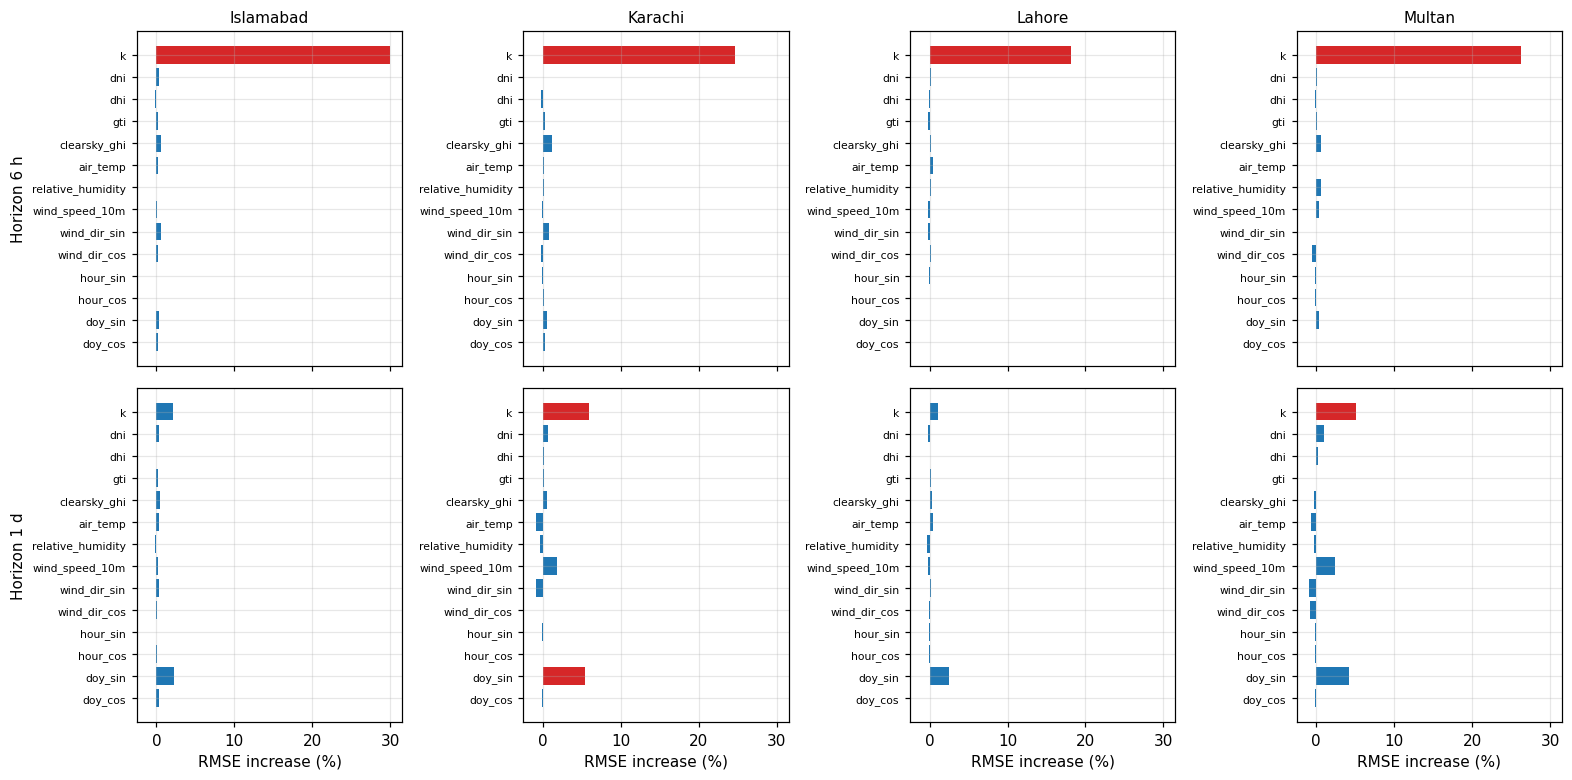

In [26]:
rob_rows = []
for c in CITIES:
    for H in CFG["ROBUST_HORIZONS"]:
        L = BEST_L[(CFG["MAIN_MODEL"], c, H)]
        tag = "all" if CFG["TRAINING_MODE"] == "global" else c
        wpath = OUT / "weights" / f"{CFG['MAIN_MODEL']}_{tag}_L{L}_H{H}_s{CFG['SEEDS'][0]}.pt"
        if not wpath.exists():
            print("Weights not found (run was resumed without weights):", wpath.name); continue
        dev = DEVICES[0]
        net = build_model(CFG["MAIN_MODEL"], L, H).to(dev)
        net.load_state_dict(torch.load(wpath, map_location=dev))
        bank = get_bank(sorted(CITIES), sorted(CITIES), dev) if CFG["TRAINING_MODE"] == "global" else get_bank([c], [c], dev)
        te = bank.idx(c, "test", L, H)
        _, y, cs, m = test_targets(c, H)
        cl = metrics(y, PRED[("CLIPER", c, H)][0], m)["RMSE"]
        base = score(c, H, predict(net, bank, te, L, H))["RMSE"]
        rob_rows.append(dict(Region=c, H=H, missing_input="none", RMSE=base, dRMSE_pct=0.0, Skill_pct=100 * (1 - base / cl)))
        for ch, f in enumerate(FEATURES):
            r = score(c, H, predict(net, bank, te, L, H, drop_channel=ch))["RMSE"]
            rob_rows.append(dict(Region=c, H=H, missing_input=f, RMSE=r, dRMSE_pct=100 * (r / base - 1), Skill_pct=100 * (1 - r / cl)))
ROB = pd.DataFrame(rob_rows)
ROB.round(3).to_csv(OUT / "predictions" / "missing_variable.csv", index=False)
save_table(ROB.pivot_table(index=["missing_input"], columns=["H", "Region"], values="dRMSE_pct").round(2).reset_index(),
           f"{P}_T19_missing_variable_test", caption="Increase in test RMSE (%) when one input is unavailable (replaced by its training mean)")
save_table(ROB.pivot_table(index=["missing_input"], columns=["H", "Region"], values="Skill_pct").round(2).reset_index(),
           f"{P}_T19b_missing_variable_skill", caption="Skill vs CLIPER (%) with one input missing — positive = still better than the reference")
fig, axes = grid(len(CFG["ROBUST_HORIZONS"]), len(CITIES), w=3.6, h=3.6, sharex=True)
for i_, H in enumerate(CFG["ROBUST_HORIZONS"]):
    for j, c in enumerate(CITIES):
        t = ROB[(ROB.Region == c) & (ROB.H == H) & (ROB.missing_input != "none")].set_index("missing_input").reindex(FEATURES[::-1])
        axes[i_, j].barh(t.index, t.dRMSE_pct, color=np.where(t.dRMSE_pct > 5, "#d62728", "#1f77b4"))
        axes[i_, j].tick_params(axis="y", labelsize=7)
        if i_ == 0: axes[i_, j].set_title(c)
        if j == 0: axes[i_, j].set_ylabel(f"Horizon {hlabel(H)}")
        if i_ == len(CFG["ROBUST_HORIZONS"]) - 1: axes[i_, j].set_xlabel("RMSE increase (%)")
fig.tight_layout()
save_fig(fig, f"{P}_F25_missing_variable", "RMSE increase when one input is missing at forecast time (red = more than 5 %)")

## Part 15 — Compute cost (time to issue a forecast, training time)

**02_T20_compute_time — Compute cost on Tesla T4 x2: time to issue one forecast and training time per run**

,model,device,L,H,params,ms_per_forecast_median,mean_train_time_s,max_train_time_s,mean_best_epoch
0,MultiPatchFormer,cuda,24,1,507521,1.4910,255.6170,793.8630,5.6670
1,MultiPatchFormer,cpu,24,1,507521,2.9790,255.6170,793.8630,5.6670
2,MultiPatchFormer,cuda,672,672,3663264,2.1100,255.6170,793.8630,5.6670
3,MultiPatchFormer,cpu,672,672,3663264,12.7810,255.6170,793.8630,5.6670


*02_F09_compute_time — Training time and time to issue one forecast*

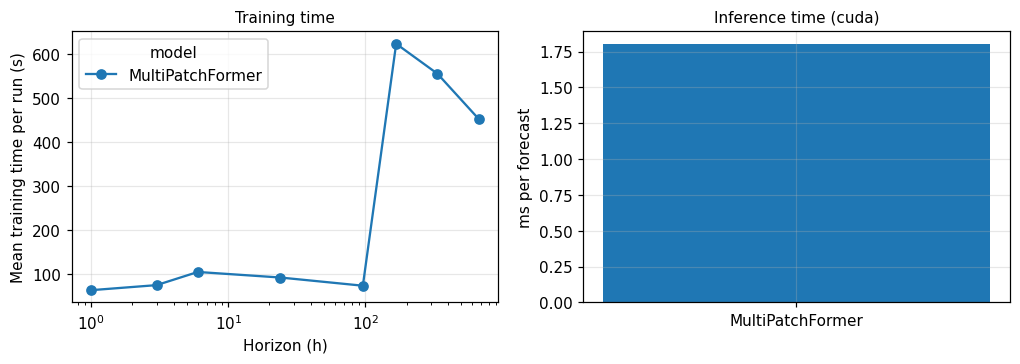

GPU: **Tesla T4 x2**. A forecast takes milliseconds, so no extra lead time has to be added to the verification horizon.

In [27]:
compute_time_table(MAIN, FR)
show_md(f"GPU: **{env_info['gpu']}**. A forecast takes milliseconds, so no extra lead time has to be added to the verification horizon.")

## Part 16 — Save everything
The `outputs/predictions` folder holds the test-year forecasts used for the final model comparison.

In [28]:
export_all()
display(NUM[NUM.H.isin([1, 24])][["Region", "H", "model", "RMSE", "Skill_pct", "Skill_SP_pct", "R2"]].round(3).reset_index(drop=True))

Excel workbook written: /kaggle/working/outputs/tables/ALL_TABLES_02_multipatchformer.xlsx
39 tables and 30 figures saved in /kaggle/working/outputs | run time 120.8 min


,Region,H,model,RMSE,Skill_pct,Skill_SP_pct,R2
0,Islamabad,1,CLIPER,57.4020,0.0000,0.8340,0.9580
1,Islamabad,1,Climatology,139.0270,-142.1990,-140.1790,0.7540
2,Islamabad,1,MultiPatchFormer,56.5520,1.4810,2.3030,0.9590
3,Islamabad,1,Seasonal persistence,184.4320,-221.3000,-218.6210,0.5660
4,Islamabad,1,Smart persistence,57.8850,-0.8410,0.0000,0.9570
5,Islamabad,24,CLIPER,135.2840,0.0000,22.5270,0.7670
6,Islamabad,24,Climatology,139.0270,-2.7670,20.3840,0.7540
7,Islamabad,24,MultiPatchFormer,133.1990,1.5410,23.7210,0.7740
8,Islamabad,24,Seasonal persistence,184.4320,-36.3300,-5.6180,0.5660
9,Islamabad,24,Smart persistence,174.6220,-29.0780,0.0000,0.6110
